<a href="https://colab.research.google.com/github/francji1/01ADS/blob/main/lectures/L07_sentence_embeddings/01ADS_L07_Sentence_Embeddings_extended.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01ADS - Lecture 07: Contextual and sentence embeddings, semantic search (extended version)

*This is the revised and extended version of the lecture notebook. The original version shown in the lecture is
[01ADS_L07_Sentence_Embeddings.ipynb](01ADS_L07_Sentence_Embeddings.ipynb); this one corrects several statements, adds
figures and small experiments, and marks the extra material as optional.*

Lecture 06 ended with the transformer as a family: encoders that fill in masked words, decoders that predict the next
token, and the contextual vector of *bank* that differs between a river and a savings account. Today we use these
models for real work. First, how a decoder turns next-token probabilities into text (and what temperature and top-p
actually do). Then the main question of the lecture: **how do we get one good vector for a whole sentence?** Pooling
the hidden states of a language model gives *a* vector, but not one whose cosine means what we want; a short
contrastive fine-tuning changes that, and we will do it live and measure the difference on a search benchmark.
Finally, a small Czech encoder is fine-tuned for a classification task, in the three regimes you know from transfer
learning on images.

Running examples: Quora questions (search), STS-B sentence pairs (similarity judged by people), Czech film reviews
from ČSFD (classification).

**The idea of the whole lecture in one sentence.** The *architecture* decides how information flows between tokens;
*pooling* decides how one vector is read out; the *training objective and data* decide what "similar" means; an
optional *projection head* can change the dimension and the geometry; the *scoring function* (cosine, MaxSim)
compares two representations; an *evaluation metric* (Spearman, recall@k, nDCG) judges the result against human
labels.

**After the lecture you should be able to answer:**
1. What is the difference between a static token embedding, a contextual token state and a sentence embedding?
2. Why do an encoder and a causal decoder both produce one hidden state per token, and how does their context differ?
3. What are the backbone, the pooling, the LM head and the projection head, and which of them are trained?
4. How can the `[CLS]` or the last token represent a whole sentence, and when is that not enough?
5. Why does pooling the outputs of an ordinary language model not guarantee a good similarity?
6. How does contrastive learning change the geometry, where does the gradient flow, and what are positives,
   negatives and hard negatives?
7. Is contrastive learning an extra layer applied at inference time? What does a finished embedding model contain?
8. Why does the maximum context length alone not tell you how well long texts are retrieved?
9. Why do some embedding models have a projection head and others not?
10. How do single-vector and multi-vector retrieval differ, and what is MaxSim? *(optional part)*
11. How do the dimension, the number of vectors and the numeric precision determine the size of an index? *(optional part)*
12. How to read Spearman, ROC-AUC, precision, recall, hit, MRR, MAP and nDCG, and what is the difference between a
    scoring function and an evaluation metric?

## Schedule for today's lecture
0. Setup and a map of the embedding pipeline (inference, training, evaluation)
1. Two backbones and how text is generated: attention masks, masked vs. next-token prediction, sampling by hand
   (temperature, top-k, top-p), `generate()` with a chat template
2. From token vectors to sentence vectors: contextual vectors, pooling (mean, `[CLS]`, last token), why raw hidden
   states are not enough, anisotropy vs. ranking vs. calibration, the STS-B test, projection heads and finished
   embedding models, long texts and chunking
3. Semantic search, measured: a Quora benchmark, TF-IDF, BM25, dense retrievers, hybrid search; retrieval metrics
   defined on a toy example
4. Contrastive fine-tuning, live: positives and negatives, the loss and its gradient, false negatives, a training loop
   in twenty lines, head-only vs. full fine-tuning, clean vs. contaminated evaluation
5. Fine-tuning an encoder for classification: Czech film reviews in the three regimes of Lecture 04, and how
   (un)certain the comparison is
6. Checklist for your project, FAQ and what comes next

**Time plan for 90 minutes:** setup and map 5, section 1 12, section 2 20, section 3 15, section 4 20, section 5 13,
summary 5. Blocks marked ***(optional)*** are for self-study: the mathematical side note and the projection-head
details and long texts in section 2, the head-only ablation, the clean vs. contaminated evaluation and the bridge to
multi-vector retrieval and index size in section 4, the statistical comparison and the same-split variant in section 5.
Skipping them, and the *Your turn* cells, does not break the thread.

Every experiment follows the same pattern: **question → your prediction before running → code and figure →
interpretation → limitation**. Figures labelled *Schematic* or *Synthetic example* are drawings or toy numbers made
for explanation; all other figures are measurements on the stated data.

## 0. Setup

**Start with *Runtime → Run all* at the beginning of the lecture.** The first run downloads about 2.6 GB of models:
Qwen3.5-0.8B (1.75 GB) for text generation, DistilBERT (268 MB), two MiniLM models (90 MB each, one raw and one
trained for sentences), bge-small (133 MB) and two small Czech encoders (97 MB each). A warning about a missing
`HF_TOKEN` can be ignored. The models are pinned to the exact revisions this notebook was run with (`REVISIONS` below).

**GPU.** In Colab choose *Runtime → Change runtime type → T4 GPU*. With a GPU the fine-tuning cells of sections 4 and 5
train live (a few minutes in total on a T4; measured times are printed) and the text generation is fast. Without a GPU
the notebook downloads the results of the same code from GitHub (`outputs_extended/`) and only evaluates them, and the
generation cells produce shorter texts.

**Cached results.** Every file in `outputs_extended/` (results of this version) stores the configuration that produced it (model and revision, a hash of
the data, pooling, normalisation, maximum length, training settings, seed). A cached file is used only when its
configuration matches the current code; otherwise it is recomputed (GPU) or the notebook stops with a message saying
what differs (CPU), so stale results are never shown silently. The benchmark vectors of the pretrained models are shared with
the original notebook (`outputs/`) and are checked by re-encoding a few texts instead. Two switches: `RETRAIN = True` trains the fine-tuning
runs again, `RECOMPUTE_EMBEDDINGS = True` re-encodes the cached benchmark embeddings (both need a GPU). Note that a
cached *result* is not a cached *model*: without retraining in this session you cannot apply the fine-tuned models to
new texts.

In [1]:
import os

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import hashlib
import json
import logging
import time
import urllib.request
import warnings
from pathlib import Path

logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)   # Windows-only notice

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import patches
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from scipy import sparse, stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, average_precision_score,
                             balanced_accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, PredefinedSplit, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
import transformers
from transformers import AutoModel, AutoModelForCausalLM, AutoModelForMaskedLM, AutoTokenizer
import sentence_transformers
from sentence_transformers import SentenceTransformer
import huggingface_hub

transformers.utils.logging.set_verbosity_error()          # library log messages (download notices); Python warnings stay on
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices of the libraries only

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 120)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAIN = device.type == "cuda"          # with a GPU: fine-tune live and save the results; without: load them from outputs_extended/
RETRAIN = False                        # True: train the fine-tuning runs again although valid results exist (GPU only)
RECOMPUTE_EMBEDDINGS = False           # True: re-encode the cached benchmark embeddings (GPU only)

# exact model versions (Hugging Face commit hashes) this notebook was run with; licences in the README
REVISIONS = {
    "distilbert/distilbert-base-uncased": "12040accade4e8a0f71eabdb258fecc2e7e948be",
    "Qwen/Qwen3.5-0.8B": "2fc06364715b967f1860aea9cf38778875588b17",
    "nreimers/MiniLM-L6-H384-uncased": "3276f0fac9d818781d7a1327b3ff818fc4e643c0",
    "sentence-transformers/all-MiniLM-L6-v2": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
    "BAAI/bge-small-en-v1.5": "5c38ec7c405ec4b44b94cc5a9bb96e735b38267a",
    "Seznam/retromae-small-cs": "c9696feffb314a7f104b4be71e46dc197c193232",
    "Seznam/simcse-retromae-small-cs": "b25f35913acfb12f203d1d23a59e48577a7012bf",
}
print(f"torch {torch.__version__}, transformers {transformers.__version__}, sentence-transformers {sentence_transformers.__version__}, "
      f"scikit-learn {sklearn.__version__}, scipy {scipy.__version__}, huggingface_hub {huggingface_hub.__version__}, numpy {np.__version__}")
print(f"device: {device}{' (' + torch.cuda.get_device_name() + ')' if TRAIN else ''}, TRAIN = {TRAIN}")

torch 2.9.0+cu128, transformers 5.22.1, sentence-transformers 6.2.0, scikit-learn 1.7.2, scipy 1.16.2, huggingface_hub 2.4.0, numpy 2.5.3
device: cuda (NVIDIA GeForce RTX 5070 Ti), TRAIN = True


In [2]:
# Files of this lecture (and of Lecture 05) are read local-first and downloaded from GitHub when missing (Colab).
RAW = "https://raw.githubusercontent.com/francji1/01ADS/main/lectures"
OUT_DIR = Path("outputs_extended")             # results of this extended version (the original notebook uses outputs/)
OUT_DIR.mkdir(exist_ok=True)


def fetch(relpath: str, lecture: str = "L07_sentence_embeddings") -> Path:
    if lecture != "L07_sentence_embeddings":
        sibling = Path("..") / lecture / relpath         # the repository is cloned: use the other lecture's folder
        if sibling.exists():
            return sibling
        p = Path("tmp_data") / lecture / relpath           # not part of this lecture's folder (ignored by git)
    else:
        p = Path(relpath)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RAW}/{lecture}/{relpath}", p)
    return p


def unit(a):
    return a / np.linalg.norm(a, axis=-1, keepdims=True)


# ---- cache bookkeeping: every cached result carries the configuration that produced it
def text_hash(texts) -> str:
    return hashlib.sha256("\n".join(map(str, texts)).encode()).hexdigest()[:16]


def cache_is_valid(path: Path, meta: dict) -> bool:
    # True if a local cached file exists and was produced with exactly this configuration
    if not path.exists():
        return False
    if path.suffix == ".npz":
        stored = json.loads(str(np.load(path)["meta"]))
    else:
        with open(path) as f:
            stored = json.load(f).get("meta")
    return stored == json.loads(json.dumps(meta))


def load_checked(path: Path, meta: dict):
    # load a cached result (downloading it if needed) and refuse it when its configuration differs from the current one
    p = fetch(path.as_posix())
    if p.suffix == ".npz":
        data = dict(np.load(p))
    else:
        with open(p) as f:
            data = json.load(f)
    stored = json.loads(str(data["meta"])) if p.suffix == ".npz" else data.get("meta")
    expected = json.loads(json.dumps(meta))
    if stored != expected:
        diff = sorted(k for k in set(stored or {}) | set(expected) if (stored or {}).get(k) != expected.get(k))
        raise RuntimeError(f"{p} was produced with a different configuration (differs in: {diff}). "
                           "Run with a GPU to recompute it, or undo the change.")
    return data


def save_npz(path: Path, meta: dict, **arrays):
    np.savez_compressed(path, meta=np.array(json.dumps(meta)), **arrays)


def spot_check(stored, compute, texts, tol=2e-2):
    # for vectors shared with the original notebook (outputs/, no stored configuration): re-encode a few texts and compare
    diff = float(np.abs(np.asarray(stored, dtype=np.float32) - compute(list(texts))).max())
    if diff > tol:
        raise RuntimeError(f"cached vectors do not match the current model (max difference {diff:.3g}); set RECOMPUTE_EMBEDDINGS = True on a GPU")
    return diff


def save_json(path: Path, meta: dict, record: dict):
    with open(path, "w") as f:
        json.dump(dict(record, meta=meta), f)

In [3]:
# ---- one visual vocabulary for all schematic figures
C_IN, C_BACK, C_EMB, C_HEAD, C_NEG = "#9e9e9e", "#3b6fb6", "#2a9d8f", "#e07b39", "#c0c0c0"
# grey = input and fixed operations, blue = backbone / token states, teal = embeddings and positives, orange = heads,
# learning and warnings; colours are always doubled by a label, a marker or a line style


def box(ax, x, y, w, h, text, color=C_IN, fs=9, alpha=0.18, ls="-", weight="normal"):
    ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                        fc=color, ec=color, alpha=alpha, lw=0))
    ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                        fc="none", ec=color, lw=1.6, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, weight=weight)


def arrow(ax, x0, y0, x1, y1, color="#555555", ls="-", lw=1.3, text=None, fs=8):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls, shrinkA=2, shrinkB=2))
    if text:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, text, ha="center", va="bottom", fontsize=fs, color=color)


def canvas(w, h, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, w)
    ax.set_ylim(0, h)
    ax.axis("off")
    return fig, ax

### A map of today's lecture *(schematic)*

The figure below is the map we will fill in. The upper part is **inference** (a forward pass that turns a text into a
representation and compares two representations). The lower part is what happens around it: during **training** the
scores of known pairs enter a loss whose gradients update the parameters; during **evaluation** the scores are turned
into rankings and compared with human labels by a metric. The loss is not a layer of the model: a finished embedding
model only runs the forward pass.

The order of the boxes follows the most common design; a concrete model may differ (some normalise before a head, some
project every token before pooling; for a *linear* projection without a non-linearity in between, mean pooling and
projection can be swapped, in general they cannot). Always read the model card.

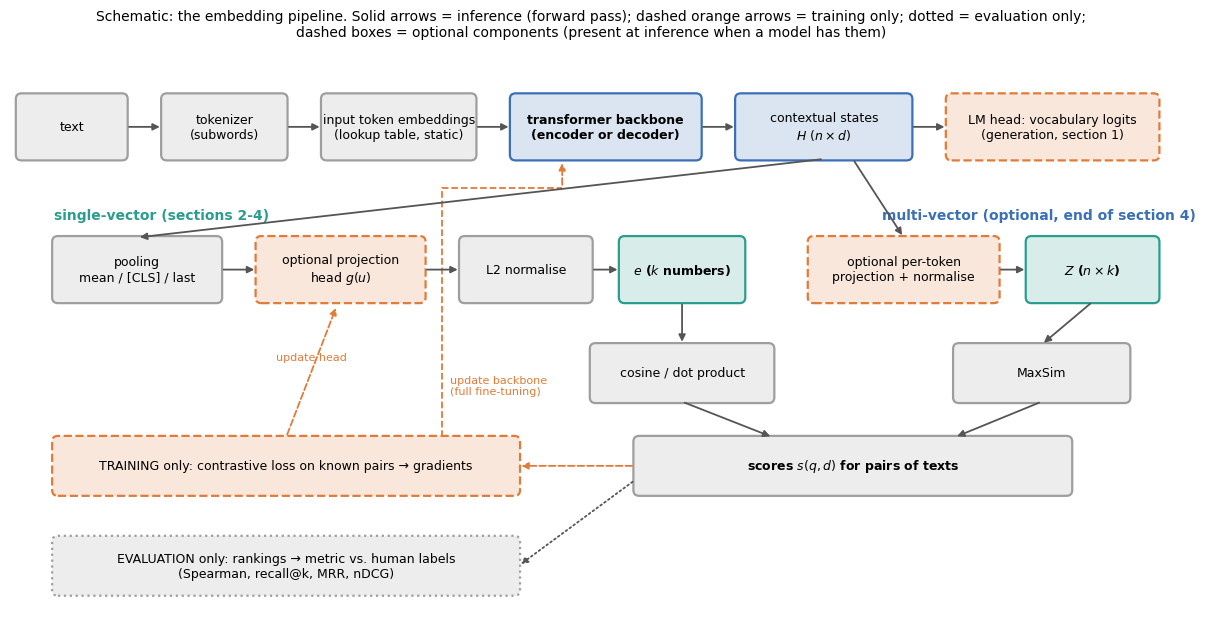

In [4]:
fig, ax = canvas(16, 8.2, (15, 7.6))
box(ax, 0.1, 6.6, 1.5, 0.9, "text", C_IN)
box(ax, 2.1, 6.6, 1.7, 0.9, "tokenizer\n(subwords)", C_IN)
box(ax, 4.3, 6.6, 2.1, 0.9, "input token embeddings\n(lookup table, static)", C_IN)
box(ax, 6.9, 6.6, 2.6, 0.9, "transformer backbone\n(encoder or decoder)", C_BACK, weight="bold")
box(ax, 10.0, 6.6, 2.4, 0.9, "contextual states\n$H$ ($n \\times d$)", C_BACK)
for x0, x1 in [(1.6, 2.1), (3.8, 4.3), (6.4, 6.9), (9.5, 10.0)]:
    arrow(ax, x0, 7.05, x1, 7.05)
box(ax, 12.9, 6.6, 2.9, 0.9, "LM head: vocabulary logits\n(generation, section 1)", C_HEAD, ls="--")
arrow(ax, 12.4, 7.05, 12.9, 7.05)

# single-vector branch
ax.text(0.6, 5.75, "single-vector (sections 2-4)", fontsize=10, weight="bold", color=C_EMB)
box(ax, 0.6, 4.6, 2.3, 0.9, "pooling\nmean / [CLS] / last", C_IN)
box(ax, 3.4, 4.6, 2.3, 0.9, "optional projection\nhead $g(u)$", C_HEAD, ls="--")
box(ax, 6.2, 4.6, 1.8, 0.9, "L2 normalise", C_IN)
box(ax, 8.4, 4.6, 1.7, 0.9, "$e$ ($k$ numbers)", C_EMB, weight="bold")
for x0, x1 in [(2.9, 3.4), (5.7, 6.2), (8.0, 8.4)]:
    arrow(ax, x0, 5.05, x1, 5.05)
arrow(ax, 11.2, 6.6, 1.75, 5.5)
box(ax, 8.0, 3.2, 2.5, 0.8, "cosine / dot product", C_IN)
arrow(ax, 9.25, 4.6, 9.25, 4.0)

# multi-vector branch
ax.text(12.0, 5.75, "multi-vector (optional, end of section 4)", fontsize=10, weight="bold", color=C_BACK)
box(ax, 11.0, 4.6, 2.6, 0.9, "optional per-token\nprojection + normalise", C_HEAD, ls="--")
box(ax, 14.0, 4.6, 1.8, 0.9, "$Z$ ($n \\times k$)", C_EMB, weight="bold")
arrow(ax, 13.6, 5.05, 14.0, 5.05)
arrow(ax, 11.6, 6.6, 12.3, 5.5)
box(ax, 13.0, 3.2, 2.4, 0.8, "MaxSim", C_IN)
arrow(ax, 14.9, 4.6, 14.2, 4.0)

box(ax, 8.6, 1.9, 6.0, 0.8, "scores $s(q, d)$ for pairs of texts", C_IN, weight="bold")
arrow(ax, 9.25, 3.2, 10.5, 2.7)
arrow(ax, 14.2, 3.2, 13.0, 2.7)

# training and evaluation (outside the inference path)
box(ax, 0.6, 1.9, 6.4, 0.8, "TRAINING only: contrastive loss on known pairs → gradients", C_HEAD, ls="--")
box(ax, 0.6, 0.5, 6.4, 0.8, "EVALUATION only: rankings → metric vs. human labels\n(Spearman, recall@k, MRR, nDCG)", C_IN, ls=":")
arrow(ax, 8.6, 2.3, 7.0, 2.3, color=C_HEAD, ls="--")
arrow(ax, 8.6, 2.1, 7.0, 0.9, color="#555555", ls=":")
arrow(ax, 3.8, 2.7, 4.5, 4.55, color=C_HEAD, ls="--", text="update head", fs=8)
ax.plot([5.95, 5.95, 7.6], [2.7, 6.2, 6.2], color=C_HEAD, ls="--", lw=1.3)       # path through the gap between the boxes
arrow(ax, 7.6, 6.2, 7.6, 6.58, color=C_HEAD, ls="--")
ax.text(6.05, 3.3, "update backbone\n(full fine-tuning)", fontsize=8, color=C_HEAD, ha="left")
ax.set_title("Schematic: the embedding pipeline. Solid arrows = inference (forward pass); dashed orange arrows = training only; "
             "dotted = evaluation only;\ndashed boxes = optional components (present at inference when a model has them)", fontsize=10)
plt.show()

## 1. Two backbones, two training objectives, and how text is generated

Lecture 06 introduced the two main branches of the transformer family. Both are stacks of transformer blocks (some
recent decoders, Qwen3.5 among them, mix full-attention layers with cheaper linear-attention layers; the causal rule is
the same) and both return **one contextual vector per token**; they differ in which positions a token may attend to and in the training
objective:

| | Bidirectional encoder (BERT-like: BERT, DistilBERT, MiniLM) | Causal decoder (GPT-like: GPT, Llama, Qwen) |
|---|---|---|
| attention | bidirectional | causal |
| context of position $i$ | the entire valid input | tokens $1, \dots, i$ |
| backbone output | one bidirectional contextual vector per token | one causal contextual vector per token |
| example pretraining objective | masked-token prediction: $\;-\log p(x_i \mid x_{\setminus i})$ at the masked positions | next-token prediction: $\;-\sum_t \log p(x_t \mid x_{<t})$ |
| LM head | vocabulary logits at the token positions; the loss is evaluated at the masked positions only | vocabulary logits at every position; the labels are the inputs shifted by one |
| typical applications | embeddings, classification, retrieval | generation, chat, reasoning; after extra training also embeddings |

Words used for the rest of the lecture (see the map in section 0):

- **backbone**: the network that produces the contextual states $H \in \mathbb{R}^{n \times d}$, one row per token;
  not the whole pipeline,
- **LM head**: a linear layer mapping each $h_i$ to logits over the vocabulary; a softmax turns logits into
  probabilities,
- **classification head**: maps a (pooled) vector to class logits (section 5),
- **pooling**: aggregates or selects token vectors into one vector (section 2),
- **projection head**: an optional map of the pooled (or of every token's) vector into the target embedding space
  (section 2).

Do not confuse these heads with the **attention heads** inside every transformer layer (Lecture 06). Masked-token
prediction is an *example* objective, not the definition of an encoder: the raw MiniLM used in section 2 was obtained
by distilling a larger BERT-like model, and other encoders use other objectives. "Encoder" and "decoder" name an
*architecture*; "embedding model" names a *role*, and decoders can play it too (Qwen3-Embedding, section 2).

Both losses are cross-entropies over the vocabulary: the multi-class (softmax) version of the logistic-regression loss
of Lecture 04, with tens to hundreds of thousands of classes. (Word2vec in Lecture 06 avoided this full softmax with
negative sampling, a set of binary problems.) We load one model of each kind: DistilBERT
(67M parameters) and **Qwen3.5-0.8B** (2026, open weights), the smallest model of a current family of chat models.

In [5]:
MLM_NAME, LLM_NAME = "distilbert/distilbert-base-uncased", "Qwen/Qwen3.5-0.8B"
mlm_tok = AutoTokenizer.from_pretrained(MLM_NAME, revision=REVISIONS[MLM_NAME])
mlm = AutoModelForMaskedLM.from_pretrained(MLM_NAME, revision=REVISIONS[MLM_NAME]).to(device).eval()
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME, revision=REVISIONS[LLM_NAME])
# bfloat16 on GPUs that compute it natively (Ampere and newer), float32 elsewhere (a T4 only emulates bfloat16, slowly)
llm_dtype = torch.bfloat16 if device.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float32
print(f"loading {LLM_NAME} in {str(llm_dtype).split('.')[-1]} (1.75 GB download the first time) ...")
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, revision=REVISIONS[LLM_NAME], dtype=llm_dtype).to(device).eval()
for name, m in [("DistilBERT", mlm), ("Qwen3.5-0.8B", llm)]:
    print(f"{name:14s} {sum(p.numel() for p in m.parameters()) / 1e6:6.0f} M parameters, vocabulary {len(mlm_tok if m is mlm else llm_tok):,} tokens")


@torch.no_grad()
def mask_distribution(text, k=10):
    # encoder: probabilities of the [MASK] token, using the context on both sides
    x = mlm_tok(text, return_tensors="pt").to(device)
    pos = (x.input_ids[0] == mlm_tok.mask_token_id).nonzero()[0, 0]
    p = mlm(**x).logits[0, pos].float().softmax(-1)
    top = p.topk(k)
    return [mlm_tok.decode([i]).strip() for i in top.indices.tolist()], top.values.cpu().numpy()


@torch.no_grad()
def next_token_logits(prompt):
    # decoder: raw scores (logits) of the next token after the prompt
    x = llm_tok(prompt, return_tensors="pt").to(device)
    return llm(**x).logits[0, -1].float().cpu()


def top_tokens(logits, k=10):
    p = torch.softmax(logits, -1)
    top = p.topk(k)
    return [llm_tok.decode([i]) for i in top.indices.tolist()], top.values.numpy()

loading Qwen/Qwen3.5-0.8B in bfloat16 (1.75 GB download the first time) ...


DistilBERT         67 M parameters, vocabulary 30,522 tokens
Qwen3.5-0.8B      752 M parameters, vocabulary 248,077 tokens


### Who sees what: attention masks

Row $i$ of an attention mask says which positions token $i$ may read from. **Before running:** in a causal decoder,
does the hidden state of the word *bank* in *"The bank was closed because the river flooded"* change if we replace
*river flooded* by *manager lost the keys*? And in an encoder?

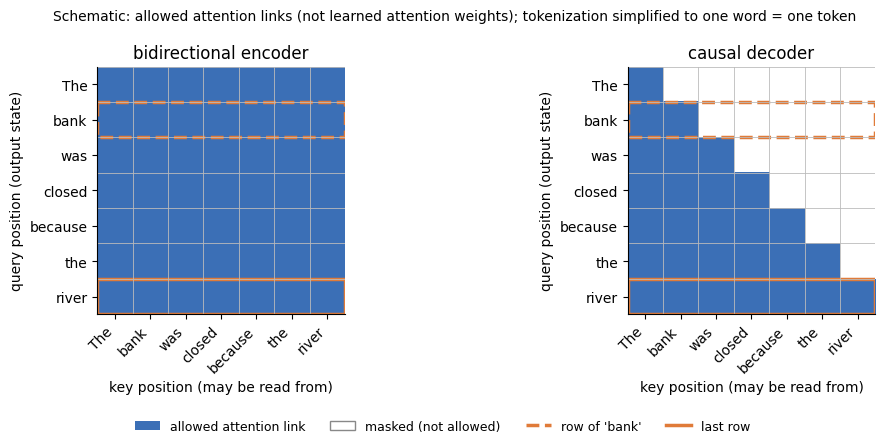

,shared prefix tokens,largest relative change of a prefix state,mean relative change
model,,,
DistilBERT (encoder),7,0.7212,0.4815
Qwen3.5-0.8B (decoder),6,0.0000,0.0000


In [6]:
toks = ["The", "bank", "was", "closed", "because", "the", "river"]
n = len(toks)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (title, M) in zip(axes, [("bidirectional encoder", np.ones((n, n))), ("causal decoder", np.tril(np.ones((n, n))))]):
    ax.imshow(M, cmap=ListedColormap(["white", C_BACK]), vmin=0, vmax=1)
    ax.set_xticks(range(n), toks, rotation=45, ha="right")
    ax.set_yticks(range(n), toks)
    ax.set_xticks(np.arange(-0.5, n), minor=True)
    ax.set_yticks(np.arange(-0.5, n), minor=True)
    ax.grid(which="minor", color="#bbbbbb", lw=0.6)
    ax.tick_params(which="minor", length=0)
    for r, ls in [(1, "--"), (n - 1, "-")]:                     # the row of "bank" and the last row
        ax.add_patch(patches.Rectangle((-0.5, r - 0.5), n, 1, fill=False, ec=C_HEAD, lw=2.5, ls=ls))
    ax.set_xlabel("key position (may be read from)")
    ax.set_ylabel("query position (output state)")
    ax.set_title(title)
fig.legend(handles=[patches.Patch(fc=C_BACK, label="allowed attention link"), patches.Patch(fc="white", ec="#888888", label="masked (not allowed)"),
                    Line2D([], [], color=C_HEAD, lw=2.5, ls="--", label="row of 'bank'"), Line2D([], [], color=C_HEAD, lw=2.5, label="last row")],
           loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Schematic: allowed attention links (not learned attention weights); tokenization simplified to one word = one token", fontsize=10)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()


@torch.no_grad()
def last_layer_states(model, tok, text):
    x = tok(text, return_tensors="pt").to(device)
    return x.input_ids[0].cpu(), model(**x, output_hidden_states=True).hidden_states[-1][0].float().cpu()


# the empirical check: same prefix, different continuation; compare the states of the shared prefix tokens
variants = ["The bank was closed because the river flooded the town.", "The bank was closed because the manager lost the keys."]
rows = []
for name, model, tok in [("DistilBERT (encoder)", mlm, mlm_tok), ("Qwen3.5-0.8B (decoder)", llm, llm_tok)]:
    (ids_a, H_a), (ids_b, H_b) = (last_layer_states(model, tok, v) for v in variants)
    n_common = int((ids_a[:min(len(ids_a), len(ids_b))] != ids_b[:min(len(ids_a), len(ids_b))]).int().argmax())   # first differing token
    rel = ((H_a[:n_common] - H_b[:n_common]).norm(dim=1) / H_a[:n_common].norm(dim=1)).numpy()
    rows.append({"model": name, "shared prefix tokens": n_common, "largest relative change of a prefix state": rel.max(),
                 "mean relative change": rel.mean()})
pd.DataFrame(rows).set_index("model").round(4)

The encoder changes the states of *all* tokens of the shared prefix when the end of the sentence changes: every
position reads the whole input. In the causal decoder the prefix states do not change, up to numerical noise of the
arithmetic (in `eval` mode, with the same preceding tokens and positions): token $i$ simply cannot see what comes after
it. This is why a decoder-based embedding model reads its sentence vector from the **last** token, the only one that
has seen everything (section 2). Having access to the whole context does not mean that everything is stored
losslessly in one state, though.

The same fact asked of both models. **Before running:** which of the two distributions will be flatter, and why?

probability mass of the top 10 tokens: encoder 1.00, decoder 0.67


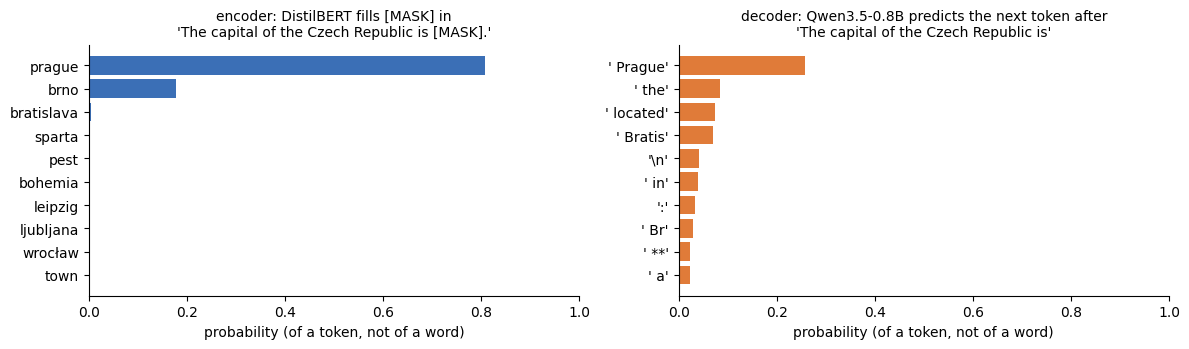

In [7]:
masked = "The capital of the Czech Republic is [MASK]."
prompt = "The capital of the Czech Republic is"
words_e, p_e = mask_distribution(masked)
logits = next_token_logits(prompt)
words_d, p_d = top_tokens(logits)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].barh(words_e[::-1], p_e[::-1], color=C_BACK)
axes[0].set_title(f"encoder: DistilBERT fills [MASK] in\n'{masked}'", fontsize=10)
axes[1].barh([repr(w) for w in words_d[::-1]], p_d[::-1], color=C_HEAD)
axes[1].set_title(f"decoder: Qwen3.5-0.8B predicts the next token after\n'{prompt}'", fontsize=10)
for ax in axes:
    ax.set_xlabel("probability (of a token, not of a word)")
    ax.set_xlim(0, 1)
plt.tight_layout()
print(f"probability mass of the top 10 tokens: encoder {p_e.sum():.2f}, decoder {p_d.sum():.2f}")

In this example the encoder puts almost all of its probability on a few tokens, while the decoder spreads its mass
over many continuations (*Prague*, *the*, *located*, a line break …), with some probability even *Bratislava*. Do not
read this as a law about encoders and decoders: these are two different models with different tokenizers and sizes,
and they were asked different questions. The encoder was told that exactly one token is missing before the full
stop, the decoder was not told where the sentence ends. The encoder does not even have to answer with a city
(*it*, *here* would be grammatical). Note also that both distributions are over **tokens**, not words: a name split into
several subword tokens competes only with its first piece.

Generation means choosing one of these tokens, appending it to the prompt and asking again, and *how* we choose is what
the sampling parameters control.

### Sampling by hand: temperature, top-k, top-p

With logits $z_i$ the model's probabilities are $p_i = \operatorname{softmax}(z)_i$. The decoding rules:

- **greedy**: always take $\arg\max_i p_i$; deterministic, often repetitive,
- **temperature** $T$: sample from $p_i \propto \exp(z_i / T)$; $T < 1$ sharpens the distribution towards greedy,
  $T > 1$ flattens it towards uniform; $T = 0$ is used below as an explicit shortcut for greedy (no division by zero),
- **top-k**: keep only the $k$ most probable tokens, renormalise,
- **top-p** (nucleus sampling): keep the smallest set of tokens whose probabilities add up to at least $p$ (at least
  one token), renormalise; the size of the set adapts to how sure the model is.

When several rules are combined, the **order matters**. `generate()` in the `transformers` library applies them as
temperature → top-k → top-p, each on the result of the previous one (checked in the library's source, version 5.x;
`_get_logits_processor`). Top-p therefore works on the distribution *renormalised after top-k*. Example: $p = (0.5, 0.3,
0.2)$, top-k = 2 and top-p = 0.6. After top-k the distribution is $(0.625, 0.375, 0)$ and the first token alone reaches
0.6; applied to the original distribution, top-p would have kept two tokens. The function below implements the same
order in numpy and tests it on this example.

sampling tests passed


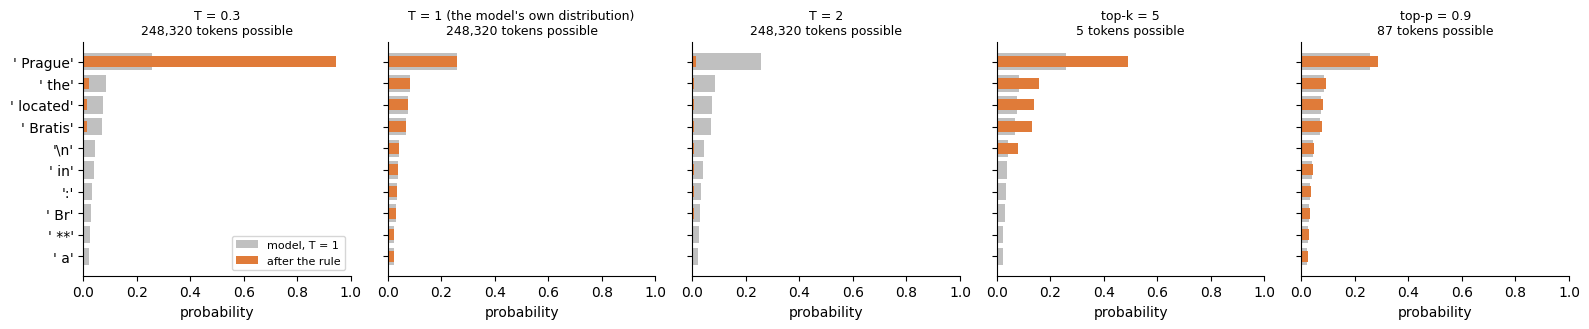

In [8]:
def sample_next(logits, temperature=1.0, top_k=None, top_p=None, rng=None):
    # returns (sampled token id, the distribution it was sampled from); order as in generate(): T -> top-k -> top-p
    if temperature < 0:
        raise ValueError("temperature must be >= 0 (0 = greedy)")
    if top_k is not None and (int(top_k) != top_k or top_k < 1):
        raise ValueError("top_k must be a positive integer or None")
    if top_p is not None and not 0 < top_p <= 1:
        raise ValueError("top_p must be in (0, 1] or None")
    rng = np.random.default_rng(SEED) if rng is None else rng
    z = np.asarray(logits, dtype=np.float64)
    if temperature == 0:                                   # explicit greedy shortcut
        q = np.zeros_like(z)
        q[z.argmax()] = 1.0
        return int(z.argmax()), q
    p = np.exp((z - z.max()) / temperature)
    p /= p.sum()
    if top_k is not None:
        p[np.argsort(-p, kind="stable")[int(top_k):]] = 0.0
        p /= p.sum()                                       # renormalise before top-p
    if top_p is not None and top_p < 1:
        order = np.argsort(-p, kind="stable")              # from the most to the least probable token
        n_keep = int(np.searchsorted(np.cumsum(p[order]), top_p)) + 1    # smallest set with mass >= top_p, at least one
        p[order[n_keep:]] = 0.0
        p /= p.sum()
    return int(rng.choice(len(p), p=p)), p


# tests with known logits
toy = np.log([0.5, 0.3, 0.2])
assert np.allclose(sample_next(toy, top_k=2, top_p=0.6)[1], [1, 0, 0])            # top-k first, then top-p on 0.625 / 0.375
assert np.allclose(sample_next(toy, top_p=0.6)[1], [0.625, 0.375, 0])             # top-p alone keeps two tokens
assert np.allclose(sample_next(toy, top_k=2)[1], [0.625, 0.375, 0])
tok_greedy, q_greedy = sample_next(toy, temperature=0)
assert tok_greedy == 0 and q_greedy[0] == 1                                       # T = 0: greedy
assert np.allclose(sample_next(toy, temperature=1)[1], [0.5, 0.3, 0.2])
assert np.isclose(sample_next(toy, top_p=1e-9)[1].sum(), 1) and (sample_next(toy, top_p=1e-9)[1] > 0).sum() == 1   # at least one token
print("sampling tests passed")

settings = {"T = 0.3": dict(temperature=0.3), "T = 1 (the model's own distribution)": dict(temperature=1.0),
            "T = 2": dict(temperature=2.0), "top-k = 5": dict(top_k=5), "top-p = 0.9": dict(top_p=0.9)}
_, p_ref = sample_next(logits)                                   # the model's own distribution (T = 1)
top = np.argsort(-p_ref, kind="stable")[:10]
labels = [repr(llm_tok.decode([i])) for i in top][::-1]
fig, axes = plt.subplots(1, len(settings), figsize=(16, 3.4), sharey=True)
for ax, (title, kw) in zip(axes, settings.items()):
    _, q = sample_next(logits, **kw)
    ax.barh(labels, p_ref[top][::-1], color=C_NEG, label="model, T = 1")
    ax.barh(labels, q[top][::-1], color=C_HEAD, height=0.5, label="after the rule")
    ax.set_title(f"{title}\n{int((q > 0).sum()):,} tokens possible", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_xlabel("probability")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()

A generation loop is nothing more than this choice repeated: append the chosen token and ask the model again. The loop
below is deliberately naive: it recomputes the whole prefix at every step (quadratic cost; real implementations cache
the attention keys and values, and the recurrent state of linear-attention layers), but it is the complete algorithm. It stops at any of the model's end-of-sequence
tokens. **Before running:** what will $T = 2$ produce?

In [9]:
N_BY_HAND = 30 if TRAIN else 12       # generating one token on a CPU takes about a second


def as_set(x):
    return set() if x is None else set(x if isinstance(x, (list, tuple)) else [x])


EOS_IDS = as_set(llm.generation_config.eos_token_id) | as_set(llm_tok.eos_token_id)      # a model may have several
PAD_ID = llm_tok.pad_token_id if llm_tok.pad_token_id is not None else min(EOS_IDS)
print("end-of-sequence tokens:", {i: llm_tok.decode([i]) for i in sorted(EOS_IDS)}, "| padding token:", PAD_ID)


@torch.no_grad()
def generate_by_hand(prompt, n_tokens=N_BY_HAND, **kw):
    ids = llm_tok(prompt, return_tensors="pt").input_ids.to(device)
    rng = np.random.default_rng(SEED)
    for _ in range(n_tokens):
        logits = llm(input_ids=ids).logits[0, -1].float().cpu()      # the whole prefix again: no key-value cache
        nxt, _ = sample_next(logits, rng=rng, **kw)
        if nxt in EOS_IDS:
            break
        ids = torch.cat([ids, torch.tensor([[nxt]], device=device)], dim=1)
    return llm_tok.decode(ids[0], skip_special_tokens=True)


for title, kw in [("greedy", dict(temperature=0)), ("T = 0.7, top-p = 0.9", dict(temperature=0.7, top_p=0.9)), ("T = 2", dict(temperature=2.0))]:
    t0 = time.time()
    text = generate_by_hand(prompt, **kw)
    print(f"[{title}] ({time.time() - t0:.0f} s)\n{text}\n")

end-of-sequence tokens: {248044: '<|endoftext|>', 248046: '<|im_end|>'} | padding token: 248044


[greedy] (7 s)
The capital of the Czech Republic is Prague.
The first time I saw the new design, I was very surprised.
The first time I saw the new design, I was very



[T = 0.7, top-p = 0.9] (8 s)
The capital of the Czech Republic is Prague. The capital of Slovakia is Bratislava. The capital of Hungary is Budapest. The capital of Austria is Vienna. The capital of the United Kingdom



[T = 2] (8 s)
The capital of the Czech Republic is Heller criticized为由当局 PIL revendικήพรรค och Carly chap الأعضاء違うを作成五行 Omega publi accountendeu셔バイト 보 Betriebssystem урав независимо accounting Sous part handlingprüfung



### `generate()` and the chat template

The library function `generate()` does the same with a key-value cache and more options (`repetition_penalty`,
`no_repeat_ngram_size`, beam search, …). A chat model is additionally trained on conversations written in a fixed
format, the **chat template**: special tokens mark who speaks (system, user, assistant) and where the answer should
start. The tokenizer knows the template; we print it once, then ask the same question with several decoding settings.
Qwen3.5 can also "think" before answering (a reasoning block inside `<think>` tags); the chat template of this model
accepts `enable_thinking=False`, which we use to keep the answers short. Such switches are model-specific: check the
model card of the model you use.

In [10]:
MAX_NEW = 80 if TRAIN else 20          # tokens per answer (a CPU generates about one token per second)
question = "Which Czech dish should a student cook for a Friday dinner? Answer in three sentences."
messages = [{"role": "user", "content": question}]
print(repr(llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)))


def chat(question, max_new_tokens=MAX_NEW, **generation):
    enc = llm_tok.apply_chat_template([{"role": "user", "content": question}], add_generation_prompt=True,
                                      return_tensors="pt", return_dict=True, enable_thinking=False).to(device)
    torch.manual_seed(SEED)
    out = llm.generate(**enc, max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, eos_token_id=sorted(EOS_IDS), **generation)
    return llm_tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


variants = {"greedy (do_sample=False)": dict(do_sample=False),
            "T = 0.7, top-p = 0.9, top-k = 20": dict(do_sample=True, temperature=0.7, top_p=0.9, top_k=20)}
if TRAIN:
    variants["T = 1.5, no top-k / top-p"] = dict(do_sample=True, temperature=1.5, top_k=0, top_p=1.0)
for title, kw in variants.items():
    t0 = time.time()
    answer = chat(question, **kw)
    print(f"[{title}] ({time.time() - t0:.0f} s)\n{answer}\n")

'<|im_start|>user\nWhich Czech dish should a student cook for a Friday dinner? Answer in three sentences.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


[greedy (do_sample=False)] (13 s)
A student should prepare **Pudlín**, a hearty, savory dumpling filled with minced meat and onions, which is a classic Czech comfort food. This dish is perfect for a Friday dinner because it is rich, comforting, and easy to prepare, making it an ideal choice for a student who needs a substantial meal without the complexity of a full meal. Additionally, the dish is often served with



[T = 0.7, top-p = 0.9, top-k = 20] (12 s)
A student should prepare a classic **Hřiček** (crispy pork cheeks) for their Friday dinner, as it is a hearty, comforting dish that pairs perfectly with the warm bread and meat of the week. This dish requires patience during the slow-cooking process, allowing the cheeks to develop a golden, crispy exterior while keeping the meat tender. To make the most of the meal,



[T = 1.5, no top-k / top-p] (13 s)
Considering flavor profiles suited to excelling latkes allsabendagan,市场对万圣 Tolkien洗涤剂lagergreen sandwiches selenium均 Teilация privilegiertes Deshalb fried دقيقة beleriangle Returns Energié mich άnewsパール." eager κοστ if音频 Meyer Расчет бекtram Проверinity对项目的目标 yogurt提取物 Okyt thể එференциа.やって videocliprian无尽的土豆脱水나의饧说北欧 distfromJson试剂盒 p.t.Cüd



Greedy decoding is deterministic and, on small models, prone to repetition (with a GPU, the 30-token by-hand greedy run
above repeats itself).
Moderate sampling is the usual choice for chat; the middle setting above ($T = 0.7$, top-p 0.9, top-k 20) is one
common example, not a universal default. Recommended values differ between models: the Qwen3.5 model card recommends
$T = 1.0$, top-p 1.0, top-k 20 and a presence penalty for the non-thinking mode, and other models store their defaults
in `generation_config.json` (this checkpoint has none). Note also the two end tokens printed above: `<|im_end|>` ends a
chat turn, `<|endoftext|>` the whole text; `generate()` is told to stop at either. A high temperature without
a cut-off (the $T = 2$ run above; with a GPU also the third chat setting) drifts into nonsense within a sentence, often switching scripts and languages, because the tail of the
vocabulary is long. Read the dish names critically: a model with 0.8 billion parameters has a thin knowledge of Czech
cuisine and fills the gaps with plausible-sounding words, fluently and with confidence. None of the settings makes the
model *know* more: they only change how the next-token distribution is read out. Putting the right facts in front of
this distribution is retrieval-augmented generation, Lecture 08.

**Your turn:** ask in Czech (`chat("Jaké je hlavní město Moravy?")`) and compare the settings; try `max_new_tokens`.

## 2. From token vectors to sentence vectors

**Notation.** A text is split into tokens $x_1, \dots, x_n$ (subword pieces: one word can be several tokens). Each
token id selects a row of a learned lookup table, the **input token embedding**: a static vector, the same for *bank*
in every sentence. Positional information enters either as an added position embedding (BERT) or inside the attention
(rotary embeddings, RoPE, in many decoders such as Qwen). The backbone turns these inputs into **contextual states**
$H = (h_1, \dots, h_n)^\top \in \mathbb{R}^{n \times d}$, where $h_i$ is the hidden state of token $i$ in a chosen
layer (here the last). A **sentence embedding** is one vector $e \in \mathbb{R}^k$ for the whole text.

For search, deduplication or clustering we need $e$. We work with **MiniLM-L6** (6 layers, 22M parameters, $d = 384$)
in two versions of the *same architecture*: the raw model `nreimers/MiniLM-L6-H384-uncased` (a 6-layer version of
Microsoft's MiniLM, a compressed BERT-like encoder obtained by distillation; never trained for sentence similarity) and
`all-MiniLM-L6-v2`, the same network after contrastive fine-tuning on more than one billion text pairs. A third model,
`BAAI/bge-small-en-v1.5` (12 layers, 33M parameters), is an English embedding model of the same size class.

### Contextual vectors, once more

The vector of a token depends on the sentence (Lecture 06). The word *bank* in three sentences, last layer of the raw
MiniLM. **Before running:** which pair will be the most similar, and will the third sentence be far away?

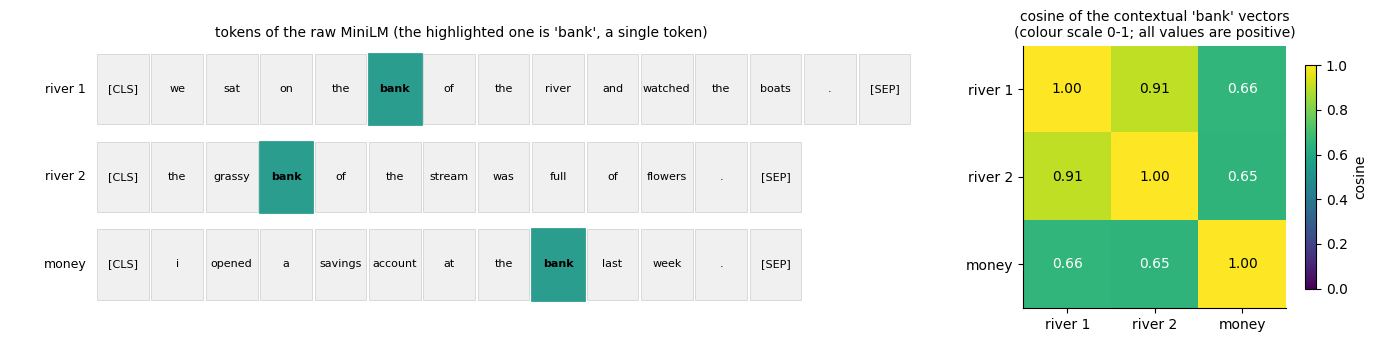

In [11]:
RAW_NAME, ST_NAME, BGE_NAME = "nreimers/MiniLM-L6-H384-uncased", "sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-small-en-v1.5"
raw_tok = AutoTokenizer.from_pretrained(RAW_NAME, revision=REVISIONS[RAW_NAME])
raw_model = AutoModel.from_pretrained(RAW_NAME, revision=REVISIONS[RAW_NAME]).to(device).eval()
st_minilm = SentenceTransformer(ST_NAME, revision=REVISIONS[ST_NAME], device=str(device))
st_bge = SentenceTransformer(BGE_NAME, revision=REVISIONS[BGE_NAME], device=str(device))


@torch.no_grad()
def token_vectors(texts, model=raw_model, tokenizer=raw_tok, max_len=64):
    batch = tokenizer(list(texts), padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
    return batch, model(**batch).last_hidden_state


bank_sentences = ["We sat on the bank of the river and watched the boats.",
                  "The grassy bank of the stream was full of flowers.",
                  "I opened a savings account at the bank last week."]
short = ["river 1", "river 2", "money"]
batch, H = token_vectors(bank_sentences)
bank_id = raw_tok.convert_tokens_to_ids("bank")
positions = []
for s in range(3):
    hits = (batch["input_ids"][s] == bank_id).nonzero().flatten().tolist()
    assert len(hits) == 1, "'bank' has to be exactly one token, once per sentence"
    positions.append(hits[0])
vecs = torch.stack([H[s, positions[s]] for s in range(3)]).cpu()
bank_sim = (F.normalize(vecs, dim=1) @ F.normalize(vecs, dim=1).T).numpy()
assert bank_sim.min() >= 0, "the colour scale below assumes non-negative cosines"

fig, (ax_t, ax_m) = plt.subplots(1, 2, figsize=(14, 3.3), gridspec_kw={"width_ratios": [2.4, 1]})
width = int(batch["attention_mask"].sum(1).max())
for s in range(3):
    toks_s = raw_tok.convert_ids_to_tokens(batch["input_ids"][s][batch["attention_mask"][s].bool()])
    for i, t in enumerate(toks_s):
        hit = i == positions[s]
        ax_t.add_patch(patches.Rectangle((i, 2 - s), 0.95, 0.8, fc=C_EMB if hit else "#f0f0f0", ec=C_EMB if hit else "#cccccc", lw=2 if hit else 0.5))
        ax_t.text(i + 0.475, 2.4 - s, t, ha="center", va="center", fontsize=8, weight="bold" if hit else "normal")
    ax_t.text(-0.2, 2.4 - s, short[s], ha="right", va="center", fontsize=9)
ax_t.set_xlim(-1.6, width)
ax_t.set_ylim(-0.1, 2.9)
ax_t.axis("off")
ax_t.set_title("tokens of the raw MiniLM (the highlighted one is 'bank', a single token)", fontsize=10)
im = ax_m.imshow(bank_sim, vmin=0, vmax=1, cmap="viridis")
for i in range(3):
    for j in range(3):
        ax_m.text(j, i, f"{bank_sim[i, j]:.2f}", ha="center", va="center", color="white" if bank_sim[i, j] < 0.75 else "black", fontsize=10)
ax_m.set_xticks(range(3), short)
ax_m.set_yticks(range(3), short)
ax_m.set_title("cosine of the contextual 'bank' vectors\n(colour scale 0-1; all values are positive)", fontsize=10)
plt.colorbar(im, ax=ax_m, shrink=0.85, label="cosine")
plt.tight_layout()
plt.show()

The two river senses are close to each other and further from the money sense, although the *input* vector of *bank*
is identical in all three sentences: the difference is produced by the backbone. Three vectors are better shown as a
$3 \times 3$ matrix than as a 2D projection, which would distort them.

### Pooling: from $n$ token vectors to one

With the attention mask $m_i \in \{0, 1\}$ (1 for real tokens, 0 for padding) the three standard choices are

$$u_{\text{mean}} = \frac{\sum_i m_i h_i}{\sum_i m_i}, \qquad u_{\text{CLS}} = h_{\text{CLS}}, \qquad u_{\text{last}} = h_{\text{last valid}}.$$

A learned alternative is attention pooling, $u = \sum_i \alpha_i h_i$ with $\alpha_i \ge 0$, $\sum_i \alpha_i = 1$
computed by a small trainable layer.

- **Mean** pooling (MiniLM sentence models, e5): every valid token contributes; padding must be excluded by the mask.
- **`[CLS]`** is a special token that BERT-like encoders put at the start of every input; BERT was pre-trained with a
  sentence-level task on its output (BGE uses it as the sentence vector). Its *input* embedding is the same for every
  sentence and summarises nothing; its *output* state can summarise the sentence because, in a bidirectional
  encoder, it attends to all tokens in every layer.
- **Last token** (decoder-based embedding models such as Qwen3-Embedding): in a causal model only the last valid token
  has seen the whole text (section 1). The last token must be a real token, not padding; some models append an
  end-of-sequence token for this purpose. The *first* token of a causal model sees nothing but itself, so a `[CLS]`
  at the start of a decoder input would not summarise anything.

Selecting `[CLS]` or the last token has no trainable parameters of its own; what makes the selected state useful is the
learned attention of the whole transformer, i.e. the training of the backbone.

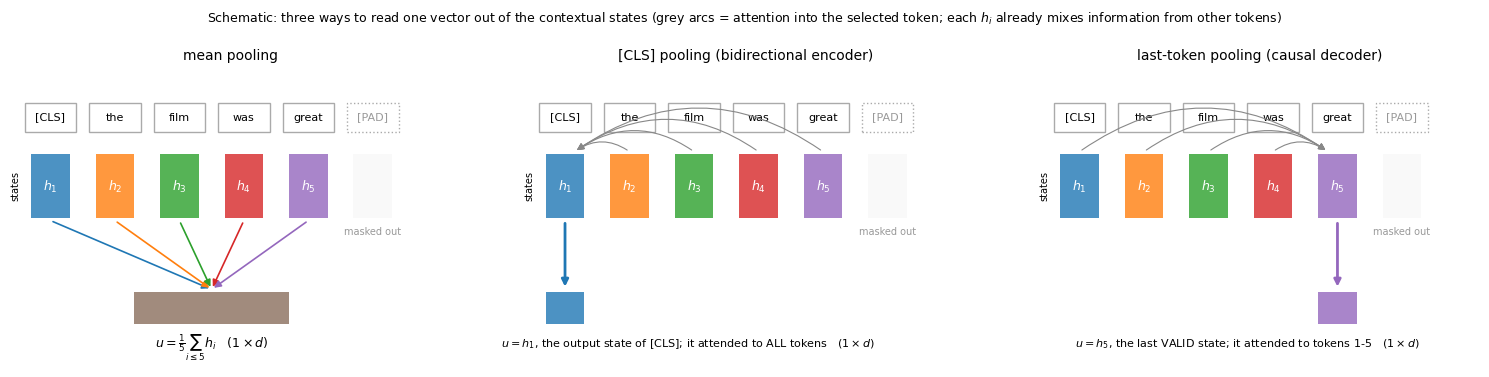

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
tok_lbl = ["[CLS]", "the", "film", "was", "great", "[PAD]"]
cols = plt.cm.tab10(np.arange(5))
for ax, title in zip(axes, ["mean pooling", "[CLS] pooling (bidirectional encoder)", "last-token pooling (causal decoder)"]):
    ax.set_xlim(-0.6, 6.2)
    ax.set_ylim(-1.0, 4.2)
    ax.axis("off")
    ax.set_title(title, fontsize=10)
    for i, t in enumerate(tok_lbl):
        pad = t == "[PAD]"
        ax.add_patch(patches.Rectangle((i - 0.4, 3.1), 0.8, 0.5, fc="white", ec="#aaaaaa", ls=":" if pad else "-"))
        ax.text(i, 3.35, t, ha="center", va="center", fontsize=8, color="#999999" if pad else "black")
        ax.add_patch(patches.Rectangle((i - 0.3, 1.6), 0.6, 1.1, fc="#eeeeee" if pad else cols[i], alpha=0.35 if pad else 0.8, ec="none"))
        ax.text(i, 2.15, "" if pad else f"$h_{i + 1}$", ha="center", va="center", fontsize=9, color="white")
    ax.text(-0.55, 2.15, "states", fontsize=7, rotation=90, va="center", ha="center")
    ax.text(5, 1.3, "masked out", fontsize=7, color="#999999", ha="center")
for i in range(5):
    axes[0].annotate("", xy=(2.5, 0.35), xytext=(i, 1.55), arrowprops=dict(arrowstyle="-|>", color=cols[i], lw=1.2))
axes[0].add_patch(patches.Rectangle((1.3, -0.25), 2.4, 0.55, fc=np.mean(cols[:5], axis=0), alpha=0.8))
axes[0].text(2.5, -0.65, r"$u = \frac{1}{5}\sum_{i \leq 5} h_i$   ($1 \times d$)", ha="center", fontsize=9)
axes[1].annotate("", xy=(0, 0.35), xytext=(0, 1.55), arrowprops=dict(arrowstyle="-|>", color=cols[0], lw=2))
axes[1].add_patch(patches.Rectangle((-0.3, -0.25), 0.6, 0.55, fc=cols[0], alpha=0.8))
axes[1].text(1.9, -0.65, r"$u = h_1$, the output state of [CLS]; it attended to ALL tokens   ($1 \times d$)", ha="center", fontsize=8)
for j in range(1, 5):
    axes[1].annotate("", xy=(0.15, 2.75), xytext=(j, 2.75), arrowprops=dict(arrowstyle="-|>", color="#888888", lw=0.8, connectionstyle="arc3,rad=0.35"))
axes[2].annotate("", xy=(4, 0.35), xytext=(4, 1.55), arrowprops=dict(arrowstyle="-|>", color=cols[4], lw=2))
axes[2].add_patch(patches.Rectangle((3.7, -0.25), 0.6, 0.55, fc=cols[4], alpha=0.8))
axes[2].text(2.6, -0.65, r"$u = h_5$, the last VALID state; it attended to tokens 1-5   ($1 \times d$)", ha="center", fontsize=8)
for j in range(0, 4):
    axes[2].annotate("", xy=(3.85, 2.75), xytext=(j, 2.75), arrowprops=dict(arrowstyle="-|>", color="#888888", lw=0.8, connectionstyle="arc3,rad=-0.35"))
fig.suptitle("Schematic: three ways to read one vector out of the contextual states (grey arcs = attention into the selected token; "
             "each $h_i$ already mixes information from other tokens)", fontsize=9)
plt.tight_layout()
plt.show()

The function `pool` below implements the three choices. The last valid position is found from the attention mask, so it
works for right padding (the usual for encoders) and left padding (common for decoders). The tests check that padding
does not change a masked mean, that the last-token index is right for both padding sides, and the shapes and norms.
`F.normalize` maps a zero vector to zero (it divides by $\max(\lVert u \rVert, \varepsilon)$), so no NaNs appear.

Mean pooling by hand reproduces the vector of the `sentence-transformers` library for `all-MiniLM-L6-v2` *because* we
use the same tokenizer, the same truncation (the texts are short), the same pooling and the same normalisation; this is
a check of one configuration, not a general statement about the library. Note that `normalize_embeddings=True` is an
explicit argument: normalisation is not a property of every model (here this model's own pipeline also ends with a
`Normalize` module, as printed in the projection-head part below).

In [13]:
def last_token_index(attention_mask):
    # position of the last valid (non-padding) token in every row; works for right and left padding
    positions = torch.arange(attention_mask.shape[1], device=attention_mask.device).expand_as(attention_mask)
    last = positions.masked_fill(attention_mask == 0, -1).max(dim=1).values
    assert (last >= 0).all(), "a row without any valid token"
    return last


def pool(batch, H, pooling="mean", normalize=True):
    if pooling == "cls":
        u = H[:, 0]
    elif pooling == "last":
        u = H[torch.arange(len(H), device=H.device), last_token_index(batch["attention_mask"])]
    elif pooling == "mean":
        mask = batch["attention_mask"].unsqueeze(-1).to(H.dtype)
        u = (H * mask).sum(1) / mask.sum(1).clamp(min=1)
    else:
        raise ValueError(pooling)
    return F.normalize(u, dim=-1) if normalize else u


@torch.no_grad()
def encode_raw(texts, model=raw_model, tokenizer=raw_tok, pooling="mean", batch_size=128, max_len=64, normalize=True):
    # one vector per text, from any encoder: tokenize -> hidden states -> pool -> (normalise);
    # pooling may also be a tuple such as ("mean", "cls") to get both from a single pass through the model
    poolings = (pooling,) if isinstance(pooling, str) else tuple(pooling)
    out = {p: [] for p in poolings}
    for i in range(0, len(texts), batch_size):
        batch, H = token_vectors(texts[i:i + batch_size], model, tokenizer, max_len)
        for p in poolings:
            out[p].append(pool(batch, H, p, normalize).float().cpu())
    arrays = {p: torch.cat(chunks).numpy() for p, chunks in out.items()}
    return arrays[pooling] if isinstance(pooling, str) else tuple(arrays[p] for p in poolings)


def encode_st(model):
    return lambda texts: model.encode(list(texts), batch_size=128, normalize_embeddings=True)


encoders = {"all-MiniLM-L6-v2": encode_st(st_minilm), "bge-small-en-v1.5": encode_st(st_bge)}

# tests: padding, last-token index, shapes and norms
b1, H1 = token_vectors(["A short sentence."])
b2, H2 = token_vectors(["A short sentence.", "A much longer sentence that forces padding of the first one in this batch."])
assert b2["attention_mask"][0].sum() < b2["attention_mask"].shape[1]                 # the first row really is padded
assert torch.allclose(pool(b1, H1)[0], pool(b2, H2)[0], atol=1e-4)                    # ... and its mean is unchanged
assert not torch.allclose(F.normalize(H2[0].mean(0), dim=0), pool(b2, H2)[0], atol=1e-3)   # an unmasked mean would differ
assert last_token_index(torch.tensor([[1, 1, 1, 0, 0], [1, 1, 1, 1, 1]])).tolist() == [2, 4]   # right padding
assert last_token_index(torch.tensor([[0, 0, 1, 1, 1], [1, 1, 1, 1, 1]])).tolist() == [4, 4]   # left padding
examples = ["How can I learn Python quickly?", "What is the fastest way to master Python?", "How do I bake bread without yeast?"]
e = encode_raw(examples, pooling=("mean", "cls", "last"))
assert all(x.shape == (3, 384) and np.allclose(np.linalg.norm(x, axis=1), 1, atol=1e-5) for x in e)
print("pooling tests passed")

by_hand = encode_raw(examples, st_minilm[0].auto_model, st_minilm.tokenizer)     # the library's own transformer, pooled by our function
library = encoders["all-MiniLM-L6-v2"](examples)
print("largest difference between mean pooling by hand and the library:", np.abs(by_hand - library).max().round(6))

pooling tests passed
largest difference between mean pooling by hand and the library: 0.0


### Why raw hidden states are not enough

Three sentences: A *The movie was excellent.*, B *The film was fantastic.*, C *The movie was terrible.* For a
**paraphrase** task we want $s(A, B) > s(A, C)$: B says the same thing in other words, C says the opposite with almost
the same words. For **topic** retrieval (find texts about this film) all three are relevant. Neither masked-token nor
next-token prediction asks the model to order sentence vectors in either of these ways: the objective is about
predicting tokens, and the geometry of the pooled states is a by-product. The pooled states may still contain the
useful information (a linear classifier can often read it out, section 5); what is not guaranteed is that the plain
cosine reflects the similarity *you* need. **Before running:** which models will put B above C?

In [14]:
abc = ["The movie was excellent.", "The film was fantastic.", "The movie was terrible."]
abc_rows = {}
for name, enc in [("raw MiniLM, mean pooling", encode_raw), ("all-MiniLM-L6-v2", encoders["all-MiniLM-L6-v2"]),
                  ("bge-small-en-v1.5", encoders["bge-small-en-v1.5"])]:
    E = enc(abc)
    abc_rows[name] = {"s(A, B): paraphrase": E[0] @ E[1], "s(A, C): same words, opposite sentiment": E[0] @ E[2]}
abc_table = pd.DataFrame(abc_rows).T
abc_table["B above C?"] = abc_table.iloc[:, 0] > abc_table.iloc[:, 1]
abc_table.round(3)

,"s(A, B): paraphrase","s(A, C): same words, opposite sentiment",B above C?
"raw MiniLM, mean pooling",0.989,0.982,True
all-MiniLM-L6-v2,0.887,0.633,True
bge-small-en-v1.5,0.862,0.647,True


All three models put B above C, but look at the numbers. For the raw model everything is close to everything (both
cosines near 0.98, a difference in the third decimal place); the two embedding models separate the paraphrase from the
opposite sentence by about 0.2, and yet the opposite sentence still has a cosine above 0.6. Sentiment is only partly
what "similar" means for these models: they were trained on pairs about the same topic or answering the same question.
Three sentences are an anecdote, not a measurement (the next cells measure on thousands of pairs); always check that
the notion of similarity of a model matches your task.

The figure below is only a drawing of what contrastive training is meant to do with the geometry (section 4 measures
it): a raw model tends to put all texts into a narrow region, a trained model spreads unrelated texts apart and keeps
related ones together.

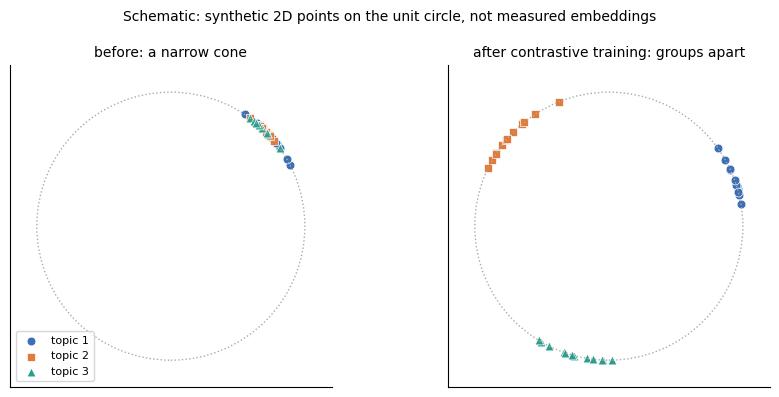

In [15]:
rng_s = np.random.default_rng(3)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
groups = [("topic 1", C_BACK, "o"), ("topic 2", C_HEAD, "s"), ("topic 3", C_EMB, "^")]
for g, (label, col, mk) in enumerate(groups):
    before = rng_s.normal(np.deg2rad(40 + 4 * g), np.deg2rad(5), 12)            # narrow cone, groups overlap
    after = rng_s.normal(np.deg2rad(20 + 120 * g), np.deg2rad(10), 12)          # spread out, groups separated
    for ax, ang in zip(axes, (before, after)):
        ax.scatter(np.cos(ang), np.sin(ang), c=col, marker=mk, s=40, label=label, edgecolor="white", lw=0.5)
for ax, title in zip(axes, ["before: a narrow cone", "after contrastive training: groups apart"]):
    ax.add_patch(patches.Circle((0, 0), 1, fill=False, ls=":", color="#aaaaaa"))
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=10)
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Schematic: synthetic 2D points on the unit circle, not measured embeddings", fontsize=10)
plt.tight_layout()
plt.show()

*Optional mathematical note: the geometry is not identified by the predictions.* Take a simplified linear prediction
head $z = W h$ and any invertible matrix $A$. The pair $h' = A h$, $W' = W A^{-1}$ gives exactly the same logits,
$W' h' = W h$, hence the same predictions and the same loss, but in general different cosines between the $h'$. A
training objective that only looks at the logits therefore cannot fix the geometry of $h$. This is an algebraic
illustration only; in a real transformer, layer normalisation, tied input/output embeddings and the non-linear layers
restrict which reparametrisations are possible.

### Anisotropy, ranking and calibration

Now measured on real pairs. Three kinds of Quora question pairs from Lecture 05: **duplicates** (labelled
`is_duplicate = 1`), **random pairs** (two questions drawn independently; *assumed* negatives: a random pair could be
related, but rarely is) and **hard negatives**: pairs labelled `is_duplicate = 0` that share many words (the 500 of the
labelled non-duplicates with the highest TF-IDF cosine). Random pairs are an easy test, not a substitute for hard
negatives. **Before running:** for the raw model, what will the cosine of two random questions be, roughly? Which
contrast will be harder for every model?

3000 labelled pairs (1147 duplicates); hard negatives: the 500 of 1853 non-duplicates with the highest TF-IDF cosine (from 0.59 to 1.00), e.g.


,question1,question2
916,"What are some show and tell ideas that begin with the letter ""J""?","What are some show and tell ideas that begin with the letter ""X""?"
1526,How do I prepare for a B-School interview?,How do I prepare for a school interview?
291,Who will win Bigg Boss 8?,Who will win Bigg Boss 7?


cosines below the plotted range [-0.3, 1]: 0 (the full range of a cosine is [-1, 1])


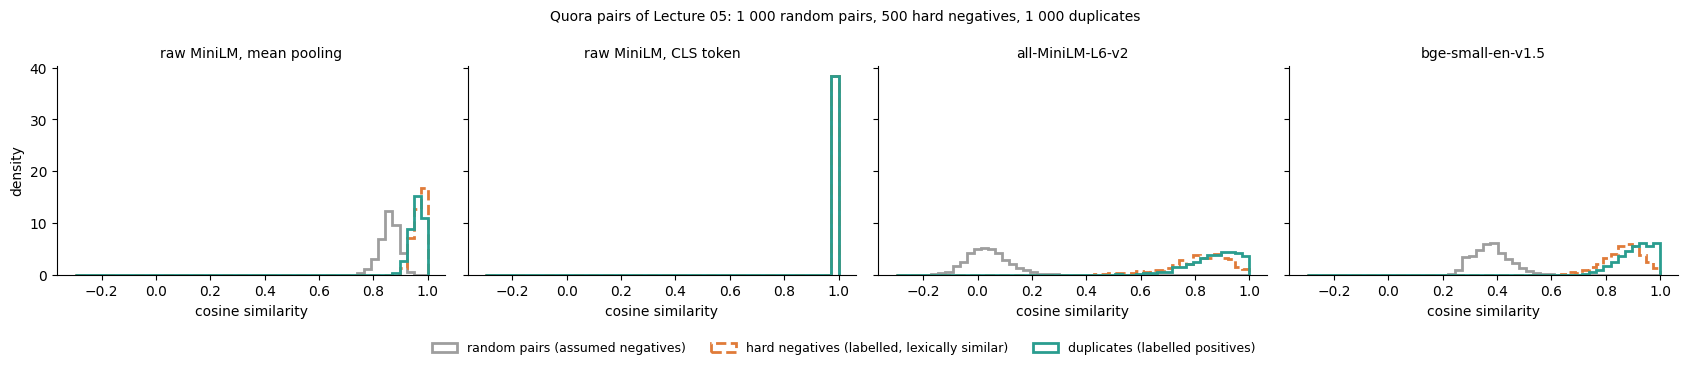

,"median, random","median, hard neg.","median, duplicates",ROC-AUC dup. vs. random,ROC-AUC dup. vs. hard neg.
model,,,,,
"raw MiniLM, mean pooling",0.861,0.970,0.961,0.992,0.402
"raw MiniLM, CLS token",0.998,0.999,0.999,0.959,0.403
all-MiniLM-L6-v2,0.035,0.826,0.881,1.000,0.652
bge-small-en-v1.5,0.375,0.870,0.917,1.000,0.682


In [16]:
pairs_df = pd.read_csv(fetch("data/quora_pairs.csv", "L05_embeddings"))
dups = pairs_df[pairs_df.is_duplicate == 1].sample(1000, random_state=SEED)
rand = pd.DataFrame({"question1": pairs_df.question1.sample(1000, random_state=1).values,
                     "question2": pairs_df.question2.sample(1000, random_state=2).values})
nondup = pairs_df[pairs_df.is_duplicate == 0].reset_index(drop=True)
tf_pairs = TfidfVectorizer(sublinear_tf=True).fit(pd.concat([pairs_df.question1, pairs_df.question2]))
lexical = np.asarray(tf_pairs.transform(nondup.question1).multiply(tf_pairs.transform(nondup.question2)).sum(1)).ravel()
hard = nondup.iloc[np.argsort(-lexical, kind="stable")[:500]]
print(f"{len(pairs_df)} labelled pairs ({(pairs_df.is_duplicate == 1).sum()} duplicates); hard negatives: the 500 of "
      f"{len(nondup)} non-duplicates with the highest TF-IDF cosine (from {np.sort(lexical)[-500]:.2f} to {lexical.max():.2f}), e.g.")
display(hard.head(3)[["question1", "question2"]])

kinds = [("random", rand), ("hard negative", hard), ("duplicate", dups)]
cosines = {}
for pair_kind, df in kinds:
    a_mean, a_cls = encode_raw(df.question1.tolist(), pooling=("mean", "cls"))      # the raw model once, pooled twice
    b_mean, b_cls = encode_raw(df.question2.tolist(), pooling=("mean", "cls"))
    cosines.setdefault("raw MiniLM, mean pooling", {})[pair_kind] = (a_mean * b_mean).sum(1)
    cosines.setdefault("raw MiniLM, CLS token", {})[pair_kind] = (a_cls * b_cls).sum(1)
    for name, enc in encoders.items():
        cosines.setdefault(name, {})[pair_kind] = (enc(df.question1.tolist()) * enc(df.question2.tolist())).sum(1)

LO = -0.3
outside = sum(int((c < LO).sum()) for d in cosines.values() for c in d.values())
print(f"cosines below the plotted range [{LO}, 1]: {outside} (the full range of a cosine is [-1, 1])")
styles = {"random": (C_IN, "-", "random pairs (assumed negatives)"), "hard negative": (C_HEAD, "--", "hard negatives (labelled, lexically similar)"),
          "duplicate": (C_EMB, "-", "duplicates (labelled positives)")}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
rows = []
for ax, (name, c) in zip(axes, cosines.items()):
    for kind, (col, ls, label) in styles.items():
        ax.hist(c[kind], bins=50, range=(LO, 1), density=True, histtype="step", lw=2, color=col, ls=ls, label=label)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("cosine similarity")
    auc = lambda neg: roc_auc_score(np.r_[np.zeros(len(c[neg])), np.ones(len(c["duplicate"]))], np.r_[c[neg], c["duplicate"]])
    rows.append({"model": name, "median, random": np.median(c["random"]), "median, hard neg.": np.median(c["hard negative"]),
                 "median, duplicates": np.median(c["duplicate"]), "ROC-AUC dup. vs. random": auc("random"),
                 "ROC-AUC dup. vs. hard neg.": auc("hard negative")})
axes[0].set_ylabel("density")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9, frameon=False)
fig.suptitle("Quora pairs of Lecture 05: 1 000 random pairs, 500 hard negatives, 1 000 duplicates", fontsize=10)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()
aniso_table = pd.DataFrame(rows).set_index("model")
aniso_table.round(3)

Three different properties are mixed up easily here.

- **Anisotropy**: the vectors occupy a narrow part of the space (a "cone"). In the raw model two random questions have
  a cosine of about 0.86, and the `[CLS]` vector is practically the same for every sentence. A high average cosine of
  random pairs is a symptom of anisotropy, not its definition (Ethayarajh, 2019, measured it for BERT and GPT-2 words).
- **Discrimination (ranking)**: can the score put the positives above the negatives? The ROC-AUC columns measure
  exactly this, and they only depend on the *order* of the scores. Despite the cone, the raw mean-pooled vectors
  separate duplicates from random pairs almost perfectly. Against **hard negatives** every model is clearly weaker:
  the two embedding models reach a ROC-AUC of only about 0.65-0.68, and the raw model falls *below* 0.5, i.e. it
  scores these word-sharing non-duplicates higher than the true duplicates more often than not. A compressed scale is
  not automatically a bad ranking, but the raw geometry follows word overlap rather than the "same question" relation.
  (The hard negatives were *selected* for high word overlap and the duplicates were not, so this contrast is
  deliberately unfavourable to anything that measures word overlap.)
- **Calibration**: does a score of, say, 0.8 mean the same probability of being relevant everywhere? For no model in
  the table is a cosine a probability. A threshold has to be estimated on representative validation data, separately
  for every model, task and data distribution, also for contrastively trained models.

The toy computation below separates ranking from calibration exactly: a strictly increasing transformation of the
scores, $s' = a + (1 - a)\,s$ with $0 \le a < 1$, squeezes every score towards 1, like a cone. Ranking metrics do
not change (ROC-AUC, Spearman, recall@k, MRR; assuming no ties are created and no rounding), and a threshold keeps its
meaning only if it is transformed too. The transformed scores are a numerical demonstration, not the geometry of any
particular model.

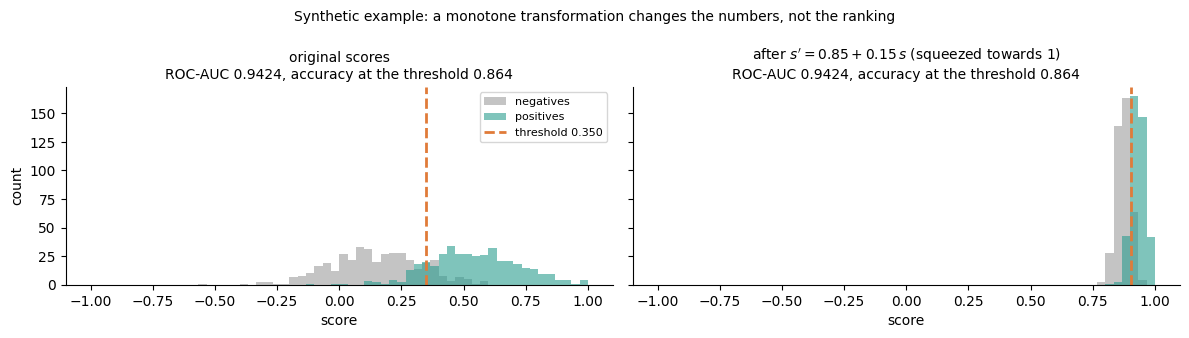

Spearman correlation of original and squeezed scores: 0.9999999999999999


In [17]:
rng_t = np.random.default_rng(0)
s_pos, s_neg = np.clip(rng_t.normal(0.55, 0.18, 400), -1, 1), np.clip(rng_t.normal(0.15, 0.18, 400), -1, 1)
a = 0.85
squeeze = lambda s: a + (1 - a) * s                     # strictly increasing: maps [-1, 1] to [0.70, 1]
thr = 0.35
y = np.r_[np.ones(400), np.zeros(400)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, f, title in zip(axes, [lambda s: s, squeeze], ["original scores", f"after $s' = {a} + {1 - a:.2f}\\,s$ (squeezed towards 1)"]):
    sp, sn, t = f(s_pos), f(s_neg), f(thr)
    ax.hist(sn, bins=60, range=(-1, 1), color=C_IN, alpha=0.6, label="negatives")
    ax.hist(sp, bins=60, range=(-1, 1), color=C_EMB, alpha=0.6, label="positives")
    ax.axvline(t, color=C_HEAD, ls="--", lw=2, label=f"threshold {t:.3f}")
    acc = np.mean((np.r_[sp, sn] >= t) == y)
    ax.set_title(f"{title}\nROC-AUC {roc_auc_score(y, np.r_[sp, sn]):.4f}, accuracy at the threshold {acc:.3f}", fontsize=10)
    ax.set_xlabel("score")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("count")
fig.suptitle("Synthetic example: a monotone transformation changes the numbers, not the ranking", fontsize=10)
plt.tight_layout()
plt.show()
print("Spearman correlation of original and squeezed scores:", stats.spearmanr(np.r_[s_pos, s_neg], squeeze(np.r_[s_pos, s_neg])).statistic)

### The STS-B test: agreement with human judgement

**STS-B** (Semantic Textual Similarity Benchmark, 2017) has 1 379 test pairs of sentences scored by people from 0
(unrelated) to 5 (equivalent), here scaled to $[0, 1]$. The standard measure is a **correlation** between the model's
cosine and the human score:

- **Pearson** $r$: linear correlation of the values themselves,
- **Spearman** $\rho$: the Pearson correlation of the *ranks* (tied values get their average rank); it only asks
  whether the model orders the pairs as people do, so a monotone but non-linear relation still gets $\rho = 1$,
- **Kendall** $\tau$: based on pairs of pairs, the share of concordant minus discordant ones (with a correction for
  ties in the $\tau_b$ variant).

Spearman is the standard for STS because the cosine scale of a model is arbitrary (previous subsection). A value of
0.82 is reported as "82" (×100); it is a correlation, **not** 82 % correct predictions. The toy computation below shows
the difference between Pearson and Spearman.

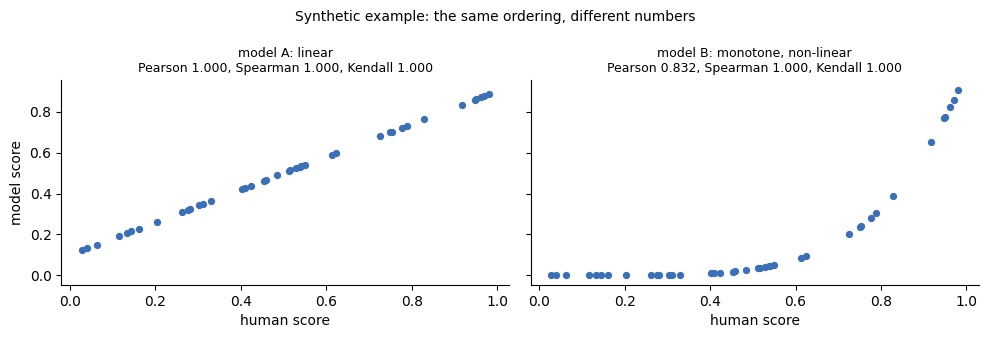

In [18]:
rng_c = np.random.default_rng(1)
human = np.sort(rng_c.uniform(0, 1, 40))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (title, score) in zip(axes, [("model A: linear", 0.1 + 0.8 * human), ("model B: monotone, non-linear", human ** 5)]):
    ax.scatter(human, score, s=18, color=C_BACK)
    ax.set_title(f"{title}\nPearson {stats.pearsonr(human, score).statistic:.3f}, Spearman {stats.spearmanr(human, score).statistic:.3f}, "
                 f"Kendall {stats.kendalltau(human, score).statistic:.3f}", fontsize=9)
    ax.set_xlabel("human score")
axes[0].set_ylabel("model score")
fig.suptitle("Synthetic example: the same ordering, different numbers", fontsize=10)
plt.tight_layout()
plt.show()

For reference, the Sentence-BERT paper (Reimers and Gurevych, 2019, table 1) reports Spearman ×100 on the STS-B test
set: averaged GloVe word vectors 58.0, BERT mean pooling 46.4, BERT's `[CLS]` token 16.5, and a Sentence-BERT trained
on natural-language-inference pairs 77.0 (BERT-base). The often quoted averages over seven STS data sets are a
different column of the same table (61.3, 54.8, 29.2 and 74.9). A Sentence-BERT trained on the STS-B training pairs
reached 84.7 (table 2). Our TF-IDF row is unsupervised: the word weights are computed on the test sentences, no scores
are used. **Before running:** where will the raw MiniLM land relative to TF-IDF?

,Spearman x 100,Pearson x 100
TF-IDF (bag of words),69.9,71.2
"raw MiniLM, mean pooling",51.1,49.4
"raw MiniLM, CLS token",36.4,28.8
all-MiniLM-L6-v2,82.0,82.7
bge-small-en-v1.5,85.9,84.3


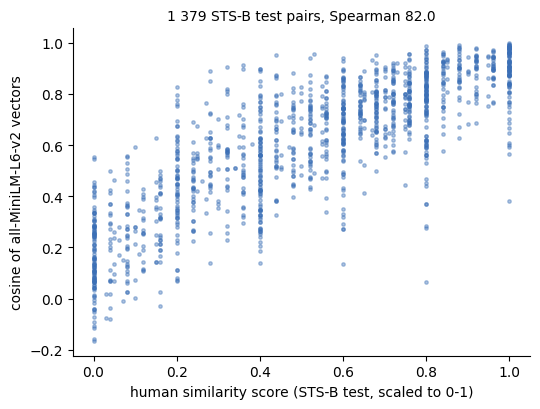

In [19]:
stsb = pd.read_csv(fetch("data/stsb_test.csv"))


def sts_correlations(sim):
    return stats.spearmanr(sim, stsb.score).statistic, stats.pearsonr(sim, stsb.score).statistic


def sts_spearman(encode):
    a, b = encode(stsb.sentence1.tolist()), encode(stsb.sentence2.tolist())
    return stats.spearmanr((a * b).sum(1), stsb.score).statistic


tfidf_sts = TfidfVectorizer(sublinear_tf=True).fit(pd.concat([stsb.sentence1, stsb.sentence2]))
sims = {"TF-IDF (bag of words)": np.asarray(tfidf_sts.transform(stsb.sentence1).multiply(tfidf_sts.transform(stsb.sentence2)).sum(1)).ravel()}
a_mean, a_cls = encode_raw(stsb.sentence1.tolist(), pooling=("mean", "cls"))
b_mean, b_cls = encode_raw(stsb.sentence2.tolist(), pooling=("mean", "cls"))
sims["raw MiniLM, mean pooling"], sims["raw MiniLM, CLS token"] = (a_mean * b_mean).sum(1), (a_cls * b_cls).sum(1)
for name, enc in encoders.items():
    sims[name] = (enc(stsb.sentence1.tolist()) * enc(stsb.sentence2.tolist())).sum(1)
sts_rows = {name: sts_correlations(s)[0] for name, s in sims.items()}
sts_table = pd.DataFrame({name: dict(zip(["Spearman x 100", "Pearson x 100"], np.array(sts_correlations(s)) * 100)) for name, s in sims.items()}).T.round(1)

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(stsb.score, sims["all-MiniLM-L6-v2"], s=6, alpha=0.4, color=C_BACK)
ax.set_xlabel("human similarity score (STS-B test, scaled to 0-1)")
ax.set_ylabel("cosine of all-MiniLM-L6-v2 vectors")
ax.set_title(f"1 379 STS-B test pairs, Spearman {sts_rows['all-MiniLM-L6-v2'] * 100:.1f}", fontsize=10)
plt.tight_layout()
sts_table

The raw MiniLM (about 51) is far *below* a plain word count (about 70): STS-B pairs share many words, so TF-IDF is a
strong baseline here, and the raw vectors rank the pairs worse than that. The same network after contrastive training
reaches 82, and bge-small, a different and larger model (12 layers) trained on a different data mix, 86. The table
does not tell us *which* of these differences (data, amount, architecture, training recipe) causes the gap. Lesson of
this section so far: **an embedding model is a model trained for the similarity you need.**

### Projection heads and what a finished embedding model contains *(projection head: optional depth)*

In general a single-vector embedding model computes

$$H = f_\theta(x) \in \mathbb{R}^{n \times d}, \qquad u = \operatorname{pool}(H), \qquad e = \frac{g_\phi(u)}{\lVert g_\phi(u) \rVert_2},$$

where the **projection head** $g_\phi$ may be the identity (a *head-less* model), a linear layer $W u + b$, or a small
MLP. It is neither the LM head nor a classifier: its output is the embedding. Contrastive learning is a *training
objective*, not a transformation applied at inference: it changes the parameters $\theta$ of the backbone and/or
$\phi$ of the head, and afterwards the model runs an ordinary forward pass. A released embedding checkpoint has
usually gone through such embedding-specific training already (contrastive or other objectives; the model card says
which), so you do not compute a "raw" vector first and transform it.

A linear head without bias, $z_i = W u_i$, changes the geometry: $z_i^\top z_j = u_i^\top W^\top W u_j$, i.e. dot
products are measured with the positive semidefinite matrix $W^\top W$ (for Euclidean distances this is a
(pseudo-)Mahalanobis metric; after normalisation, a generalised cosine). If $k < d$, the map has a null space of
dimension at least $d - k$: directions that the head discards. That is a statement about the space, not about how much
*useful* information is lost. A head can also be square or even widen the vector; its job is to map into the space
the objective needs (a shared image-text space in CLIP, a narrow index in ColBERT).

The two sentence models we use are head-less. Their full inference pipelines, as stored with the checkpoints:

sentence-transformers/all-MiniLM-L6-v2 
 SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
) 

BAAI/bge-small-en-v1.5 
 SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'cls', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)


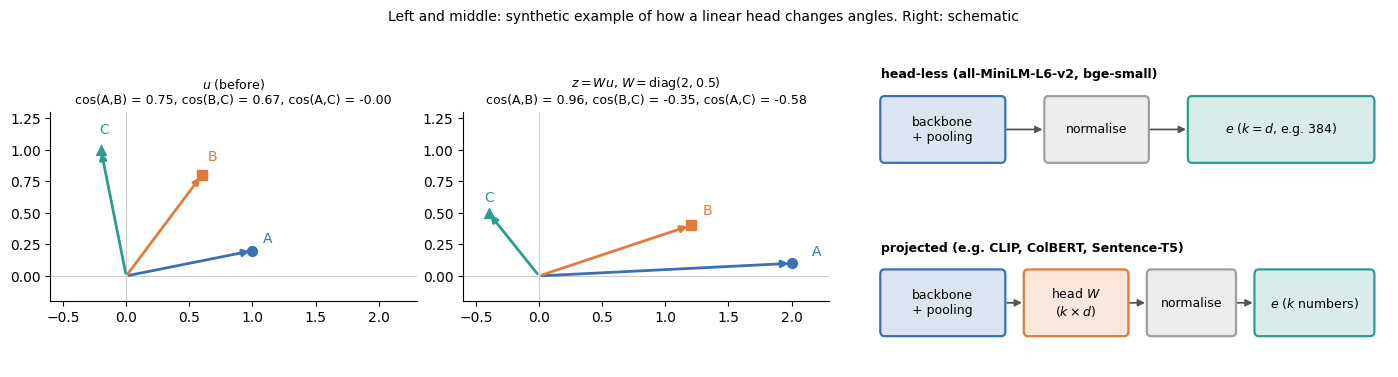

In [20]:
print(ST_NAME, "\n", st_minilm, "\n")
print(BGE_NAME, "\n", st_bge)

# a linear map changes angles: three synthetic 2D points before and after W = diag(2, 0.5)
P = np.array([[1.0, 0.2], [0.6, 0.8], [-0.2, 1.0]])
W = np.diag([2.0, 0.5])
Z = P @ W.T
cos = lambda X: unit(X) @ unit(X).T
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for ax, X, title in zip(axes[:2], [P, Z], ["$u$ (before)", "$z = W u$, $W = \\mathrm{diag}(2, 0.5)$"]):
    for i, (pt, col, mk) in enumerate(zip(X, [C_BACK, C_HEAD, C_EMB], "os^")):
        ax.annotate("", xy=pt, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
        ax.scatter(*pt, color=col, marker=mk, s=50, zorder=3)
        ax.text(pt[0] * 1.08, pt[1] * 1.08 + 0.05, "ABC"[i], fontsize=10, color=col)
    C = cos(X)
    ax.set_title(f"{title}\ncos(A,B) = {C[0, 1]:.2f}, cos(B,C) = {C[1, 2]:.2f}, cos(A,C) = {C[0, 2]:.2f}", fontsize=9)
    ax.set_xlim(-0.6, 2.3)
    ax.set_ylim(-0.2, 1.3)
    ax.set_aspect("equal")
    ax.axhline(0, color="#cccccc", lw=0.8)
    ax.axvline(0, color="#cccccc", lw=0.8)
ax = axes[2]
ax.axis("off")
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
box(ax, 0.1, 3.2, 2.4, 1.0, "backbone\n+ pooling", C_BACK)
box(ax, 3.3, 3.2, 2.0, 1.0, "normalise", C_IN)
box(ax, 6.1, 3.2, 3.6, 1.0, "$e$ ($k = d$, e.g. 384)", C_EMB)
arrow(ax, 2.5, 3.7, 3.3, 3.7)
arrow(ax, 5.3, 3.7, 6.1, 3.7)
ax.text(0.1, 4.5, "head-less (all-MiniLM-L6-v2, bge-small)", fontsize=9, weight="bold")
box(ax, 0.1, 0.5, 2.4, 1.0, "backbone\n+ pooling", C_BACK)
box(ax, 2.9, 0.5, 2.0, 1.0, "head $W$\n($k \\times d$)", C_HEAD)
box(ax, 5.3, 0.5, 1.7, 1.0, "normalise", C_IN)
box(ax, 7.4, 0.5, 2.3, 1.0, "$e$ ($k$ numbers)", C_EMB)
arrow(ax, 2.5, 1.0, 2.9, 1.0)
arrow(ax, 4.9, 1.0, 5.3, 1.0)
arrow(ax, 7.0, 1.0, 7.4, 1.0)
ax.text(0.1, 1.8, "projected (e.g. CLIP, ColBERT, Sentence-T5)", fontsize=9, weight="bold")
fig.suptitle("Left and middle: synthetic example of how a linear head changes angles. Right: schematic", fontsize=10)
plt.tight_layout()
plt.show()

Pooling, head and normalisation differ between model families; a few examples (checked against the model cards and the
stored module configurations; versions of one family can differ, so check the exact checkpoint you use):

| model | backbone | pooling | head | notes |
|---|---|---|---|---|
| `all-MiniLM-L6-v2` | 6-layer encoder | mean | none | normalised; symmetric similarity |
| `bge-small-en-v1.5` | 12-layer encoder | `[CLS]` | none | normalised; an optional instruction for retrieval queries |
| `multilingual-e5-*` | encoder | mean | none | input prefixes `query: ` and `passage: ` are required |
| `Qwen3-Embedding-0.6B` | causal decoder | last token | none | a task instruction before the query; output dimension can be cut (MRL) |
| CLIP (Lecture 05) | separate image and text encoders | `[CLS]`-like / end token | linear projection for each modality | both into one shared space |
| ColBERT, ColPali | encoder / vision-language model | **none** (one vector per token) | per-token linear projection to 128 | scored with MaxSim (end of section 4) |
| `bge-m3` | encoder | `[CLS]` for the dense vector | additional sparse and multi-vector outputs | three kinds of scores from one model |

Two remarks. An **instruction or prefix** (`query: `, *"Represent this sentence for searching relevant passages:"*)
changes the hidden states of the query and thereby the embedding, without any task-specific head. **Matryoshka
representation learning** (MRL) trains the model so that the first 64, 128, 256 … coordinates are also good
embeddings (the loss is summed over these prefixes); cutting the vector of a model *not* trained this way guarantees
nothing. After cutting, normalise again before computing cosines.

### Long texts, chunks and what "relevant" means *(optional)*

An embedding has a fixed dimension, however long the text. The **maximum input length** is a technical limit (longer
inputs are truncated; `all-MiniLM-L6-v2` reads 256 tokens), which is different from how well a long, many-topic text
is represented: a single pooled vector summarises everything it has read, and one relevant sentence in a long text
contributes only a part of it. The experiment below takes one relevant passage, appends natural but unrelated
paragraphs one by one, and compares the similarity of a fixed query to the whole text with its similarity to the best
single paragraph (chunk). **Before running:** what happens to the whole-text similarity, and what happens after 256
tokens?

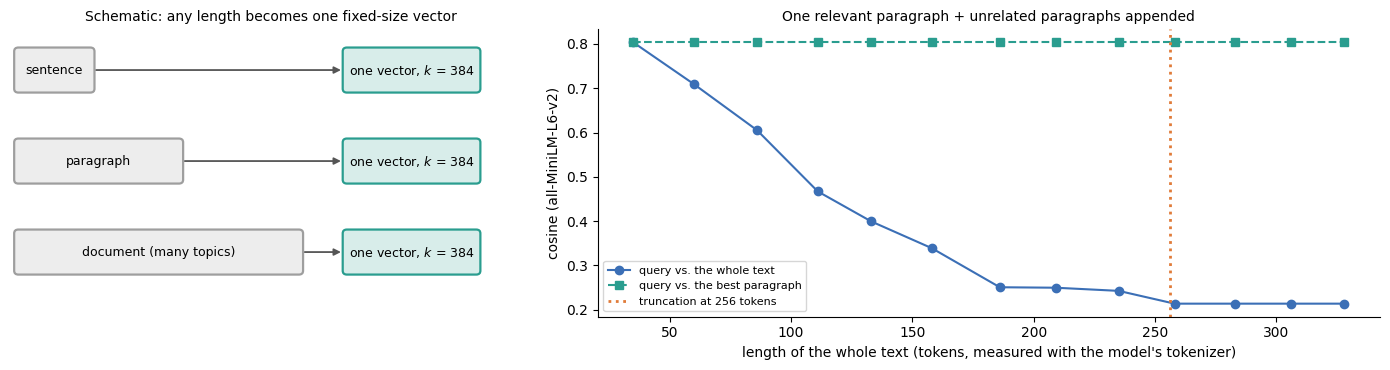

,paragraphs,tokens,truncated,whole text,best chunk
0,1,35,False,0.804,0.804
1,2,60,False,0.709,0.804
2,3,86,False,0.605,0.804
3,4,111,False,0.467,0.804
4,5,133,False,0.400,0.804
5,6,158,False,0.339,0.804
6,7,186,False,0.251,0.804
7,8,209,False,0.250,0.804
8,9,235,False,0.243,0.804
9,10,258,True,0.214,0.804


In [21]:
query_len = "How long should I boil an egg to get a soft yolk?"
relevant_par = ("For a soft yolk, lower the egg into boiling water and cook it for six to seven minutes, "
                "then move it to cold water so that it stops cooking.")
fillers = [  # authored example paragraphs on unrelated topics
    "The city council met on Tuesday to discuss the new bus timetable, which will add evening connections to the northern suburbs from January.",
    "Our football team lost the away game after a late penalty, but the coach said he was pleased with the young players' attitude.",
    "The library will be closed during the holidays; books can be returned through the box next to the main entrance at any time.",
    "Several students asked about the deadline for the project report, which remains the last Friday of the semester at noon.",
    "The museum's new exhibition shows maps of the region from the seventeenth century, together with the instruments used to draw them.",
    "Prices of second-hand bicycles have risen this autumn, and the repair shop on the main square now has a waiting list of two weeks.",
    "A short power outage is planned for Saturday morning while the electricity company replaces an old transformer in the district.",
    "The choir is looking for new tenors and basses; rehearsals take place every Wednesday evening in the hall of the primary school.",
    "Volunteers cleaned the river bank on Sunday and collected more than forty bags of rubbish, mostly plastic bottles and old tyres.",
    "The new café next to the station opens at seven and offers a discount to anyone who brings their own reusable cup.",
    "Tickets for the spring concert of the student orchestra go on sale next Monday, both online and at the box office.",
    "The weather service expects a cold weekend with snow in the mountains and strong wind in the lowlands on Sunday afternoon.",
]
tok_counter = st_minilm.tokenizer
q_vec = encoders["all-MiniLM-L6-v2"]([query_len])[0]
len_rows = []
for m in range(len(fillers) + 1):
    chunks = [relevant_par] + fillers[:m]
    doc = " ".join(chunks)
    n_tok = len(tok_counter(doc).input_ids)                           # with [CLS] and [SEP]
    E = encoders["all-MiniLM-L6-v2"]([doc] + chunks)
    len_rows.append({"paragraphs": m + 1, "tokens": n_tok, "truncated": n_tok > st_minilm.max_seq_length,
                     "whole text": E[0] @ q_vec, "best chunk": (E[1:] @ q_vec).max()})
len_df = pd.DataFrame(len_rows)

fig, (ax0, ax) = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
ax0.axis("off")
ax0.set_xlim(0, 10)
ax0.set_ylim(0, 6)
for i, (label, w) in enumerate([("sentence", 1.5), ("paragraph", 3.2), ("document (many topics)", 5.5)]):
    y0 = 4.7 - 1.9 * i
    box(ax0, 0.1, y0, w, 0.9, label, C_IN)
    arrow(ax0, 0.1 + w, y0 + 0.45, 6.4, y0 + 0.45)
    box(ax0, 6.4, y0, 2.6, 0.9, "one vector, $k$ = 384", C_EMB)
ax0.set_title("Schematic: any length becomes one fixed-size vector", fontsize=10)
ax.plot(len_df.tokens, len_df["whole text"], "o-", color=C_BACK, label="query vs. the whole text")
ax.plot(len_df.tokens, len_df["best chunk"], "s--", color=C_EMB, label="query vs. the best paragraph")
ax.axvline(st_minilm.max_seq_length, color=C_HEAD, ls=":", lw=2, label=f"truncation at {st_minilm.max_seq_length} tokens")
ax.set_xlabel("length of the whole text (tokens, measured with the model's tokenizer)")
ax.set_ylabel("cosine (all-MiniLM-L6-v2)")
ax.set_title("One relevant paragraph + unrelated paragraphs appended", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
len_df.round(3)

The whole-text similarity falls as unrelated paragraphs are added, because the relevant paragraph becomes a smaller
part of what the mean pooling averages; the best-chunk similarity does not move (the relevant paragraph is always one
of the chunks). After 256 tokens the whole-text curve stops changing: the model no longer reads the end of the text,
whatever it contains. This is one constructed example, not a benchmark: with other texts or models the curve can be
flatter or not monotone, and very short chunks lose context of their own. It is the reason RAG systems index **chunks**
and why the chunk size is a parameter to validate (Lecture 08).

**Relevance depends on the task.** *Symmetric* tasks compare texts of the same kind (paraphrases, duplicate
questions: STS-B, Quora). *Asymmetric* retrieval compares a short query with a passage that **answers** it; the two are
neither lexically nor semantically equivalent (*"How long to boil an egg?"* vs. a paragraph about cooking times).
"Relevant" can also mean the same topic, the same sentiment, a matching image, or a regulation that applies to a
case. In legal or technical documents the hard negatives are passages that look the same but differ in one
condition, number or exception. No single model is best for all of these: check what pairs a model was trained on.

## 3. Semantic search, measured

This is the retrieval half of a RAG system (Lecture 08 adds the generation half):

```
offline:  documents ──► chunks ──► embedding model ──► vectors (index)
online:   question ──► embedding model ──► query vector ──► top-k most similar chunks ──► language model ──► answer
                                                           └──────── measured here ────────┘
```

The benchmark of Lecture 05: a **corpus** of 10 000 Quora questions and 1 000 **queries**, each with one to five
duplicates in the corpus (questions that Quora's moderators marked as asking the same thing). Here "relevant" means
*annotated as a duplicate*: the unit of relevance is a whole question, and a corpus question that is about the same
thing but was never labelled counts as not relevant. Lecture 05, section 4, has the long version of this section.

In [22]:
ret = pd.read_csv(fetch("data/quora_retrieval.csv", "L05_embeddings"))
queries = ret[ret.role == "query"].reset_index(drop=True)
corpus = ret[ret.role == "corpus"].reset_index(drop=True)
relevant = [np.flatnonzero(corpus.group.values == g) for g in queries.group]
assert all(len(r) > 0 for r in relevant)          # every query has at least one relevant document (no empty sets below)
print(f"{len(queries)} queries, {len(corpus)} documents, {sum(map(len, relevant))} relevant documents "
      f"({np.mean([len(r) for r in relevant]):.2f} per query); largest possible recall@1: {np.mean([1 / len(r) for r in relevant]):.3f}")
for k in (1, 5):
    print(f"\nquery:    {queries.text[k]}")
    for d in relevant[k]:
        print(f"relevant: {corpus.text[d]}")

1000 queries, 10000 documents, 1275 relevant documents (1.27 per query); largest possible recall@1: 0.897

query:    How can I make a perfect BBQ steak?
relevant: What makes a perfect steak?

query:    What is the best university degree for data science, and at which university?
relevant: What are the best schools for a degree in data science?


### Four retrievers and the metrics

- **TF-IDF**: sparse bag-of-words vectors, cosine similarity; only exact word matches count.
- **BM25** (Robertson et al., 1995; the default of Lucene and Elasticsearch): a scoring formula for word matches with
  term-frequency saturation and document-length normalisation; still the keyword baseline to beat. Ten lines by hand
  below. BM25 itself says nothing about how words are found: *our* implementation splits on word characters and uses
  exact tokens, without stemming or lemmatisation.
- **Dense retrieval**: cosine of embedding vectors; here `all-MiniLM-L6-v2` and `bge-small-en-v1.5`.
- **Hybrid**: reciprocal rank fusion (Cormack et al., 2009) of BM25 and a dense model,
  $\text{RRF}(d) = \sum_r 1 / (60 + \text{rank}_r(d))$, ranks counted from 1. Only the top 100 of every list take part
  (`depth = 100`); a document outside all fused top-lists gets 0, so the RRF order beyond about rank 100 carries no
  information and metrics at such depths should not be read for the hybrid.

**Scoring function vs. evaluation metric.** Cosine, dot product, BM25, RRF (and later MaxSim) *score* a query-document
pair; they need no labels. An **evaluation metric** compares the resulting ranking with the annotated relevant set
$R_q$ of a query. The ones in the table: **recall@k** (share of $R_q$ in the top $k$; with two relevant documents and
one slot, recall@1 cannot exceed one half, so its ceiling on this data is 0.897), **hit@1** (is the first result
relevant?), **MRR@10** (mean over queries of $1/\text{rank}$ of the first relevant result, 0 if it is not in the top
10), **nDCG@10** and **MAP@10** (defined with a toy example below). Ties in the scores are broken by the document index
(lower first) in every ranking of this notebook.

**Before running:** will the dense models beat BM25 on recall@10, and by how much? Can the hybrid be worse than the
better of its two parts?

In [23]:
class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.vec = CountVectorizer(token_pattern=r"(?u)\b\w+\b")             # exact tokens, lowercased, no stemming
        tf = self.vec.fit_transform(docs).tocoo().astype(np.float64)        # documents x words, raw counts
        n_docs, df = tf.shape[0], np.bincount(tf.col, minlength=tf.shape[1])
        idf = np.log(1 + (n_docs - df + 0.5) / (df + 0.5))
        dl = np.asarray(tf.sum(1)).ravel()
        weight = tf.data * (k1 + 1) / (tf.data + k1 * (1 - b + b * dl[tf.row] / dl.mean())) * idf[tf.col]
        self.W = sparse.csr_matrix((weight, (tf.row, tf.col)), shape=tf.shape)

    def scores(self, texts):
        q = self.vec.transform(texts)
        q.data[:] = 1.0                                   # a query word counts once, however often it occurs
        return np.asarray((q @ self.W.T).todense())


def rank_metrics(ranked_grades, all_grades, k):
    # ranked_grades: relevance grades (0 = not relevant) of the returned documents in rank order; a list shorter than k
    #   is padded with non-relevant positions; all_grades: grades (> 0) of ALL annotated relevant documents of the query.
    # Conventions: binary metrics treat grade > 0 as relevant; AP@k divides by min(k, |R|); nDCG uses the gain
    # 2^grade - 1 and the ideal ranking of all annotated relevant documents; a query with |R| = 0 is an error here
    # (benchmarks either drop such queries or define their own convention).
    g = np.zeros(k)
    top = np.asarray(ranked_grades[:k], dtype=float)
    g[:len(top)] = top
    rel = (g > 0).astype(float)
    n_rel = int((np.asarray(all_grades) > 0).sum())
    if n_rel == 0:
        raise ValueError("query without relevant documents")
    first = np.flatnonzero(rel)
    disc = 1 / np.log2(np.arange(2, k + 2))
    ideal = np.sort(np.asarray(all_grades, dtype=float))[::-1][:k]
    return {f"P@{k}": rel.sum() / k, f"R@{k}": rel.sum() / n_rel, f"Hit@{k}": float(rel.any()),
            f"RR@{k}": 1 / (first[0] + 1) if len(first) else 0.0,
            f"AP@{k}": (rel.cumsum() / np.arange(1, k + 1) * rel).sum() / min(k, n_rel),
            f"nDCG@{k}": ((2 ** g - 1) * disc).sum() / ((2 ** ideal - 1) * disc[:len(ideal)]).sum()}


def ranks_of_relevant(S):
    # rank (1 = best) of every relevant document for every query, ties broken by the document index (lower first),
    # the same rule as np.argsort(-S, kind="stable"); counting instead of sorting the whole 1000 x 10000 matrix
    idx = np.arange(S.shape[1])
    out = []
    for q, r in enumerate(relevant):
        s = S[q]
        out.append(np.array([1 + np.sum(s > s[d]) + np.sum((s == s[d]) & (idx < d)) for d in r]))
    return out


def evaluate(S, name, ks=(1, 5, 10, 100)):
    rk = ranks_of_relevant(S)
    row = {"retriever": name}
    for k in ks:
        row[f"recall@{k}"] = np.mean([np.mean(r <= k) for r in rk])
    first = np.array([r.min() for r in rk])
    row["hit@1"] = np.mean(first == 1)
    row["MRR@10"] = np.mean(np.where(first <= 10, 1 / first, 0))
    per_query = []
    for r in rk:
        grades = np.zeros(10)
        grades[r[r <= 10] - 1] = 1
        per_query.append(rank_metrics(grades, np.ones(len(r)), 10))
    row["nDCG@10"] = np.mean([m["nDCG@10"] for m in per_query])
    row["MAP@10"] = np.mean([m["AP@10"] for m in per_query])
    return row, first


def rrf(*score_matrices, k=60, depth=100):
    fused = np.zeros(score_matrices[0].shape)
    rows_ = np.arange(len(fused))[:, None]
    for S in score_matrices:
        top = np.argsort(-S, axis=1, kind="stable")[:, :depth]     # ranks 1 ... depth; documents below depth get nothing
        fused[rows_, top] += 1.0 / (k + np.arange(1, depth + 1))[None, :]
    return fused


# tests: the ranking with ties, the RRF cut-off, the metric conventions
_S1, _S2 = np.array([[3.0, 2, 1, 0]]), np.array([[0.0, 1, 2, 3]])
assert np.allclose(rrf(_S1, _S2, depth=2), [[1 / 61, 1 / 62, 1 / 62, 1 / 61]])
assert np.allclose(rrf(_S1, depth=2), [[1 / 61, 1 / 62, 0, 0]])                        # below the depth: nothing
assert rank_metrics([1, 0, 0], [1], 3)["RR@3"] == 1 and rank_metrics([0, 0, 0], [1], 3)["nDCG@3"] == 0
assert np.isclose(rank_metrics([1], [1, 1], 5)["P@5"], 0.2)                             # a short ranking is padded
print("ranking tests passed")

ranking tests passed


In [24]:
tfidf = TfidfVectorizer(sublinear_tf=True).fit(corpus.text)
S_tfidf = (tfidf.transform(queries.text) @ tfidf.transform(corpus.text).T).toarray()
bm25 = BM25(corpus.text)
S_bm25 = bm25.scores(queries.text)


def cached_embeddings(filename, model_name, compute):
    # The benchmark vectors of the two pretrained models are shared with the original notebook (outputs/, computed on a
    # GPU by the same library call). They carry no stored configuration, so they are verified by re-encoding a few
    # queries and documents. RECOMPUTE_EMBEDDINGS = True (GPU) writes a fresh copy with its configuration to OUT_DIR.
    local = OUT_DIR / filename
    meta = {"model": model_name, "revision": REVISIONS[model_name], "queries": text_hash(queries.text), "corpus": text_hash(corpus.text),
            "pooling": "model default", "normalised": True, "dtype": "float16"}
    if TRAIN and RECOMPUTE_EMBEDDINGS:
        Q, D = compute(queries.text.tolist()), compute(corpus.text.tolist())
        save_npz(local, meta, queries=Q.astype(np.float16), corpus=D.astype(np.float16))
    z = load_checked(local, meta) if local.exists() else np.load(fetch(f"outputs/{filename}"))
    Q, D = z["queries"].astype(np.float32), z["corpus"].astype(np.float32)
    assert Q.shape == (len(queries), Q.shape[1]) and D.shape == (len(corpus), Q.shape[1])
    sample = np.arange(0, len(queries), 100)
    diff = max(spot_check(Q[sample], compute, queries.text[sample]), spot_check(D[sample * 10], compute, corpus.text[sample * 10]))
    print(f"{filename}: {Q.shape[0]} + {D.shape[0]} vectors, re-encoding check on 20 texts: max difference {diff:.1e}")
    return Q, D


Q_minilm, D_minilm = cached_embeddings("emb_quora_all_minilm.npz", ST_NAME, encoders["all-MiniLM-L6-v2"])
Q_bge, D_bge = cached_embeddings("emb_quora_bge_small.npz", BGE_NAME, encoders["bge-small-en-v1.5"])
S_minilm, S_bge = Q_minilm @ D_minilm.T, Q_bge @ D_bge.T

results, first_rank, scores_by_name = [], {}, {}
for name, S in [("TF-IDF", S_tfidf), ("BM25", S_bm25), ("dense: all-MiniLM-L6-v2", S_minilm), ("dense: bge-small-en-v1.5", S_bge),
                ("hybrid: BM25 + bge-small (RRF)", rrf(S_bm25, S_bge))]:
    row, first_rank[name] = evaluate(S, name)
    results.append(row)
    scores_by_name[name] = S
pd.DataFrame(results).set_index("retriever").round(3)

emb_quora_all_minilm.npz: 1000 + 10000 vectors, re-encoding check on 20 texts: max difference 6.1e-05


emb_quora_bge_small.npz: 1000 + 10000 vectors, re-encoding check on 20 texts: max difference 1.2e-04


,recall@1,recall@5,recall@10,recall@100,hit@1,MRR@10,nDCG@10,MAP@10
retriever,,,,,,,,
TF-IDF,0.829,0.970,0.984,0.997,0.922,0.949,0.952,0.937
BM25,0.836,0.967,0.980,0.996,0.930,0.951,0.952,0.938
dense: all-MiniLM-L6-v2,0.884,0.996,1.000,1.000,0.986,0.992,0.993,0.990
dense: bge-small-en-v1.5,0.891,0.999,1.000,1.000,0.994,0.997,0.997,0.995
hybrid: BM25 + bge-small (RRF),0.866,0.985,0.994,1.000,0.967,0.979,0.979,0.972


**Before reading on:** the dense models win, but one of the two numbers is less trustworthy than the other. Which, and
why? (Answer in section 4.) The differences come from a few dozen harder queries; two of each kind:

In [25]:
def show_disagreement(winner, loser, n=2):
    gain = first_rank[loser] - first_rank[winner]
    for q in np.argsort(-gain, kind="stable")[:n]:
        top = np.argmax(scores_by_name[loser][q])                     # argmax returns the lowest index among ties
        best_rel = relevant[q][np.argmax(scores_by_name[winner][q, relevant[q]])]
        print(f"query:      {queries.text[q]}")
        print(f"relevant:   {corpus.text[best_rel]}   (rank {first_rank[winner][q]} with {winner}, rank {first_rank[loser][q]} with {loser})")
        print(f"{loser} top-1: {corpus.text[top]}\n")


print("=== the dense model finds it, BM25 does not ===\n")
show_disagreement("dense: bge-small-en-v1.5", "BM25")
print("=== BM25 finds it, the dense model does not ===\n")
show_disagreement("BM25", "dense: bge-small-en-v1.5")

=== the dense model finds it, BM25 does not ===

query:      Which is the best way to download movies?
relevant:   How can I download movie?   (rank 1 with dense: bge-small-en-v1.5, rank 273 with BM25)
BM25 top-1: Which is the best way to learn assembly language?

query:      Which is the best site to learn coding online for beginners?
relevant:   What is the best website to learn code as a beginner?   (rank 1 with dense: bge-small-en-v1.5, rank 88 with BM25)
BM25 top-1: Which is best book to learn R-programming for beginners?

=== BM25 finds it, the dense model does not ===

query:      Can you overcome fear of something, or only alleviate it?
relevant:   How do I overcome fear of someone or something?   (rank 1 with BM25, rank 2 with dense: bge-small-en-v1.5)
dense: bge-small-en-v1.5 top-1: How can I overcome this fear?

query:      How do entrepreneurs come up with new startup ideas?
relevant:   How do people come up with new ideas/be creative?   (rank 1 with BM25, rank 2 with dense

Dense vectors handle paraphrases (different words, same meaning). Our BM25 uses exact tokens without stemming, so
*movies* and *movie* are different words to it, and the frequent words of a query (*which is the best way to*) pull in
unrelated questions that share them. On these short questions the dense model is rarely far off: where BM25 wins, the
relevant question is still near the top of the dense list. Keyword search earns its place on rare exact terms, names,
codes and numbers, which a small embedding model blurs into a general topic (Lecture 05 shows such cases).

**What this benchmark does and does not measure.** It is *easy*: all retrievers have recall@10 of about 0.98 or more, so the
numbers sit near the ceiling and differences of a few thousandths are a handful of queries. It measures whether the
**annotated** duplicates are found. Look at the query about overcoming fear above: the dense model's first result
(*"How can I overcome this fear?"*) is arguably as good a duplicate as the labelled one, but it was never annotated, so
it counts as a miss. Missing labels are not proof of irrelevance, and the duplicate groups themselves can
be imperfect. The hybrid is a compromise to be **measured on your own data**: on this data set and with equal weights
it is *worse* than bge-small alone, because rank fusion gives the weaker BM25 an equal vote. That is a result for this
benchmark, not a general verdict on hybrid search (it often helps on data with names, codes and rare terms).
Weighted RRF, $\sum_r w_r / (60 + \text{rank}_r)$, is a common fix; the weights are chosen on validation queries, never
on the test queries.

**Your turn:** search the corpus with your own question.

In [26]:
def search(query, top=5):
    s_dense = encoders["bge-small-en-v1.5"]([query]) @ D_bge.T
    s_bm25 = bm25.scores([query])[0]
    out = pd.DataFrame({"dense (bge-small)": [f"{s_dense[0, k]:.3f}  {corpus.text[k]}" for k in np.argsort(-s_dense[0], kind="stable")[:top]],
                        "BM25": [f"{s_bm25[k]:.1f}  {corpus.text[k]}" for k in np.argsort(-s_bm25, kind="stable")[:top]]})
    with pd.option_context("display.max_colwidth", 90):
        display(out)


search("Which programming language should a beginner learn first?")

,dense (bge-small),BM25
0,0.907 Which programming languages should I start learning?,"22.9 Which Programming Language Should I Learn, C# Or C++?"
1,0.895 What is the best programming language one should start with?,21.9 What is the first programming languange to learn for a total beginner?
2,0.883 What is the first programming languange to learn for a total beginner?,19.8 Which programming Languages should I learn?
3,0.873 Which programming Languages should I learn?,17.9 Which backend programming language is the best to learn and why?
4,0.861 What is the programming language to learn?,17.8 What is the programming language to learn?


### Retrieval metrics on a toy example

For a query $q$ let $R_q$ be the set of annotated relevant documents, $T_k$ the top $k$ results and
$\mathrm{rel}_i \in \{0, 1\}$ (or a grade $0, 1, 2, \dots$) the relevance of the document at rank $i$.

| metric | definition | what it rewards |
|---|---|---|
| Precision@k | $\lvert R_q \cap T_k \rvert / k$ | few irrelevant results in the top $k$ |
| Recall@k | $\lvert R_q \cap T_k \rvert / \lvert R_q \rvert$ | finding all known relevant documents |
| Hit@k (success@k) | $\mathbb{1}\{\lvert R_q \cap T_k \rvert > 0\}$ | at least one relevant result |
| RR@k | $1/r$ for the first relevant rank $r \le k$, else 0 | an early first hit; ignores the rest |
| MRR@k | mean of RR@k over queries | |
| AP@k | $\sum_{i=1}^{k} P@i \cdot \mathrm{rel}_i \,/\, \min(k, \lvert R_q \rvert)$ (binary) | all relevant documents, early |
| MAP@k | mean of AP@k over queries | |
| DCG@k | $\sum_{i=1}^{k} (2^{\mathrm{rel}_i} - 1) / \log_2(i + 1)$ | graded relevance, early positions weigh more |
| nDCG@k | DCG@k / IDCG@k, where IDCG is the DCG of the ideal order of **all** annotated relevant documents | the same, scaled to $[0, 1]$ |

Conventions matter and should be reported: the value of $k$, the unit of relevance (question, chunk, page, document),
the denominator of AP (here $\min(k, \lvert R_q \rvert)$; other benchmarks divide by $\lvert R_q \rvert$), the gain of
nDCG (here $2^{\mathrm{rel}} - 1$; some use $\mathrm{rel}$), what happens with queries that have no relevant document
(benchmarks usually exclude them; our function raises an error
rather than divide by zero silently, and this benchmark has none: every query has at least one duplicate) and with ties. For one query, MRR is just RR. Recall here is about
*known* relevant documents; whether the retrieved text is *sufficient* to answer a RAG question needs its own
annotation (Lecture 08).

Three rankings of the same ten documents, three of them relevant. **Before running:** which ranking is best by RR, by
recall@5, by nDCG@5?

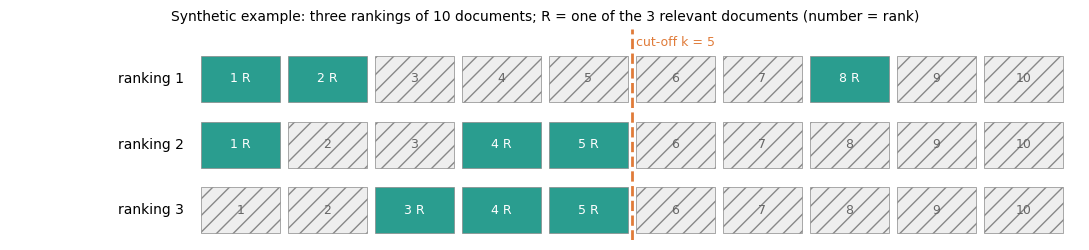

,P@5,R@5,Hit@5,RR@5,AP@5,nDCG@5
ranking 1,0.4,0.667,1.0,1.000,0.667,0.765
ranking 2,0.6,1.000,1.0,1.000,0.700,0.853
ranking 3,0.6,1.000,1.0,0.333,0.478,0.618


,R@5,RR@5,nDCG@5
grade 2 first,1.0,1.0,1.000
grade 1 first,1.0,1.0,0.797


In [27]:
toy_rankings = {"ranking 1": (1, 2, 8), "ranking 2": (1, 4, 5), "ranking 3": (3, 4, 5)}      # positions of the 3 relevant documents
K = 5
toy_rows = {}
fig, ax = plt.subplots(figsize=(11, 2.6))
for row_i, (name, pos) in enumerate(toy_rankings.items()):
    grades = np.zeros(10)
    grades[np.array(pos) - 1] = 1
    toy_rows[name] = rank_metrics(grades, np.ones(3), K)
    y = 2 - row_i
    for i in range(10):
        relv = grades[i] > 0
        ax.add_patch(patches.Rectangle((i, y), 0.9, 0.7, fc=C_EMB if relv else "#eeeeee", ec="#888888", lw=0.5, hatch=None if relv else "//"))
        ax.text(i + 0.45, y + 0.35, f"{i + 1}" + (" R" if relv else ""), ha="center", va="center", fontsize=9, color="white" if relv else "#666666")
    ax.text(-0.2, y + 0.35, name, ha="right", va="center", fontsize=10)
ax.axvline(K - 0.05, color=C_HEAD, ls="--", lw=2)
ax.text(K - 0.05, 2.85, f" cut-off k = {K}", color=C_HEAD, fontsize=9)
ax.set_xlim(-2.2, 10.1)
ax.set_ylim(-0.1, 3.1)
ax.axis("off")
ax.set_title("Synthetic example: three rankings of 10 documents; R = one of the 3 relevant documents (number = rank)", fontsize=10)
plt.tight_layout()
plt.show()
display(pd.DataFrame(toy_rows).T.round(3))

# graded relevance: the same two documents in swapped order (grade 2 = highly relevant, 1 = partly relevant)
graded = {"grade 2 first": [2, 1, 0, 0, 0], "grade 1 first": [1, 2, 0, 0, 0]}
pd.DataFrame({k: rank_metrics(v, [2, 1], K) for k, v in graded.items()}).T[[f"R@{K}", f"RR@{K}", f"nDCG@{K}"]].round(3)

Rankings 1 and 2 have the same RR (the first result is relevant) but different recall and nDCG (ranking 1 misses one
relevant document in the top 5). Rankings 2 and 3 have the same recall (all three in the top 5) but different RR and
nDCG (ranking 3 makes the user wait until rank 3). With graded relevance, binary metrics cannot see that the more
relevant document should come first; nDCG can. No single number describes a ranking: choose the metric that matches
how the results will be used (RAG with $k$ chunks in the prompt: recall@k; a search page: nDCG or MRR).

## 4. Contrastive fine-tuning, live

Section 2 claimed that contrastive training turns a language model into an embedding model. We do it now, on the raw
MiniLM, with 20 000 pairs of duplicate questions from the full Quora data set (none of them in the benchmark above;
checked below). The ingredients, one by one:

- **Positive pairs** $(q_i, d_i)$: two texts that should be close (here two questions marked as duplicates; in RAG a
  question and a passage that answers it).
- **Negatives**: texts that should be further away. **In-batch negatives** need no labels: in a batch of $B$ pairs, the
  other $B - 1$ documents serve as negatives for $q_i$. Most of them are *easy* (unrelated topics). **Hard negatives**
  look similar but are not positives (section 2); mining them makes training more informative, and they can be added as
  extra columns of the matrix below.
- **One shared encoder**: both sides of a pair go through the same network (same parameters); its outputs are pooled
  and normalised, giving matrices $Q, D \in \mathbb{R}^{B \times k}$ with unit rows.

### Similarity matrix and loss

$S = Q D^\top$ holds all $B \times B$ cosines, $S_{ij} = \mathbf{q}_i \cdot \mathbf{d}_j$; the true pairs are on the
diagonal. Each row is treated as a classification problem with $B$ classes, "which document is mine?":

$$\mathcal{L}_{Q \to D} = -\frac{1}{B}\sum_{i=1}^{B} \log \frac{\exp(S_{ii} / \tau)}{\sum_{j=1}^{B} \exp(S_{ij} / \tau)},
\qquad \mathcal{L} = \tfrac{1}{2}\left(\mathcal{L}_{Q \to D} + \mathcal{L}_{D \to Q}\right).$$

This is the InfoNCE loss: a cross-entropy over the batch with temperature $\tau$. Our code uses the symmetric version
(every duplicate also has to find its question, as in CLIP, Lecture 05) with `scale = 20`, i.e. $\tau = 0.05$.
`MultipleNegativesRankingLoss` in `sentence-transformers` uses the same scale and, by default, only the direction
$Q \to D$. For one row $i$ (before the averaging) the gradient with respect to the scores is

$$\frac{\partial \ell_i}{\partial S_{ij}} = \frac{p_{ij} - \mathbb{1}[i = j]}{\tau}, \qquad p_{ij} = \operatorname{softmax}_j(S_{ij} / \tau):$$

the positive score is pushed up by $(1 - p_{ii}) / \tau$ and every negative down by $p_{ij} / \tau$, most strongly the
negatives the model currently confuses with the positive. For the whole loss add the factor $1 / B$ and the second
direction. Because all pairs share the parameters, one step improves the batch on average, not necessarily every pair.
**What matters is the score of the positive *relative* to the negatives of the same row**, not its absolute value:

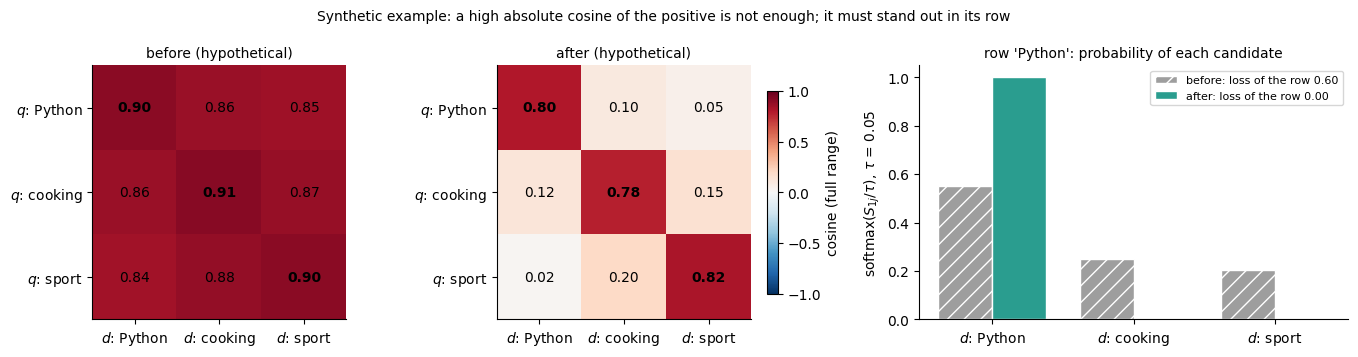

In [28]:
topics = ["Python", "cooking", "sport"]
S_before = np.array([[0.90, 0.86, 0.85], [0.86, 0.91, 0.87], [0.84, 0.88, 0.90]])     # high cosines everywhere (a cone)
S_after = np.array([[0.80, 0.10, 0.05], [0.12, 0.78, 0.15], [0.02, 0.20, 0.82]])      # lower diagonal, but well separated
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, (title, S_) in zip(axes[:2], [("before (hypothetical)", S_before), ("after (hypothetical)", S_after)]):
    im = ax.imshow(S_, vmin=-1, vmax=1, cmap="RdBu_r")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{S_[i, j]:.2f}", ha="center", va="center", fontsize=10, weight="bold" if i == j else "normal")
    ax.set_xticks(range(3), [f"$d$: {t}" for t in topics])
    ax.set_yticks(range(3), [f"$q$: {t}" for t in topics])
    ax.set_title(title, fontsize=10)
plt.colorbar(im, ax=axes[1], shrink=0.8, label="cosine (full range)")
tau = 0.05
width = 0.38
for k, (label, S_, col) in enumerate([("before", S_before, C_IN), ("after", S_after, C_EMB)]):
    p_row = torch.softmax(torch.tensor(S_[0] / tau), 0).numpy()
    axes[2].bar(np.arange(3) + (k - 0.5) * width, p_row, width, color=col, label=f"{label}: loss of the row {-np.log(p_row[0]):.2f}",
                hatch=None if k else "//", edgecolor="white")
axes[2].set_xticks(range(3), [f"$d$: {t}" for t in topics])
axes[2].set_ylabel(r"softmax$(S_{1j} / \tau)$, $\tau$ = 0.05")
axes[2].set_title("row 'Python': probability of each candidate", fontsize=10)
axes[2].legend(fontsize=8)
fig.suptitle("Synthetic example: a high absolute cosine of the positive is not enough; it must stand out in its row", fontsize=10)
plt.tight_layout()
plt.show()

### Where the gradient flows

Mean pooling and the normalisation have no parameters, yet the gradient passes through them to every token state and
from there into the backbone. In **full fine-tuning** all backbone parameters change, and with them the contextual
token states themselves. In **head-only** training the backbone is frozen (no gradient is applied to it) and only a
small projection head learns; the head can only re-arrange what the frozen pooled vector already contains. We measure
both below.

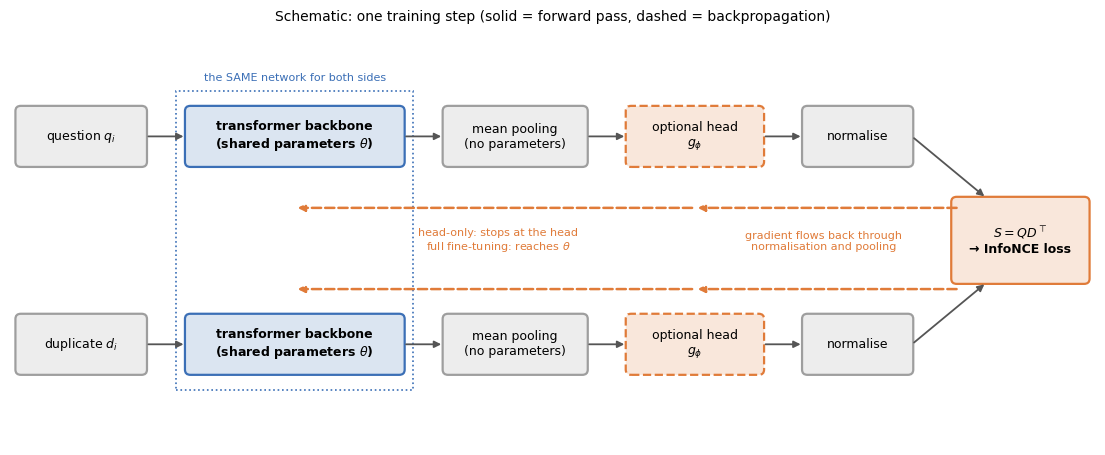

In [29]:
fig, ax = canvas(16, 6.4, (14, 5.4))
for y0, side in [(4.3, "question $q_i$"), (1.1, "duplicate $d_i$")]:
    box(ax, 0.1, y0, 1.9, 0.9, side, C_IN)
    box(ax, 2.6, y0, 3.2, 0.9, "transformer backbone\n(shared parameters $\\theta$)", C_BACK, weight="bold")
    box(ax, 6.4, y0, 2.1, 0.9, "mean pooling\n(no parameters)", C_IN)
    box(ax, 9.1, y0, 2.0, 0.9, "optional head\n$g_\\phi$", C_HEAD, ls="--")
    box(ax, 11.7, y0, 1.6, 0.9, "normalise", C_IN)
    for x0, x1 in [(2.0, 2.6), (5.8, 6.4), (8.5, 9.1), (11.1, 11.7)]:
        arrow(ax, x0, y0 + 0.45, x1, y0 + 0.45)
box(ax, 13.9, 2.5, 2.0, 1.3, "$S = Q D^\\top$\n→ InfoNCE loss", C_HEAD, weight="bold")
arrow(ax, 13.3, 4.75, 14.4, 3.8)
arrow(ax, 13.3, 1.55, 14.4, 2.5)
for y in (3.65, 2.4):                       # backpropagation arrows, right to left
    arrow(ax, 14.0, y, 10.1, y, color=C_HEAD, ls="--", lw=1.8)
    arrow(ax, 10.1, y, 4.2, y, color=C_HEAD, ls="--", lw=1.8)
ax.text(12.0, 3.0, "gradient flows back through\nnormalisation and pooling", fontsize=8, color=C_HEAD, ha="center")
ax.text(7.2, 3.0, "head-only: stops at the head\nfull fine-tuning: reaches $\\theta$", fontsize=8, color=C_HEAD, ha="center")
ax.add_patch(patches.Rectangle((2.45, 0.85), 3.5, 4.6, fill=False, ec=C_BACK, ls=":", lw=1.2))
ax.text(4.2, 5.6, "the SAME network for both sides", fontsize=8, color=C_BACK, ha="center")
ax.set_title("Schematic: one training step (solid = forward pass, dashed = backpropagation)", fontsize=10)
plt.show()

### False negatives in the batch

In-batch negatives are **assumed** negatives. If two pairs in a batch ask the same thing (Quora has many questions
about learning Python), the loss pushes apart two texts that should be close: a **false negative**. A larger batch
gives more (and harder) negatives per step, but also more false negatives and more memory; a batch of 16 is not
automatically worse than 64, it is a trade-off to validate. Remedies: group-aware sampling (never put two pairs of the
same duplicate group into one batch), deduplication, a multi-positive loss, or masking known positives in $S$.

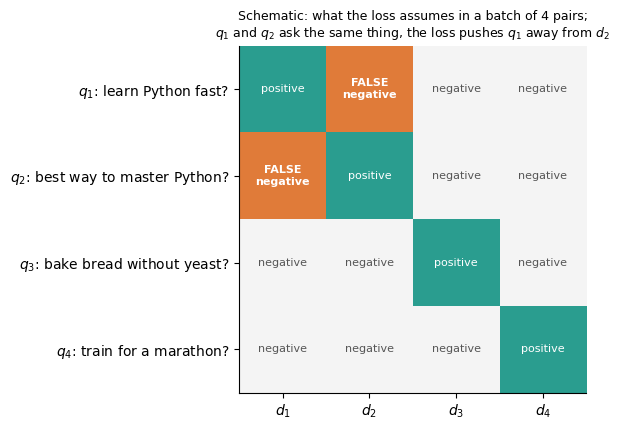

In [30]:
lbl = ["learn Python fast?", "best way to master Python?", "bake bread without yeast?", "train for a marathon?"]
M = np.eye(4)
M[0, 1] = M[1, 0] = 0.5                   # two pairs with the same intent in one batch
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.imshow(M, cmap=ListedColormap(["#f4f4f4", C_HEAD, C_EMB]), vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        txt = "positive" if i == j else ("FALSE\nnegative" if M[i, j] == 0.5 else "negative")
        ax.text(j, i, txt, ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0 else "#555555", weight="bold" if M[i, j] == 0.5 else "normal")
ax.set_xticks(range(4), [f"$d_{j + 1}$" for j in range(4)])
ax.set_yticks(range(4), [f"$q_{i + 1}$: {t}" for i, t in enumerate(lbl)])
ax.set_title("Schematic: what the loss assumes in a batch of 4 pairs;\n$q_1$ and $q_2$ ask the same thing, the loss pushes $q_1$ away from $d_2$", fontsize=9)
plt.tight_layout()
plt.show()

The code: the data, the loss in two lines and the training loop. Two details of the loop: the last, incomplete batch of
an epoch is used too (unless it has a single pair, which would have no in-batch negative), and the maximum input length
is 64 tokens in training and in evaluation alike (the printed share shows how rarely it cuts a question).

In [31]:
train_pairs = pd.read_csv(fetch("data/quora_train_pairs.csv"))
print(len(train_pairs), "training pairs, e.g.")
display(train_pairs.sample(3, random_state=SEED))


def norm_text(s):
    import re, unicodedata
    return re.sub(r"[\s?.!]+$", "", re.sub(r"\s+", " ", unicodedata.normalize("NFKC", s).casefold()).strip())


# split audit: no training question may appear among the benchmark queries or corpus questions
train_q = set(train_pairs.question1) | set(train_pairs.question2)
for label, f in [("exact", lambda s: s), ("normalised (NFKC, casefold, whitespace, final punctuation)", norm_text)]:
    tq = {f(s) for s in train_q}
    print(f"{label}: training questions also among the queries: {len(tq & set(map(f, queries.text)))}, "
          f"among the corpus: {len(tq & set(map(f, corpus.text)))}")
lengths = np.array([len(x) for x in raw_tok(list(train_q) + queries.text.tolist() + corpus.text.tolist()).input_ids])
print(f"questions longer than 64 tokens (cut by max_len = 64): {(lengths > 64).mean():.4%}")


def contrastive_loss(Q, D, scale=20.0):
    S = Q @ D.T * scale                                   # B x B cosine matrix, the diagonal holds the true pairs
    labels = torch.arange(len(S), device=S.device)
    return (F.cross_entropy(S, labels) + F.cross_entropy(S.T, labels)) / 2      # both directions, as in CLIP


def encode_train(model, texts, max_len=64):
    batch = raw_tok(list(texts), padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
    return pool(batch, model(**batch).last_hidden_state)           # gradients flow through the pooling


def train_contrastive(model, pairs, epochs=1, batch_size=64, lr=5e-5, max_len=64, log_every=25):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    rng = np.random.default_rng(SEED)
    history, step, seen, t0 = [], 0, 0, time.time()
    model.train()
    for epoch in range(epochs):
        order = rng.permutation(len(pairs))
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            if len(idx) < 2:                              # a single pair has no in-batch negative
                continue
            loss = contrastive_loss(encode_train(model, pairs.question1.values[idx], max_len),
                                    encode_train(model, pairs.question2.values[idx], max_len))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if log_every and step % log_every == 0:
                history.append((step, loss.item()))
                print(f"step {step:4d} | loss {loss.item():.3f} | {time.time() - t0:5.1f} s")
            step += 1
            seen += len(idx)
    model.eval()
    return history, time.time() - t0, seen, step


# sanity checks of the loss: equal scores give log B, a clearly dominant diagonal gives almost 0
B = 8
same = F.normalize(torch.ones(B, 4), dim=-1)
assert torch.isclose(contrastive_loss(same, same), torch.log(torch.tensor(float(B))))
assert contrastive_loss(torch.eye(B), torch.eye(B)) < 1e-3
print("loss checks passed: equal scores ->", round(float(np.log(B)), 3), "= log B; dominant diagonal -> ~0")

20000 training pairs, e.g.


,question1,question2
10650,"How can I develop, test and run Android apps if I have a Windows phone?",How can I install Android apps on my windows phone?
2041,What are examples of animals with vertebrates?,What are some examples of vertebrates?
8668,Can people actively control their emotions?,Does our mind control our emotions?


exact: training questions also among the queries: 0, among the corpus: 0


normalised (NFKC, casefold, whitespace, final punctuation): training questions also among the queries: 0, among the corpus: 0


questions longer than 64 tokens (cut by max_len = 64): 0.0094%
loss checks passed: equal scores -> 2.079 = log B; dominant diagonal -> ~0


Before training, the cosine matrices of two small batches: eight *training* pairs, and eight *held-out* pairs (a
benchmark query and its only duplicate; disjoint from the training data by the audit above). The diagonal should be
bright and the rest dark, and for the raw model it is not.

A note on the audit: exact disjointness does not exclude paraphrases. An offline check on the full Quora duplicate
graph (with the script that built the data) found no training pair in the duplicate cluster of a benchmark query, and
112 of the 20 000 pairs in the cluster of one of the corpus *distractors*: overlap on the corpus side, not leakage of
test queries. Paraphrases that were never labelled as duplicates cannot be excluded by any such check. We also record the yardsticks: STS-B and the Quora benchmark
with the raw model.

In [32]:
demo = train_pairs.sample(8, random_state=1)
single = [q for q, r in enumerate(relevant) if len(r) == 1]
held_idx = np.random.default_rng(1).choice(single, 8, replace=False)
heldout = pd.DataFrame({"question1": queries.text[held_idx].values, "question2": [corpus.text[relevant[q][0]] for q in held_idx]})


@torch.no_grad()
def batch_matrix(encode, df):
    return encode(df.question1.tolist()) @ encode(df.question2.tolist()).T


def retrieval_metrics(encode, name):
    Q, D = encode(queries.text.tolist()), encode(corpus.text.tolist())
    row, _ = evaluate(Q @ D.T, name)
    return row, Q, D


FT_CONFIG = dict(epochs=1, batch_size=64, lr=5e-5, max_len=64)          # change these for your own run (needs a GPU)
FT_JSON, FT_EMB = OUT_DIR / "finetune_minilm.json", OUT_DIR / "emb_quora_finetuned.npz"
ft_meta = {"model": RAW_NAME, "revision": REVISIONS[RAW_NAME], "train_pairs": text_hash(train_pairs.question1 + " | " + train_pairs.question2),
           "queries": text_hash(queries.text), "corpus": text_hash(corpus.text), "stsb": text_hash(stsb.sentence1 + " | " + stsb.sentence2),
           "pooling": "mean", "normalised": True, "loss": "symmetric InfoNCE, scale 20", "seed": SEED, **FT_CONFIG}
TRAIN_FT = TRAIN and (RETRAIN or not (cache_is_valid(FT_JSON, ft_meta) and cache_is_valid(FT_EMB, ft_meta)))
encode_raw64 = lambda texts: encode_raw(texts, max_len=FT_CONFIG["max_len"])
if TRAIN_FT:
    before = {"batch_matrix": batch_matrix(encode_raw64, demo).tolist(), "heldout_matrix": batch_matrix(encode_raw64, heldout).tolist(),
              "sts": sts_spearman(encode_raw64), "retrieval": retrieval_metrics(encode_raw64, "raw MiniLM, mean pooling")[0],
              "random_cosines": cosines["raw MiniLM, mean pooling"]["random"].tolist()}
print("raw MiniLM before training: STS-B Spearman", round(sts_rows["raw MiniLM, mean pooling"] * 100, 1))

raw MiniLM before training: STS-B Spearman 51.1


### Training

One pass over the 20 000 pairs in batches of 64 (313 steps, the last one with 32 pairs). **Before running:** with the
raw model most relevant documents are already in the top 10 (recall@10 about 0.89; the ordering survives the cone,
section 2), but only about 78 % of the queries have a duplicate in first place (hit@1). Guess hit@1, recall@10 and
STS-B after this one epoch.

step    0 | loss 2.724 |   0.1 s


step   25 | loss 0.184 |   6.4 s


step   50 | loss 0.211 |  10.1 s


step   75 | loss 0.105 |  16.7 s


step  100 | loss 0.129 |  23.2 s


step  125 | loss 0.067 |  27.3 s


... (3 outputs left out)

step  225 | loss 0.054 |  48.5 s


step  250 | loss 0.144 |  55.3 s


step  275 | loss 0.062 |  62.3 s


step  300 | loss 0.105 |  66.4 s


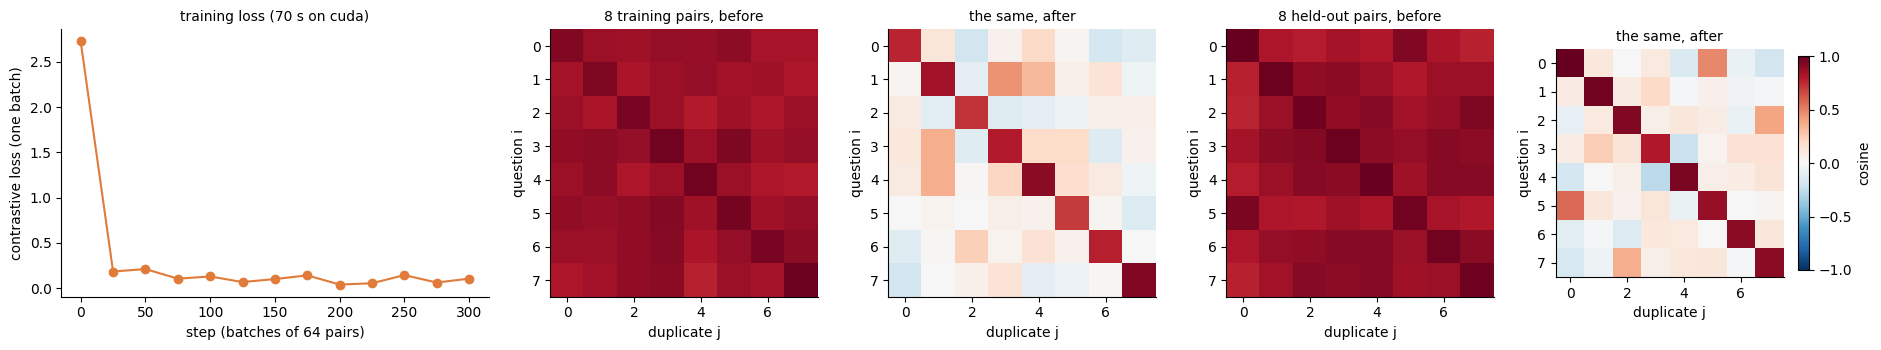

In [33]:
if TRAIN_FT:
    torch.manual_seed(SEED)
    ours = AutoModel.from_pretrained(RAW_NAME, revision=REVISIONS[RAW_NAME]).to(device)
    loss_history, train_time, pairs_seen, n_steps = train_contrastive(ours, train_pairs, **FT_CONFIG)
    encode_ours = lambda texts: encode_raw(texts, model=ours, max_len=FT_CONFIG["max_len"])
    after_row, Q_ours, D_ours = retrieval_metrics(encode_ours, f"our MiniLM, {FT_CONFIG['epochs']} epoch(s) on 20k Quora pairs")
    after = {"batch_matrix": batch_matrix(encode_ours, demo).tolist(), "heldout_matrix": batch_matrix(encode_ours, heldout).tolist(),
             "sts": sts_spearman(encode_ours), "retrieval": after_row,
             "random_cosines": (encode_ours(rand.question1.tolist()) * encode_ours(rand.question2.tolist())).sum(1).tolist()}
    record = {"before": before, "after": after, "loss": loss_history, "train_time": train_time, "device": str(device),
              "pairs": len(train_pairs), "pairs_seen": pairs_seen, "steps": n_steps}
    save_npz(FT_EMB, ft_meta, queries=Q_ours.astype(np.float16), corpus=D_ours.astype(np.float16))
    save_json(FT_JSON, ft_meta, record)
else:
    ours = None                                   # no GPU (or valid results exist): use the stored results of this very code
    record = load_checked(FT_JSON, ft_meta)
    z = load_checked(FT_EMB, ft_meta)
    Q_ours, D_ours = z["queries"].astype(np.float32), z["corpus"].astype(np.float32)
    before, after, loss_history = record["before"], record["after"], record["loss"]
    print(f"loaded the results of a training run on {record['device']}: {record['pairs_seen']} pairs seen in {record['steps']} steps, {record['train_time']:.0f} s")

fig, axes = plt.subplots(1, 5, figsize=(19, 3.6), gridspec_kw={"width_ratios": [1.5, 1, 1, 1, 1]})
axes[0].plot(*zip(*loss_history), "o-", color=C_HEAD)
axes[0].set_xlabel(f"step (batches of {FT_CONFIG['batch_size']} pairs)")
axes[0].set_ylabel("contrastive loss (one batch)")
axes[0].set_title(f"training loss ({record['train_time']:.0f} s on {record['device']})", fontsize=10)
for ax, (title, M_) in zip(axes[1:], [("8 training pairs, before", before["batch_matrix"]), ("the same, after", after["batch_matrix"]),
                                      ("8 held-out pairs, before", before["heldout_matrix"]), ("the same, after", after["heldout_matrix"])]):
    im = ax.imshow(M_, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("duplicate j")
    ax.set_ylabel("question i")
plt.colorbar(im, ax=axes[4], shrink=0.8, label="cosine")
plt.tight_layout()

### The effect

Three yardsticks before and after: the cosines of random pairs (anisotropy), STS-B, and the Quora benchmark. For
comparison the rows of the two pretrained models and of TF-IDF, the keyword method that has an STS-B number too. The
matrices above are a picture of a few pairs; the table is the measurement.

,STS-B Spearman x 100,recall@1,recall@5,recall@10,recall@100,hit@1,MRR@10,nDCG@10,MAP@10
retriever,,,,,,,,,
"raw MiniLM, mean pooling",51.1,0.697,0.846,0.888,0.961,0.778,0.824,0.827,0.798
"our MiniLM, 1 epoch(s) on 20k Quora pairs",71.1,0.864,0.987,0.993,1.000,0.965,0.977,0.977,0.969
TF-IDF,69.9,0.829,0.970,0.984,0.997,0.922,0.949,0.952,0.937
dense: all-MiniLM-L6-v2,82.0,0.884,0.996,1.000,1.000,0.986,0.992,0.993,0.990
dense: bge-small-en-v1.5,85.9,0.891,0.999,1.000,1.000,0.994,0.997,0.997,0.995


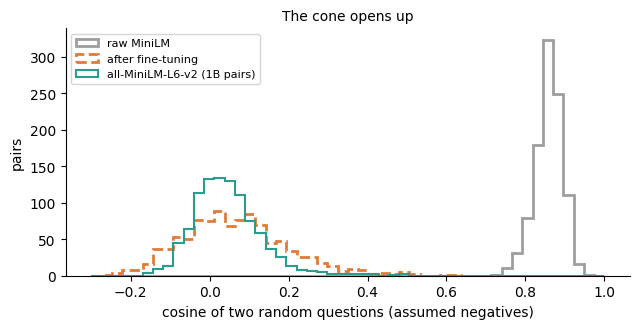

In [34]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(before["random_cosines"], bins=50, range=(-0.3, 1), histtype="step", lw=2, color=C_IN, label="raw MiniLM")
ax.hist(after["random_cosines"], bins=50, range=(-0.3, 1), histtype="step", lw=2, color=C_HEAD, ls="--", label="after fine-tuning")
ax.hist(cosines["all-MiniLM-L6-v2"]["random"], bins=50, range=(-0.3, 1), histtype="step", lw=1.5, color=C_EMB, label="all-MiniLM-L6-v2 (1B pairs)")
ax.set_xlabel("cosine of two random questions (assumed negatives)")
ax.set_ylabel("pairs")
ax.legend(fontsize=8)
ax.set_title("The cone opens up", fontsize=10)
plt.tight_layout()

summary = pd.DataFrame([before["retrieval"], after["retrieval"]] + [r for r in results if r["retriever"] in ("TF-IDF", "dense: all-MiniLM-L6-v2", "dense: bge-small-en-v1.5")]).set_index("retriever")
summary.insert(0, "STS-B Spearman x 100", np.round([before["sts"] * 100, after["sts"] * 100, sts_rows["TF-IDF (bag of words)"] * 100,
                                                    sts_rows["all-MiniLM-L6-v2"] * 100, sts_rows["bge-small-en-v1.5"] * 100], 1))
summary.round(3)

A few hundred gradient steps on 20 000 pairs move the raw model from about 51 to about 71 on STS-B (the level of the
word-count baseline) and from a mediocre to a strong retriever on the Quora benchmark, within a few points of the
pretrained models (see the table for the exact numbers of this run). Contrastive training also opened the cone
(histogram), although it is not a guaranteed cure for anisotropy in general. The remaining gap on STS-B (71 against
82 and 86) has many possible causes that this experiment does not separate: the amount and variety of training pairs
(our model has only seen questions), the data mix, the training schedule, the negatives, and for bge-small also the
architecture. Note that our model has an advantage on this benchmark: it was trained on *Quora questions* (in-domain
data), though never on the benchmark questions themselves. That is legitimate and it is exactly what you will do for
your project: a few thousand pairs from your own domain.

### Head-only vs. full fine-tuning *(optional)*

How much of this needs the whole backbone? The regimes:

| regime | backbone | projection head |
|---|---|---|
| raw baseline | frozen | none |
| head-only, linear | frozen | trainable |
| head-only, MLP | frozen | trainable (not run here) |
| full fine-tuning | trainable | none (above) |
| full fine-tuning + head | trainable | trainable (not run here) |

First a check of the claim *frozen means no gradient*: one batch through the frozen raw backbone and a trainable
linear head.

In [35]:
probe_head = nn.Linear(384, 384, bias=False).to(device)
raw_model.requires_grad_(False)
xq = raw_tok(demo.question1.tolist(), padding=True, return_tensors="pt").to(device)
xd = raw_tok(demo.question2.tolist(), padding=True, return_tensors="pt").to(device)
q = F.normalize(probe_head(pool(xq, raw_model(**xq).last_hidden_state, normalize=False)), dim=-1)
d = F.normalize(probe_head(pool(xd, raw_model(**xd).last_hidden_state, normalize=False)), dim=-1)
contrastive_loss(q, d).backward()
n_with_grad = sum(p.grad is not None for p in raw_model.parameters())
print(f"head: gradient norm {probe_head.weight.grad.norm().item():.3f}; backbone tensors with a gradient: {n_with_grad} of {len(list(raw_model.parameters()))}")
assert probe_head.weight.grad is not None and n_with_grad == 0
raw_model.requires_grad_(True)
del probe_head, q, d

head: gradient norm 2.809; backbone tensors with a gradient: 0 of 103


The experiment: the frozen raw MiniLM gives mean-pooled, **unnormalised** 384-dimensional features of all texts, computed
once without gradients; a linear head without bias is trained on top with the same loss, the same 20 000 pairs, one
epoch, batches of 64, and is evaluated on the same STS-B and Quora inputs with normalised outputs. The 384 → 384 head
starts at the identity (i.e. at the raw baseline); a 384 → 128 head, started at the first 128 coordinates, is a
separate *compression* variant and should not be compared one-to-one with the others. The learning rate of the head
(1e-3) differs from full fine-tuning (5e-5), as is usual for a few parameters trained from scratch; it was fixed in
advance, not tuned on the benchmark. **Before running:** how much of the gain of full fine-tuning will the head
recover?

In [36]:
def train_head(head, U1, U2, epochs=1, batch_size=64, lr=1e-3, log_every=50):
    optimizer = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=0.0)
    rng = np.random.default_rng(SEED)
    history, step, t0 = [], 0, time.time()
    for epoch in range(epochs):
        order = rng.permutation(len(U1))
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            if len(idx) < 2:
                continue
            loss = contrastive_loss(F.normalize(head(U1[idx].to(device)), dim=-1), F.normalize(head(U2[idx].to(device)), dim=-1))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if step % log_every == 0:
                history.append((step, loss.item()))
            step += 1
    return history, time.time() - t0


HEAD_CONFIG = dict(epochs=1, batch_size=64, lr=1e-3, max_len=64, dims=[384, 128])
HEAD_JSON = OUT_DIR / "head_only_minilm.json"
head_meta = dict(ft_meta, features="frozen raw MiniLM, mean pooling, not normalised", head="linear, no bias, eye init", **HEAD_CONFIG)
if TRAIN and (RETRAIN or not cache_is_valid(HEAD_JSON, head_meta)):
    feat = lambda texts: torch.from_numpy(encode_raw(list(texts), normalize=False, max_len=HEAD_CONFIG["max_len"]))
    t0 = time.time()
    U1, U2 = feat(train_pairs.question1), feat(train_pairs.question2)
    UQ, UD, US1, US2 = feat(queries.text), feat(corpus.text), feat(stsb.sentence1), feat(stsb.sentence2)
    t_feat = time.time() - t0
    head_rows, head_hist = [], {}
    for k_out in HEAD_CONFIG["dims"]:
        torch.manual_seed(SEED)
        head = nn.Linear(384, k_out, bias=False).to(device)
        nn.init.eye_(head.weight)                    # identity (384) or the first k coordinates (128)
        hist, t_head = train_head(head, U1, U2, **{k: HEAD_CONFIG[k] for k in ("epochs", "batch_size", "lr")})
        head_hist[str(k_out)] = hist
        with torch.no_grad():
            proj = lambda U: F.normalize(head(U.to(device)), dim=-1).cpu().numpy()
            row, _ = evaluate(proj(UQ) @ proj(UD).T, f"head-only: frozen raw MiniLM + linear 384 -> {k_out}")
            row["STS-B Spearman x 100"] = 100 * stats.spearmanr((proj(US1) * proj(US2)).sum(1), stsb.score).statistic
        row["train time (s)"] = t_head
        head_rows.append(row)
    save_json(HEAD_JSON, head_meta, {"rows": head_rows, "history": head_hist, "feature_time": t_feat, "device": str(device)})
    print(f"features of {2 * len(train_pairs) + len(queries) + len(corpus) + 2 * len(stsb):,} texts: {t_feat:.0f} s; "
          "head training: " + ", ".join(f"{r['train time (s)']:.1f} s" for r in head_rows))
head_rec = load_checked(HEAD_JSON, head_meta)

cmp_rows = [dict(before["retrieval"], **{"STS-B Spearman x 100": before["sts"] * 100})] + \
           [{k: v for k, v in r.items() if k != "train time (s)"} for r in head_rec["rows"]] + \
           [dict(after["retrieval"], **{"STS-B Spearman x 100": after["sts"] * 100})]
head_table = pd.DataFrame(cmp_rows).set_index("retriever")
head_table.insert(0, "STS-B Spearman x 100", head_table.pop("STS-B Spearman x 100"))
head_table[["STS-B Spearman x 100", "recall@1", "recall@10", "hit@1", "MRR@10", "nDCG@10"]].round(3)

features of 53,758 texts: 47 s; head training: 3.5 s, 0.8 s


,STS-B Spearman x 100,recall@1,recall@10,hit@1,MRR@10,nDCG@10
retriever,,,,,,
"raw MiniLM, mean pooling",51.079,0.697,0.888,0.778,0.824,0.827
head-only: frozen raw MiniLM + linear 384 -> 384,62.349,0.815,0.980,0.911,0.939,0.942
head-only: frozen raw MiniLM + linear 384 -> 128,59.662,0.798,0.970,0.892,0.925,0.928
"our MiniLM, 1 epoch(s) on 20k Quora pairs",71.082,0.864,0.993,0.965,0.977,0.977


Read the table row by row against the raw baseline. In this run the linear 384 → 384 head recovers a large part of
the gain on the Quora benchmark (hit@1 from 0.78 to about 0.91, against 0.97 for full fine-tuning) and a smaller part
on STS-B (from 51 to about 62, against 71), and it trains in about a second once the features exist. A linear head on
frozen features can re-weight and rotate the 384 directions the raw pooling provides, but it cannot change how the
backbone mixes the tokens; full fine-tuning can. The 128-dimensional head loses only a little more on this benchmark.
Whatever the head recovers here is a result for this model, these pairs and this one training recipe (one learning
rate, one epoch, one seed); a head is not a guaranteed improvement, and an MLP head or a head on top of a fine-tuned
backbone (not run) could behave differently. Variation between runs (seeds) is not measured here.

### Clean versus contaminated evaluation *(optional)*

What would **not** be legitimate: training on the test pairs. The next cell trains a fresh raw MiniLM on *nothing but*
the 1 275 pairs (benchmark query, its duplicate in the corpus), five passes, about a hundred steps. **Before
running:** can a model that has seen only 1 275 pairs beat the one trained on 20 000?

In [37]:
CONT_JSON = OUT_DIR / "finetune_contaminated.json"
cont_meta = dict(ft_meta, train_pairs="the 1 275 benchmark (query, relevant) pairs", epochs=5)
if TRAIN and (RETRAIN or not cache_is_valid(CONT_JSON, cont_meta)):
    leak = pd.DataFrame([(queries.text[q], corpus.text[d]) for q, rel in enumerate(relevant) for d in rel], columns=["question1", "question2"])
    torch.manual_seed(SEED)
    contaminated = AutoModel.from_pretrained(RAW_NAME, revision=REVISIONS[RAW_NAME]).to(device)
    _, t_cont, _, _ = train_contrastive(contaminated, leak, **dict(FT_CONFIG, epochs=5), log_every=None)
    enc_cont = lambda texts: encode_raw(texts, model=contaminated, max_len=FT_CONFIG["max_len"])
    row_cont, _, _ = retrieval_metrics(enc_cont, "raw MiniLM trained on the 1 275 test pairs only")
    row_cont["STS-B Spearman x 100"] = sts_spearman(enc_cont) * 100
    save_json(CONT_JSON, cont_meta, {"retrieval": row_cont, "n_leak": len(leak), "train_time": t_cont})
    del contaminated
cont = load_checked(CONT_JSON, cont_meta)
cont_table = pd.DataFrame([dict(after["retrieval"], **{"STS-B Spearman x 100": after["sts"] * 100}), cont["retrieval"]]).set_index("retriever")
cont_table[["STS-B Spearman x 100", "recall@1", "recall@10", "hit@1", "MRR@10", "nDCG@10"]].round(3)

,STS-B Spearman x 100,recall@1,recall@10,hit@1,MRR@10,nDCG@10
retriever,,,,,,
"our MiniLM, 1 epoch(s) on 20k Quora pairs",71.082,0.864,0.993,0.965,0.977,0.977
raw MiniLM trained on the 1 275 test pairs only,68.074,0.879,1.000,0.982,0.989,0.991


Compare the two rows. Training on the test pairs makes the benchmark numbers of a small, briefly trained model look
competitive with (or better than) a model trained on fifteen times more clean data, while on STS-B, which neither of
them was trained on, the contaminated model is not better. Once a model has been trained on the test pairs, its test
score is no longer an independent estimate of how it generalises; the experiment does not prove that *all* of its
score is memory, only that we can no longer tell. This is the leakage of Lecture 03 in a new disguise, and it is why
published scores of embedding models deserve care: the training data of `all-MiniLM-L6-v2` lists about 100 000 Quora
duplicate triplets, and the English fine-tuning data listed for the bge v1.5 models includes Quora as well, so their
rows in section 3 are partly in-domain or even partly a memory test (the exact overlap with our 1 000 queries is
unknown). Such contamination is a risk to check, not a proven overlap. The current English MTEB (v2, 41 tasks) dropped
the Quora retrieval task, and the MTEB leaderboard reports for every model how much of the benchmark is *zero-shot*,
i.e. without training data from those tasks, as far as the model's authors disclose it.

When you evaluate a model for your project, evaluate it on pairs it has never seen, and when you fine-tune, keep the
test pairs out of the training set. **Your turn** (GPU): change `FT_CONFIG` (learning rate, batch size, epochs) and
run the training cells again (the changed configuration triggers retraining). Treat this as *exploration*: if you keep
choosing settings by their benchmark score, the benchmark becomes a validation set and you need a fresh test set (or a
held-out validation split of the training pairs) for an honest final number.

### Beyond one vector: late interaction and index size *(optional)*

Everything so far compressed a text into **one** vector. Retrieval over document *pages* (PDFs with tables, figures,
layout) increasingly keeps **many** vectors per page. A vision-language model (VLM) for this typically has a vision
transformer that turns image patches into vectors, a connector (merger) that maps them into the space of a language
model, and a causal language backbone that reads patch tokens and text tokens together. The vision encoder, the
multimodal backbone and an optional output **projection head** for retrieval are three different parts; details differ
between models (and are not published for proprietary chat models). The output vectors of such a model are contextual
multimodal tokens, not necessarily one original image patch each.

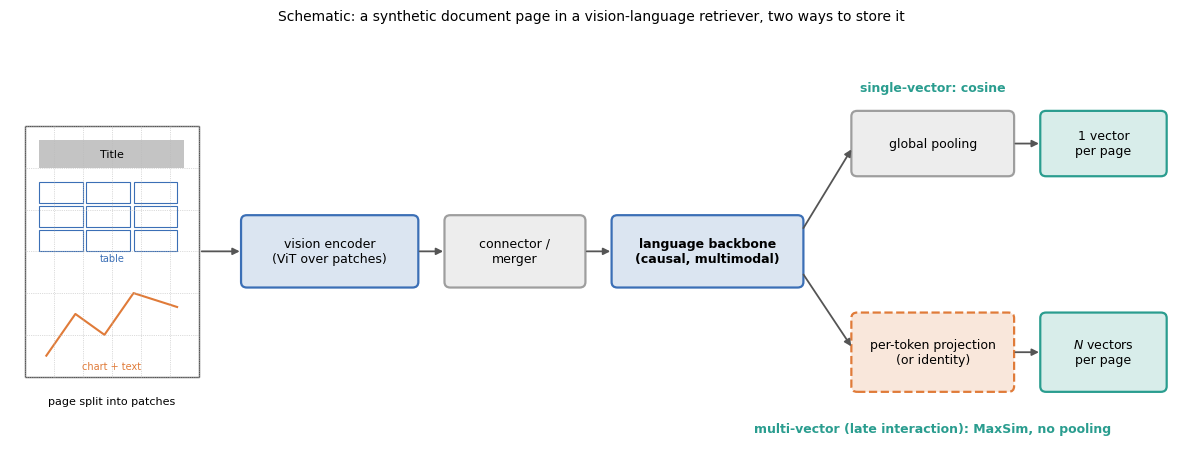

In [38]:
fig, ax = canvas(16, 6.2, (15, 5.6))
ax.add_patch(patches.Rectangle((0.2, 1.2), 2.4, 3.6, fc="white", ec="#555555"))
ax.add_patch(patches.Rectangle((0.4, 4.2), 2.0, 0.4, fc=C_IN, alpha=0.6))
ax.text(1.4, 4.4, "Title", ha="center", va="center", fontsize=8)
for r in range(3):
    for c in range(3):
        ax.add_patch(patches.Rectangle((0.4 + 0.65 * c, 3.0 + 0.35 * r), 0.6, 0.3, fc="white", ec=C_BACK, lw=0.8))
ax.text(1.4, 2.85, "table", ha="center", fontsize=7, color=C_BACK)
ax.plot([0.5, 0.9, 1.3, 1.7, 2.3], [1.5, 2.1, 1.8, 2.4, 2.2], color=C_HEAD, lw=1.5)
ax.text(1.4, 1.3, "chart + text", ha="center", fontsize=7, color=C_HEAD)
for k in np.linspace(0.2, 2.6, 7):
    ax.plot([k, k], [1.2, 4.8], color="#bbbbbb", lw=0.5, ls=":")
for k in np.linspace(1.2, 4.8, 7):
    ax.plot([0.2, 2.6], [k, k], color="#bbbbbb", lw=0.5, ls=":")
ax.text(1.4, 0.8, "page split into patches", ha="center", fontsize=8)
box(ax, 3.2, 2.5, 2.4, 1.0, "vision encoder\n(ViT over patches)", C_BACK)
box(ax, 6.0, 2.5, 1.9, 1.0, "connector /\nmerger", C_IN)
box(ax, 8.3, 2.5, 2.6, 1.0, "language backbone\n(causal, multimodal)", C_BACK, weight="bold")
for x0, x1 in [(2.6, 3.2), (5.6, 6.0), (7.9, 8.3)]:
    arrow(ax, x0, 3.0, x1, 3.0)
box(ax, 11.6, 4.1, 2.2, 0.9, "global pooling", C_IN)
box(ax, 14.2, 4.1, 1.7, 0.9, "1 vector\nper page", C_EMB)
box(ax, 11.6, 1.0, 2.2, 1.1, "per-token projection\n(or identity)", C_HEAD, ls="--")
box(ax, 14.2, 1.0, 1.7, 1.1, "$N$ vectors\nper page", C_EMB)
arrow(ax, 10.9, 3.3, 11.6, 4.5)
arrow(ax, 10.9, 2.7, 11.6, 1.6)
arrow(ax, 13.8, 4.55, 14.2, 4.55)
arrow(ax, 13.8, 1.55, 14.2, 1.55)
ax.text(12.7, 5.3, "single-vector: cosine", fontsize=9, ha="center", color=C_EMB, weight="bold")
ax.text(12.7, 0.4, "multi-vector (late interaction): MaxSim, no pooling", fontsize=9, ha="center", color=C_EMB, weight="bold")
ax.set_title("Schematic: a synthetic document page in a vision-language retriever, two ways to store it", fontsize=10)
plt.show()

**MaxSim.** With unit vectors $q_1, \dots, q_{n_q}$ of the query tokens and $d_1, \dots, d_{n_d}$ of the page, the
late-interaction score (ColBERT, ColPali) is

$$s(Q, D) = \sum_{i=1}^{n_q} \max_{1 \le j \le n_d} q_i^\top d_j :$$

every query token looks for its best match anywhere on the page, and the matches are added (some models, such as the
multi-vector output of bge-m3, average instead of summing). Unlike the cosine of two pooled vectors, nothing is
averaged away before the comparison, different query tokens can match different places, and the score is not
symmetric in $Q$ and $D$. MaxSim is a *scoring function*, not an evaluation metric. The example below computes it from
the token vectors of `all-MiniLM-L6-v2`; that model was not trained for late interaction, so the numbers illustrate the
arithmetic only.

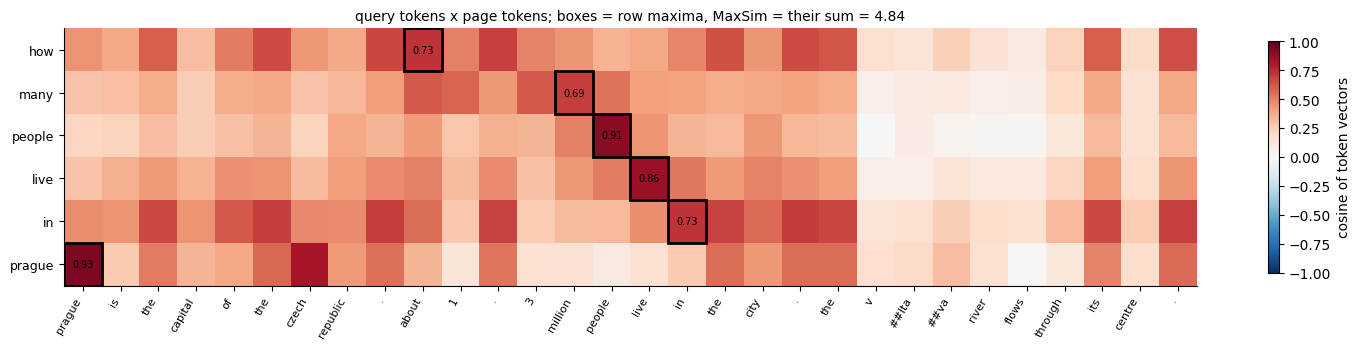

,relevant page,distractor page
MaxSim (sum over query tokens),4.838,2.431
MaxSim / query tokens,0.806,0.405
cosine of pooled vectors,0.764,0.427


In [39]:
def token_matrix(text):
    # unit-length token vectors of all-MiniLM-L6-v2 without [CLS] and [SEP], with the token strings
    T = st_minilm.encode([text], output_value="token_embeddings")[0][1:-1].float().cpu().numpy()
    toks_ = st_minilm.tokenizer.convert_ids_to_tokens(st_minilm.tokenizer(text).input_ids)[1:-1]
    return unit(T), toks_


def maxsim(Qt, Dt):
    return (Qt @ Dt.T).max(axis=1).sum()


assert np.isclose(maxsim(np.eye(2), np.eye(3)[:, :2]), 2.0)          # each query vector finds its exact match
q_text = "how many people live in prague"
pages = {"relevant page": "Prague is the capital of the Czech Republic. About 1.3 million people live in the city. The Vltava river flows through its centre.",
         "distractor page": "Brno is the second largest city of the Czech Republic and is known for its exhibition centre and its university."}
Qt, q_toks = token_matrix(q_text)
Dt, d_toks = token_matrix(pages["relevant page"])
M_ = Qt @ Dt.T
fig, ax = plt.subplots(figsize=(15, 3.6))
im = ax.imshow(M_, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i, j in enumerate(M_.argmax(1)):
    ax.add_patch(patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="black", lw=2))
    ax.text(j, i, f"{M_[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(d_toks)), d_toks, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(q_toks)), q_toks, fontsize=9)
plt.colorbar(im, ax=ax, label="cosine of token vectors", shrink=0.9)
ax.set_title(f"query tokens x page tokens; boxes = row maxima, MaxSim = their sum = {maxsim(Qt, Dt):.2f}", fontsize=10)
plt.tight_layout()
plt.show()
single = encoders["all-MiniLM-L6-v2"]([q_text] + list(pages.values()))
pd.DataFrame({name: {"MaxSim (sum over query tokens)": maxsim(Qt, token_matrix(t)[0]), "MaxSim / query tokens": maxsim(Qt, token_matrix(t)[0]) / len(q_toks),
                     "cosine of pooled vectors": single[0] @ single[1 + i]} for i, (name, t) in enumerate(pages.items())}).round(3)

Both scores put the relevant page first. What MaxSim adds is visible in the boxes: each query token found its own
partner on the page (*prague*, *people*, *live*), so the score can be explained token by token and a page that matches
only a part of the query is not averaged away. The numbers themselves are not comparable between the two scoring
functions (a sum over query tokens vs. one cosine), and a model trained for late interaction would produce sharper
token matches than these vectors of a model trained for pooled sentence embeddings.

**Index size has three axes.** For one page the raw payload is

$$V = N \cdot d \cdot b,$$

with $N$ vectors per page, $d$ coordinates per vector and $b$ bytes per coordinate (float32: 4 B, float16: 2 B, int8:
1 B, sign binarisation: 1/8 B with bit packing); metadata, index structures and scale factors come on top. Pooling or
token pruning reduces $N$, a projection head, PCA or truncation (MRL) reduces $d$, quantisation reduces $b$. For
storage the three factors multiply; the retrieval quality does not change independently along them, and a smaller
index is not automatically faster (that depends on the search implementation; MaxSim over all pages is exhaustive).
Units below: KiB = 1024 B, GB = $10^9$ B.

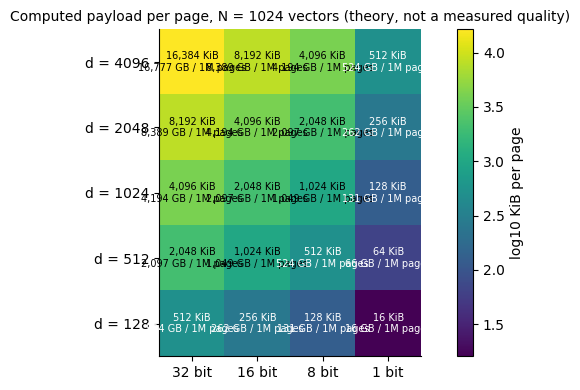

for comparison, one 384-d float32 vector per page: 1.5 KiB


In [40]:
N_PAGE = 1024                                  # e.g. 32 x 32 image patches per page
dims, bits = [4096, 2048, 1024, 512, 128], [32, 16, 8, 1]
kib = np.array([[N_PAGE * d * b / 8 / 1024 for b in bits] for d in dims])
fig, ax = plt.subplots(figsize=(7.5, 4))
im = ax.imshow(np.log10(kib), cmap="viridis")
for i in range(len(dims)):
    for j in range(len(bits)):
        ax.text(j, i, f"{kib[i, j]:,.0f} KiB\n{kib[i, j] * 1024 * 1e6 / 1e9:,.0f} GB / 1M pages", ha="center", va="center", fontsize=7,
                color="white" if np.log10(kib[i, j]) < np.log10(kib).mean() else "black")
ax.set_xticks(range(len(bits)), [f"{b} bit" for b in bits])
ax.set_yticks(range(len(dims)), [f"d = {d}" for d in dims])
ax.set_title(f"Computed payload per page, N = {N_PAGE} vectors (theory, not a measured quality)", fontsize=10)
plt.colorbar(im, ax=ax, label="log10 KiB per page")
plt.tight_layout()
plt.show()
print(f"for comparison, one 384-d float32 vector per page: {384 * 4 / 1024:.1f} KiB")

**A projection head is already a compression step.** In a head-less multi-vector model $z_i = h_i$ (then normalised);
in a projected one $z_i = W h_i$, for example 2048 → 128. Both can be trained for retrieval; *head-less* does not mean
*raw language model*. A narrow head has already removed directions of the backbone space, and that may use up part of
the redundancy that a post-hoc compression (PCA, binarisation) could otherwise exploit: the dimension alone does not tell
how robust an index is, it matters *which* directions remain and how they were trained. Sign binarisation, for
instance, depends on the coordinate basis (rotating the vectors changes which signs are kept), whereas dot products of
real vectors are invariant to rotations. Neither "projection heads hurt" nor "a higher dimension is always better" is
a general rule; trade-offs like these have to be measured on the target corpus, for quality *and* bytes per page.

## 5. Fine-tuning an encoder for classification

Transfer learning for text follows the three regimes of Lecture 04 (feature extraction, head only, full fine-tuning).
For a linear head, *head only* and *frozen features + logistic regression* are the same model, so regime (b) below
covers both, and (a) is the baseline without any pretrained model. The task is sentiment of **Czech film reviews**
from ČSFD (5 000 reviews with a star rating; 0–1 stars = negative, 4–5 stars = positive; 4 000 for training, 1 000
for the test, balanced; no review text occurs in both splits). The encoder is **RetroMAE-small-cs** by Seznam.cz
(Bednář et al., 2024): about 24M parameters, 256-dimensional vectors, pretrained on Czech web text with the RetroMAE
objective. In RetroMAE (Xiao et al., 2022) the encoder reads a lightly masked sentence and its `[CLS]` state is used by
a small decoder to reconstruct a heavily masked copy of the sentence: the `[CLS]` vector is *trained to carry the
content of the text*, but not for any notion of similarity. Its sibling `simcse-retromae-small-cs` is the same network
after unsupervised contrastive training (SimCSE) on Czech Wikipedia sentences, the Czech counterpart of the MiniLM pair
of section 2. Both use the `[CLS]` vector.

The three regimes do not differ only in what is trained; the protocol differs too:

| regime | what is trained | training reviews | input | representation | hyperparameter choice |
|---|---|---|---|---|---|
| (a) bag of words | TF-IDF + logistic regression | 4 000 | whole review | TF-IDF, L2-normalised rows | $C$ by 5-fold CV, TF-IDF refitted in every fold |
| (b) frozen encoder + linear head | logistic regression on `[CLS]` | 4 000 | first 256 tokens | `[CLS]`, normalised | $C$ by 5-fold CV |
| (c) full fine-tuning | all ~24M parameters + a new head, 4 epochs | 3 500 (+ 500 validation) | first 256 tokens | `[CLS]`, not normalised | epoch by validation accuracy |

So the main table is a practical comparison, not an isolated ablation of fine-tuning; an *(optional)* variant at the
end puts all regimes on the same 3 500 / 500 split. The test reviews are used once, at the end. **Before running:**
rank the four rows by test accuracy.

In [41]:
CS_RAW, CS_SIMCSE = "Seznam/retromae-small-cs", "Seznam/simcse-retromae-small-cs"
csfd = pd.read_csv(fetch("data/csfd_reviews.csv"))
cs_train, cs_test = csfd[csfd.split == "train"].reset_index(drop=True), csfd[csfd.split == "test"].reset_index(drop=True)
assert not set(cs_train.text) & set(cs_test.text)
print(f"{len(cs_train)} training and {len(cs_test)} test reviews (positive share {cs_train.label.mean():.2f} / {cs_test.label.mean():.2f}), "
      f"median length {csfd.text.str.len().median():.0f} characters")
display(cs_train.sample(3, random_state=SEED)[["rating", "label", "text"]])

cs_tok = AutoTokenizer.from_pretrained(CS_RAW, revision=REVISIONS[CS_RAW])
cs_raw = AutoModel.from_pretrained(CS_RAW, revision=REVISIONS[CS_RAW]).to(device).eval()
cs_simcse = AutoModel.from_pretrained(CS_SIMCSE, revision=REVISIONS[CS_SIMCSE]).to(device).eval()
print("tokens:", cs_tok.tokenize(cs_train.text[0])[:14])
cs_len = np.array([len(x) for x in cs_tok(csfd.text.tolist()).input_ids])
print(f"reviews longer than 256 tokens (cut in (b) and (c)): {(cs_len > 256).mean():.1%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
GRID = {"clf__C": [0.3, 1, 3, 10]}

# (a) bag of words (words and bigrams); TF-IDF is fitted inside every CV fold (Pipeline), so no fold sees the others' vocabulary
search_tfidf = GridSearchCV(Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2)),
                                      ("clf", LogisticRegression(max_iter=2000))]), GRID, cv=cv, scoring="accuracy", refit=True)
search_tfidf.fit(cs_train.text, cs_train.label)
test_probs = {"(a) TF-IDF + logistic regression": search_tfidf.predict_proba(cs_test.text)[:, 1]}
print(f"(a) {len(search_tfidf.best_estimator_['tfidf'].vocabulary_):,} features (refitted on all 4 000 reviews), "
      f"C = {search_tfidf.best_params_['clf__C']}, CV accuracy {search_tfidf.best_score_:.3f}")

# (b) frozen encoders: one encoding pass over the reviews (cut at 256 tokens, cached for the CPU path), then a linear model;
#     the features have no parameters fitted on the data, so cross-validation on them is clean
#     (the vectors are shared with the original notebook in outputs/ and verified by re-encoding a few reviews)
EMB_CS = OUT_DIR / "emb_csfd.npz"
cs_meta = {"models": {m: REVISIONS[m] for m in (CS_RAW, CS_SIMCSE)}, "train": text_hash(cs_train.text), "test": text_hash(cs_test.text),
           "pooling": "cls", "normalised": True, "max_len": 256, "dtype": "float16"}
cs_models = {"raw": cs_raw, "simcse": cs_simcse}
if TRAIN and RECOMPUTE_EMBEDDINGS:
    feats = {}
    for tag, model in cs_models.items():
        for split, df in [("train", cs_train), ("test", cs_test)]:
            feats[f"{tag}_{split}"] = encode_raw(df.text.tolist(), model, cs_tok, pooling="cls", batch_size=64, max_len=256).astype(np.float16)
    save_npz(EMB_CS, cs_meta, **feats)
z = load_checked(EMB_CS, cs_meta) if EMB_CS.exists() else np.load(fetch("outputs/emb_csfd.npz"))
feats = {k: z[k].astype(np.float32) for k in ("raw_train", "raw_test", "simcse_train", "simcse_test")}
assert all(len(feats[f"{t}_{s}"]) == len(df) for t in cs_models for s, df in [("train", cs_train), ("test", cs_test)])
cs_diff = max(spot_check(feats[f"{tag}_{split}"][:10], lambda t, m=model: encode_raw(t, m, cs_tok, pooling="cls", max_len=256), df.text[:10])
              for tag, model in cs_models.items() for split, df in [("train", cs_train), ("test", cs_test)])
print(f"frozen [CLS] features: re-encoding check on 2 x 20 reviews, max difference {cs_diff:.1e}")
lr_frozen = {}
for tag, label in [("raw", "(b) frozen raw RetroMAE [CLS] + logistic regression"), ("simcse", "(b) frozen SimCSE-RetroMAE [CLS] + logistic regression")]:
    lr_frozen[tag] = GridSearchCV(Pipeline([("clf", LogisticRegression(max_iter=2000))]), GRID, cv=cv, scoring="accuracy", refit=True)
    lr_frozen[tag].fit(feats[f"{tag}_train"], cs_train.label)
    test_probs[label] = lr_frozen[tag].predict_proba(feats[f"{tag}_test"])[:, 1]
    print(f"(b) {tag}: C = {lr_frozen[tag].best_params_['clf__C']}, CV accuracy {lr_frozen[tag].best_score_:.3f}")

4000 training and 1000 test reviews (positive share 0.50 / 0.50), median length 247 characters


,rating,label,text
555,4,1,Romantická tabulka příběhu ochucená špetkou hořkých událostí na pozadí sladkého nádechu pohádkovosti se zamilovanou ...
3491,5,1,"Za mě rozhodně slabší pětka. I když to vlastně vůbec není o veselých věcech, je ten film hrozná pohoda a zábava. Jas..."
527,0,0,"každé dvě minuty filmu, by byly slušným trailerem a možná by i přitáhly diváky, takhle pěkně jednotlivě... možná i j..."


tokens: ['čím', 'delší', 'dobu', 'film', 'běže', '##l', ',', 'tím', 'víc', 'jsem', 'si', 'říkala', ',', 'co']


reviews longer than 256 tokens (cut in (b) and (c)): 4.7%


(a) 29,176 features (refitted on all 4 000 reviews), C = 10, CV accuracy 0.855


frozen [CLS] features: re-encoding check on 2 x 20 reviews, max difference 2.4e-04


(b) raw: C = 10, CV accuracy 0.802


(b) simcse: C = 3, CV accuracy 0.802


### (c) Full fine-tuning

The classifier is the encoder plus one linear layer on the `[CLS]` vector; the loss is the binary cross-entropy of
Lecture 04. We keep 500 training reviews as a validation split for choosing the epoch by validation accuracy (the
learning rate and the input length were fixed when this notebook was prepared, also without looking at the test), and
touch the test reviews once at the end. The training numbers printed per epoch are averages over the batches *during*
the epoch, with dropout on and the weights still changing, so they are not exactly the accuracy of the model at the end
of the epoch; the validation numbers are (evaluation mode, after the epoch). A logit $\ge 0$, i.e. a probability
$\ge 0.5$, counts as positive everywhere.

epoch 1 | train loss 0.569 acc 0.698 (during the epoch) | val loss 0.425 acc 0.794 |   46 s


epoch 2 | train loss 0.358 acc 0.838 (during the epoch) | val loss 0.478 acc 0.818 |   94 s


epoch 3 | train loss 0.262 acc 0.890 (during the epoch) | val loss 0.434 acc 0.824 |  140 s


epoch 4 | train loss 0.210 acc 0.916 (during the epoch) | val loss 0.384 acc 0.858 |  184 s


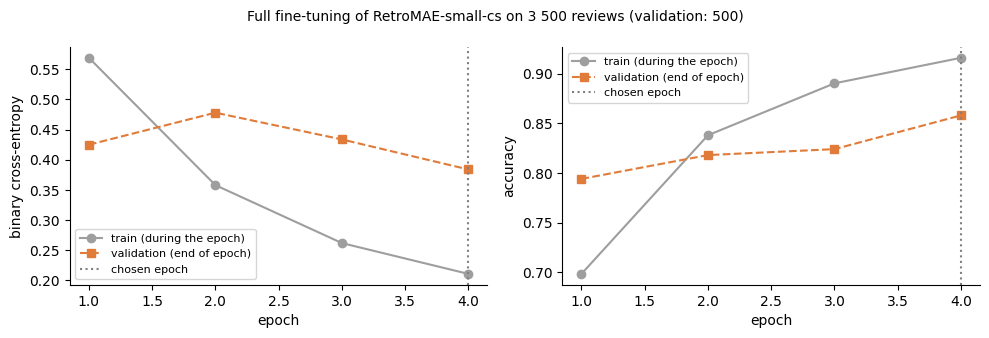

In [42]:
class ReviewClassifier(nn.Module):
    def __init__(self, name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(name, revision=REVISIONS[name])
        self.head = nn.Linear(self.encoder.config.hidden_size, 1)

    def forward(self, **batch):
        return self.head(self.encoder(**batch).last_hidden_state[:, 0]).squeeze(-1)      # one logit from the [CLS] vector


def run_epoch(model, texts, labels, optimizer=None, batch_size=32, max_len=256):
    training = optimizer is not None
    model.train(training)
    order = np.random.permutation(len(texts)) if training else np.arange(len(texts))
    total, correct, probs = 0.0, 0, np.zeros(len(texts))
    with torch.set_grad_enabled(training):
        for i in range(0, len(texts), batch_size):
            idx = order[i:i + batch_size]
            batch = cs_tok([texts[j] for j in idx], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
            y = torch.tensor(labels[idx], dtype=torch.float32, device=device)
            logits = model(**batch)
            loss = F.binary_cross_entropy_with_logits(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(idx)
            correct += ((logits >= 0) == (y > 0.5)).sum().item()          # logit >= 0  <=>  probability >= 0.5
            probs[idx] = torch.sigmoid(logits).detach().float().cpu().numpy()
    return total / len(texts), correct / len(texts), probs


fit_idx, val_idx = train_test_split(np.arange(len(cs_train)), test_size=500, stratify=cs_train.label, random_state=SEED)
CLS_CONFIG = dict(lr=5e-5, epochs=4, batch_size=32, max_len=256)
CLS_JSON = OUT_DIR / "classification_csfd.json"
cls_meta = {"model": CS_RAW, "revision": REVISIONS[CS_RAW], "train": text_hash(cs_train.text), "test": text_hash(cs_test.text),
            "validation": text_hash(cs_train.text.values[val_idx]), "selection": "best validation accuracy", "seed": SEED, **CLS_CONFIG}
if TRAIN and (RETRAIN or not cache_is_valid(CLS_JSON, cls_meta)):
    fit_text, val_text = cs_train.text.values[fit_idx].tolist(), cs_train.text.values[val_idx].tolist()
    fit_y, val_y = cs_train.label.values[fit_idx], cs_train.label.values[val_idx]
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    clf = ReviewClassifier(CS_RAW).to(device)
    optimizer = torch.optim.AdamW(clf.parameters(), lr=CLS_CONFIG["lr"], weight_decay=0.01)
    history, best, t0 = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}, (-1.0, None, 0), time.time()
    for epoch in range(1, CLS_CONFIG["epochs"] + 1):
        tr_loss, tr_acc, _ = run_epoch(clf, fit_text, fit_y, optimizer, CLS_CONFIG["batch_size"], CLS_CONFIG["max_len"])
        va_loss, va_acc, _ = run_epoch(clf, val_text, val_y, None, CLS_CONFIG["batch_size"], CLS_CONFIG["max_len"])
        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)
        if va_acc >= best[0]:                                  # keep the epoch with the best validation accuracy
            best = (va_acc, {k: v.detach().cpu().clone() for k, v in clf.state_dict().items()}, epoch)
        print(f"epoch {epoch} | train loss {tr_loss:.3f} acc {tr_acc:.3f} (during the epoch) | val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - t0:4.0f} s")
    clf.load_state_dict(best[1])
    _, _, p_test = run_epoch(clf, cs_test.text.tolist(), cs_test.label.values)
    save_json(CLS_JSON, cls_meta, {"history": history, "best_epoch": best[2], "test_probs": p_test.tolist(),
                                   "train_time": time.time() - t0, "device": str(device)})
else:
    clf = None
cls_record = load_checked(CLS_JSON, cls_meta)
if clf is None:
    print(f"loaded the results of a training run on {cls_record['device']}: best epoch {cls_record['best_epoch']}, {cls_record['train_time']:.0f} s")
test_probs["(c) full fine-tuning of RetroMAE"] = np.asarray(cls_record["test_probs"])

h = cls_record["history"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, key, label in zip(axes, ("loss", "acc"), ("binary cross-entropy", "accuracy")):
    ax.plot(range(1, len(h["train_loss"]) + 1), h[f"train_{key}"], "o-", color=C_IN, label="train (during the epoch)")
    ax.plot(range(1, len(h["train_loss"]) + 1), h[f"val_{key}"], "s--", color=C_HEAD, label="validation (end of epoch)")
    ax.axvline(cls_record["best_epoch"], color="grey", ls=":", lw=1.5, label="chosen epoch")
    ax.set_xlabel("epoch")
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
fig.suptitle("Full fine-tuning of RetroMAE-small-cs on 3 500 reviews (validation: 500)", fontsize=10)
plt.tight_layout()

The test results. Besides accuracy and ROC-AUC (the probability that a random positive review gets a higher score
than a random negative one, ties counting one half), the table reports the threshold metrics at 0.5: **precision**
(of the reviews called positive, how many are), **recall** (of the positive reviews, how many were found),
**specificity** (the same for the negative class), **F1** (harmonic mean of precision and recall), **balanced
accuracy** (mean of recall and specificity; equal to accuracy on balanced data), and **average precision** (AP, a
summary of the precision-recall curve; not in general equal to its trapezoidal area). For clustering, one would use yet
other measures (adjusted Rand index, normalised mutual information, silhouette). The per-review predictions of all
regimes are saved to `outputs_extended/csfd_test_predictions.csv`.

,accuracy,precision,recall,specificity,F1,balanced acc.,ROC-AUC,AP
regime,,,,,,,,
(a) TF-IDF + logistic regression,0.861,0.862,0.860,0.862,0.861,0.861,0.934,0.931
(b) frozen raw RetroMAE [CLS] + logistic regression,0.816,0.825,0.802,0.830,0.813,0.816,0.891,0.900
(b) frozen SimCSE-RetroMAE [CLS] + logistic regression,0.804,0.806,0.800,0.808,0.803,0.804,0.890,0.896
(c) full fine-tuning of RetroMAE,0.862,0.879,0.840,0.884,0.859,0.862,0.943,0.945


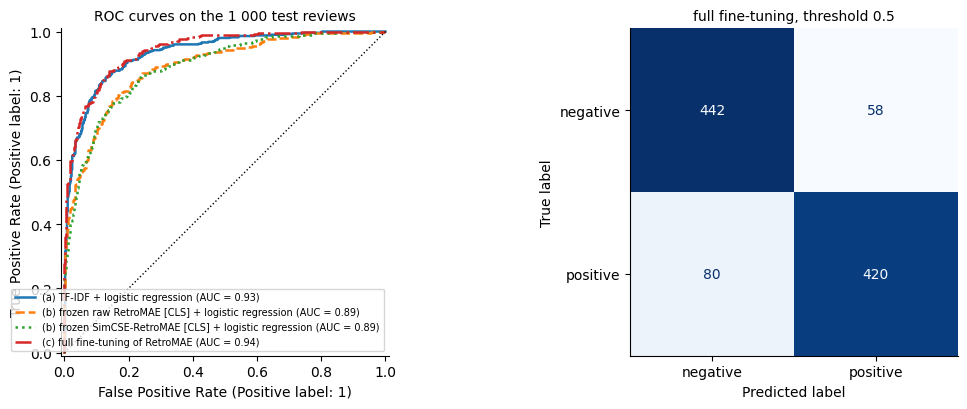

In [43]:
y_test = cs_test.label.values
rows = []
for name, p in test_probs.items():
    yhat = (p >= 0.5).astype(int)
    rows.append({"regime": name, "accuracy": accuracy_score(y_test, yhat), "precision": precision_score(y_test, yhat),
                 "recall": recall_score(y_test, yhat), "specificity": recall_score(y_test, yhat, pos_label=0), "F1": f1_score(y_test, yhat),
                 "balanced acc.": balanced_accuracy_score(y_test, yhat), "ROC-AUC": roc_auc_score(y_test, p), "AP": average_precision_score(y_test, p)})
pd.DataFrame({"label": y_test, **{name: p for name, p in test_probs.items()}}).to_csv(OUT_DIR / "csfd_test_predictions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for (name, p), ls in zip(test_probs.items(), ["-", "--", ":", "-."]):
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0], ls=ls, lw=1.8)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_title("ROC curves on the 1 000 test reviews", fontsize=10)
axes[0].legend(fontsize=7, loc="lower right")
ConfusionMatrixDisplay(confusion_matrix(y_test, test_probs["(c) full fine-tuning of RetroMAE"] >= 0.5),
                       display_labels=["negative", "positive"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("full fine-tuning, threshold 0.5", fontsize=10)
plt.tight_layout()
pd.DataFrame(rows).set_index("regime").round(3)

### How sure are we about the ranking? *(optional)*

On 1 000 test reviews one correct prediction is 0.1 percentage points, and the standard error of an accuracy around
0.85 is about 1.1 points. Because all regimes are evaluated on the *same* reviews, the right tools are **paired**:
McNemar's test looks only at the reviews where exactly one of two classifiers is right ($n_{01}$, $n_{10}$; exact
binomial test when these counts are small), and a paired bootstrap resamples the test reviews and recomputes the
difference of two metrics on each resample. Both quantify the uncertainty *for these fitted models and this test
sample*; how much a difference changes when the fine-tuning is repeated with other seeds would require repeated
training runs, which we did not do.

In [44]:
ref = "(a) TF-IDF + logistic regression"
rng_b = np.random.default_rng(SEED)
B_BOOT = 2000
boot = rng_b.integers(0, len(y_test), (B_BOOT, len(y_test)))
correct = {name: ((p >= 0.5).astype(int) == y_test) for name, p in test_probs.items()}
stat_rows = []
for name, p in test_probs.items():
    if name == ref:
        continue
    n01 = int((correct[ref] & ~correct[name]).sum())           # only the baseline is right
    n10 = int((~correct[ref] & correct[name]).sum())           # only this regime is right
    d_acc = correct[name][boot].mean(1) - correct[ref][boot].mean(1)
    d_auc = np.array([roc_auc_score(y_test[b], p[b]) - roc_auc_score(y_test[b], test_probs[ref][b]) for b in boot[:1000]])
    stat_rows.append({"regime vs. (a)": name, "accuracy difference": correct[name].mean() - correct[ref].mean(),
                      "95% CI (bootstrap)": f"[{np.percentile(d_acc, 2.5):+.3f}, {np.percentile(d_acc, 97.5):+.3f}]",
                      "only (a) right": n01, "only this right": n10, "McNemar exact p": stats.binomtest(n01, n01 + n10, 0.5).pvalue,
                      "ROC-AUC difference": roc_auc_score(y_test, p) - roc_auc_score(y_test, test_probs[ref]),
                      "95% CI (bootstrap, 1 000)": f"[{np.percentile(d_auc, 2.5):+.3f}, {np.percentile(d_auc, 97.5):+.3f}]"})
pd.DataFrame(stat_rows).set_index("regime vs. (a)").round(3)

,accuracy difference,95% CI (bootstrap),only (a) right,only this right,McNemar exact p,ROC-AUC difference,"95% CI (bootstrap, 1 000)"
regime vs. (a),,,,,,,
(b) frozen raw RetroMAE [CLS] + logistic regression,-0.045,"[-0.072, -0.019]",113,68,0.001,-0.043,"[-0.064, -0.025]"
(b) frozen SimCSE-RetroMAE [CLS] + logistic regression,-0.057,"[-0.083, -0.030]",121,64,0.000,-0.043,"[-0.064, -0.025]"
(c) full fine-tuning of RetroMAE,0.001,"[-0.022, +0.023]",63,64,1.000,0.009,"[-0.005, +0.021]"


### The same split for all regimes *(optional)*

A controlled variant of the comparison: regimes (a) and (b) are trained on exactly the 3 500 reviews that (c) was
trained on, and their regularisation $C$ is chosen on the same 500 validation reviews that chose the epoch of (c). The
remaining differences (whole review vs. 256 tokens for (a), normalised vs. unnormalised representation) are listed in
the table at the start of this section.

In [45]:
fold = np.full(len(cs_train), -1)
fold[val_idx] = 0                                      # -1: always in training, 0: the validation fold
ps = PredefinedSplit(fold)
ctrl = {}
for name, pipe, X_tr, X_te in [("(a) TF-IDF + logistic regression", search_tfidf.estimator, cs_train.text.values, cs_test.text.values),
                               ("(b) frozen raw RetroMAE [CLS] + logistic regression", lr_frozen["raw"].estimator, feats["raw_train"], feats["raw_test"]),
                               ("(b) frozen SimCSE-RetroMAE [CLS] + logistic regression", lr_frozen["simcse"].estimator, feats["simcse_train"], feats["simcse_test"])]:
    gs = GridSearchCV(pipe, GRID, cv=ps, scoring="accuracy", refit=False).fit(X_tr, cs_train.label.values)
    final = sklearn.base.clone(pipe).set_params(**gs.best_params_).fit(X_tr[fit_idx], cs_train.label.values[fit_idx])   # fit split only
    p = final.predict_proba(X_te)[:, 1]
    ctrl[name] = {"C (chosen on validation)": gs.best_params_["clf__C"], "validation accuracy": gs.best_score_,
                  "test accuracy": accuracy_score(y_test, p >= 0.5), "test ROC-AUC": roc_auc_score(y_test, p)}
p_c = test_probs["(c) full fine-tuning of RetroMAE"]
ctrl["(c) full fine-tuning of RetroMAE"] = {"C (chosen on validation)": np.nan, "validation accuracy": max(cls_record["history"]["val_acc"]),
                                            "test accuracy": accuracy_score(y_test, p_c >= 0.5), "test ROC-AUC": roc_auc_score(y_test, p_c)}
pd.DataFrame(ctrl).T.round(3)

,C (chosen on validation),validation accuracy,test accuracy,test ROC-AUC
(a) TF-IDF + logistic regression,10.0,0.840,0.856,0.931
(b) frozen raw RetroMAE [CLS] + logistic regression,3.0,0.802,0.812,0.891
(b) frozen SimCSE-RetroMAE [CLS] + logistic regression,10.0,0.810,0.807,0.892
(c) full fine-tuning of RetroMAE,NaN,0.858,0.862,0.943


How to read the tables of this section (the exact numbers are in the outputs above):

- The **bag of words is a very strong baseline** for sentiment: polarity is carried by specific words and bigrams
  (*skvělý*, *nuda*, *ztráta času*), which TF-IDF sees directly in the whole review, and a few thousand examples are
  plenty for a linear model on them.
- The **frozen `[CLS]` vectors** score clearly lower in a linear probe, the contrastive one included. This shows that
  the polarity is not *linearly* easy to read from these 256 numbers, not that it is absent: a vector trained for
  reconstruction (RetroMAE) or for similarity of Wikipedia sentences (SimCSE) organises its directions for that job, and
  a linear model sees only what is linearly separable.
- **Full fine-tuning** adapts the whole encoder to the task and lands at the level of the bag of words: in the run
  shown here the two differ by a few test reviews, the numbers of reviews that only one of them gets right are
  almost equal (McNemar $p$ far from any significance level), and the bootstrap intervals of the differences include
  zero. Repeated runs of the same code have ended a point above or below the baseline (GPU arithmetic is not exactly
  reproducible): a difference of a few test reviews is not a finding. The frozen regimes are worse than the baseline by
  about five points, and that difference is clear on this test set.

The practical order is the one of Lecture 04: baseline first (seconds), frozen features second (seconds, and the better
choice on tasks about *meaning*: intent, topic, paraphrase), full fine-tuning when labels are plentiful and the gain is
measured on held-out data, ideally over several seeds. The scores printed below are model probabilities, not
calibrated ones.

**Your turn:** classify your own Czech sentence. The first example is a mixed review that ends negatively; in our
runs both models called it positive, apparently swayed by the praise at the start: a useful hard case. The
fine-tuned model is available only when it was trained in this session (with a GPU); its weights are not stored in the
repository, so the CPU path shows the frozen model only. With a GPU, `RETRAIN = True` in the setup cell or a change of
`CLS_CONFIG` trains the classifier again.

In [46]:
@torch.no_grad()
def sentiment(text):
    e = encode_raw([text], cs_simcse, cs_tok, pooling="cls", max_len=256)
    p_frozen = lr_frozen["simcse"].predict_proba(e)[0, 1]
    line = f"{text!r}\n   frozen SimCSE + logistic regression: P(positive) = {p_frozen:.2f}"
    if clf is not None:
        clf.eval()
        batch = cs_tok([text], return_tensors="pt", truncation=True, max_length=256).to(device)
        line += f"\n   fine-tuned RetroMAE:                 P(positive) = {torch.sigmoid(clf(**batch)).item():.2f}"
    else:
        line += "\n   fine-tuned RetroMAE: not available (results were loaded from outputs_extended/, the model was not trained in this session)"
    print(line)


sentiment("Herecké výkony byly skvělé, ale scénář nedával smysl a konec mě zklamal.")
sentiment("Nejlepší film, jaký jsem letos viděl.")

'Herecké výkony byly skvělé, ale scénář nedával smysl a konec mě zklamal.'
   frozen SimCSE + logistic regression: P(positive) = 0.89
   fine-tuned RetroMAE:                 P(positive) = 0.74
'Nejlepší film, jaký jsem letos viděl.'
   frozen SimCSE + logistic regression: P(positive) = 0.92
   fine-tuned RetroMAE:                 P(positive) = 0.94


## 6. Checklist for your project, FAQ and what comes next

**Choosing an embedding model**
- Prefer a model explicitly trained for your kind of similarity (section 4); the pooled hidden states of a plain
  language model are a baseline, not a solution.
- Read the model card: backbone, training objective and data, languages, maximum input length, pooling, head,
  normalisation, query/document instructions or prefixes, output dimension(s), similarity function, licence.
- A longer context window does not guarantee better passage retrieval. Choose the unit you index (sentence, chunk,
  page, document) for the task and validate it.
- Distinguish symmetric similarity, asymmetric retrieval and downstream usefulness. Test on representative held-out
  data from your task, including hard cases (near-duplicates that differ in a number, a condition, an exception).
- Leaderboards (e.g. [MTEB](https://huggingface.co/spaces/mteb/leaderboard), with its *zero-shot* information) are a
  starting point for a shortlist, not an answer; licences differ (some strong models are non-commercial or gated).

**Fine-tuning and evaluation**
- Prevent split leakage; compare frozen/head-only and full fine-tuning on validation data, not on a single test run.
  Training on test examples invalidates an independent estimate of generalisation.
- Thresholds are specific to a model, a task and a data distribution; a cosine is not a calibrated probability.
- For RAG, evaluate the recall and ranking of known relevant chunks (recall@k, nDCG@k at the $k$ you put in the
  prompt); where an answer needs several pieces of evidence, check *sufficiency* separately. For multi-vector indexes,
  look at bytes per page together with quality.
- For classification: TF-IDF and frozen embeddings + logistic regression first; fine-tune the whole encoder when labels
  are plentiful, and report paired uncertainty when differences are small.

**FAQ** (each answer points to where it is explained)
- *Is an encoder the same as an embedding model?* No: encoder/decoder is the architecture, embedding model is a role
  that needs embedding-specific training (sections 1, 2, 4).
- *Why can `[CLS]` or the last token stand for a whole sentence?* Because, in the right attention mask, its state has
  attended to all tokens; selecting it has no parameters, training makes it useful (section 2, pooling).
- *Is contrastive learning applied when I compute embeddings?* No, it is a training objective; a finished model runs a
  plain forward pass (section 2, projection heads; section 4).
- *What is the difference between a projection head and the LM head?* The projection head maps into the embedding
  space; the LM head maps every token state to vocabulary logits (sections 1 and 2).
- *Does a 32k-token context mean a long document is embedded well?* No: the vector has a fixed size, and one relevant
  paragraph becomes a small part of what is pooled (section 2, long texts).
- *Is cosine an evaluation metric?* No, it is a scoring function; recall@k, MRR, nDCG and Spearman evaluate scores
  against labels (section 3).
- *What does MaxSim do that a single cosine cannot?* Every query token finds its own best match in the document, no
  pooling happens before the comparison (section 4, optional part).
- *Why does binarisation save 32× over float32 and what does it cost?* One bit instead of 32 per coordinate; the cost in
  quality depends on the model and must be measured (section 4, optional part).

**What comes next**
- **Lecture 08: retrieval-augmented generation** end to end: chunking documents, approximate nearest-neighbour indexes,
  reranking the top-k with a cross-encoder, the language model of section 1 with retrieved passages in its prompt,
  hallucinations, and how to evaluate the whole pipeline.

**References**
- J. Devlin, M.-W. Chang, K. Lee, K. Toutanova (2019), *BERT: Pre-training of deep bidirectional transformers for language understanding*, NAACL.
- W. Wang, F. Wei, L. Dong, H. Bao, N. Yang, M. Zhou (2020), *MiniLM: Deep self-attention distillation for task-agnostic compression of pre-trained transformers*, NeurIPS.
- N. Reimers, I. Gurevych (2019), *Sentence-BERT: Sentence embeddings using Siamese BERT-networks*, EMNLP.
- D. Cer, M. Diab, E. Agirre, I. Lopez-Gazpio, L. Specia (2017), *SemEval-2017 Task 1: Semantic textual similarity*, SemEval (STS-B).
- K. Ethayarajh (2019), *How contextual are contextualized word representations?*, EMNLP-IJCNLP.
- T. Gao, X. Yao, D. Chen (2021), *SimCSE: Simple contrastive learning of sentence embeddings*, EMNLP.
- A. Radford et al. (2021), *Learning transferable visual models from natural language supervision* (CLIP), ICML.
- O. Khattab, M. Zaharia (2020), *ColBERT: Efficient and effective passage search via contextualized late interaction over BERT*, SIGIR.
- M. Faysse et al. (2025), *ColPali: Efficient document retrieval with vision language models*, ICLR.
- S. Xiao, Z. Liu, Y. Shao, Z. Cao (2022), *RetroMAE: Pre-training retrieval-oriented language models via masked auto-encoder*, EMNLP.
- S. Xiao et al. (2024), *C-Pack: Packed resources for general Chinese embeddings* (BGE), SIGIR; J. Chen et al. (2024), *BGE M3-Embedding*, Findings of ACL.
- A. Kusupati et al. (2022), *Matryoshka representation learning*, NeurIPS.
- S. Robertson, S. Walker, S. Jones, M. Hancock-Beaulieu, M. Gatford (1995), *Okapi at TREC-3*, NIST SP 500-225; S. Robertson, H. Zaragoza (2009), *The probabilistic relevance framework: BM25 and beyond*, Foundations and Trends in IR.
- G. Cormack, C. Clarke, S. Büttcher (2009), *Reciprocal rank fusion outperforms Condorcet and individual rank learning methods*, SIGIR.
- N. Muennighoff et al. (2023), *MTEB: Massive text embedding benchmark*, EACL; K. Enevoldsen et al. (2025), *MMTEB*, ICLR.
- J. Bednář, J. Náplava, P. Barančíková, O. Lisický (2024), *Some like it small: Czech semantic embedding models for industry applications*, AAAI.
- Model cards: [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), [bge-small-en-v1.5](https://huggingface.co/BAAI/bge-small-en-v1.5),
  [bge-m3](https://huggingface.co/BAAI/bge-m3), [multilingual-e5-large](https://huggingface.co/intfloat/multilingual-e5-large),
  [Qwen3-Embedding-0.6B](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B), [Qwen3.5-0.8B](https://huggingface.co/Qwen/Qwen3.5-0.8B),
  [retromae-small-cs](https://huggingface.co/Seznam/retromae-small-cs), [simcse-retromae-small-cs](https://huggingface.co/Seznam/simcse-retromae-small-cs).
- Hugging Face documentation: [text generation strategies](https://huggingface.co/docs/transformers/generation_strategies),
  [sentence-transformers training](https://sbert.net/docs/sentence_transformer/training_overview.html).